# Roydon — Lab Evaluation 2: Three Algorithms and Their Inferences

**Dataset:** original controlled synthetic SDN profiles, 39,000 windows, 63 columns, 13 classes.
**Team:** Satya, Prithvi, Roydon. **Backend:** five Spark ML algorithms and four scikit-learn algorithms.

This notebook explains what the data means, how each model works, how results were obtained,
and what a model output could do in an SDN alerting system. It does not claim real-network
detection effectiveness, production deployment, or a completed mitigation loop.

The Satya / Prithvi / Roydon LA1 notebooks guide the data-overview, traffic-behavior and SDN-telemetry
organization. Their archived 110,000-row measured dataset is **not merged** with this synthetic experiment.
The newer 28-column capture pipeline remains separate and can support a later retraining phase.

## 1. Aim, scope and success criteria

1. Audit the complete existing dataset, including missing values, class balance, units and leakage.
2. Compare nine distinct classifiers using identical saved splits and training-only preprocessing.
3. Select hyperparameters and an overall model on validation macro F1 before reading test metrics.
4. Explain class errors, benign false alarms, missed attacks, confidence, and compute costs.
5. Persist the fitted preprocessing, model, label mapping, predictions and reproducibility metadata.

**Important limitation:** previous experiments already used this dataset. This is not a pristine external
test population. Random splits estimate performance on the same generator distribution, not independent
network sessions. A later capture needs session/run-grouped or chronological evaluation.

## 2. Deterministic setup and persistent results

The next cell is the first executable setup cell. Local execution uses the current checkout without
resetting it. Colab/Kaggle clean and re-clone only a marked disposable checkout, then resolve the
requested branch/commit. Results live outside that checkout. Push the branch before cloud execution.

Use Python 3.12, Java 17, and the pinned dependency file. If Java is absent in Colab, install
`openjdk-17-jre-headless` and set `JAVA_HOME` to `/usr/lib/jvm/java-17-openjdk-amd64` before starting Spark.
CPU is appropriate. Detecting a GPU/TPU does not make these estimators use it.

The full run is trained when its artifact directory is absent. Reopening a completed run reads its
recorded outputs, verifies the source dataset hash, and labels that mode explicitly. For a fresh run,
set `BDA_RETRAIN=1` and a new `BDA_RUN_ID`; do not overwrite a previous experiment.

In [1]:
from pathlib import Path
import os, subprocess, sys, shutil

IN_COLAB = 'google.colab' in sys.modules or bool(os.environ.get('COLAB_RELEASE_TAG'))
IN_KAGGLE = bool(os.environ.get('KAGGLE_KERNEL_RUN_TYPE'))
REPO_URL = 'https://github.com/Royalty-Codes/DDoS_Prevention.git'
REVISION = os.environ.get('BDA_REVISION', 'bda-nine-models')

if IN_COLAB or IN_KAGGLE:
    # This exact disposable path is separate from persistent experiment results.
    BASE = Path('/content' if IN_COLAB else '/kaggle/working')
    ROOT = BASE / 'ddos-bda-checkout'
    marker = ROOT / '.codex-bda-disposable'
    if ROOT.exists():
        if ROOT.is_symlink() or not marker.is_file() or ROOT.resolve().parent != BASE.resolve():
            raise RuntimeError('Refusing to delete an unmarked checkout; choose an empty disposable path.')
        shutil.rmtree(ROOT)
    subprocess.run(['git', 'clone', REPO_URL, str(ROOT)], check=True)
    marker.touch()
    subprocess.run(['git', '-C', str(ROOT), 'fetch', '--all', '--tags', '--prune'], check=True)
    subprocess.run(['git', '-C', str(ROOT), 'checkout', '--detach', REVISION], check=True)
    if shutil.which('java') is None:
        subprocess.run(['apt-get', 'update', '-qq'], check=True)
        subprocess.run(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jre-headless'], check=True)
    java17 = Path('/usr/lib/jvm/java-17-openjdk-amd64')
    if java17.is_dir():
        os.environ['JAVA_HOME'] = str(java17)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT/'analytics/requirements-bda.txt')], check=True)
    if IN_COLAB:
        from google.colab import drive
        drive.mount('/content/drive')
        RESULTS_BASE = Path('/content/drive/MyDrive/SDN_DDoS_BDA')
    else:
        RESULTS_BASE = Path('/kaggle/working/SDN_DDoS_BDA')
        print('Kaggle: save a notebook version with outputs to retain results after this session.')
else:
    current = Path.cwd().resolve()
    roots = [current, *current.parents]
    ROOT = next((p for p in roots if (p/'analytics/bda/experiment.py').is_file()), None)
    if ROOT is None:
        configured = os.environ.get('BDA_ROOT')
        if not configured:
            raise RuntimeError('Run from the repository or set BDA_ROOT to its absolute path.')
        ROOT = Path(configured).resolve()
    RESULTS_BASE = Path(os.environ.get('BDA_RESULTS_BASE', str(ROOT/'artifacts/bda')))

sys.path.insert(0, str(ROOT/'analytics'))
RUN_ID = os.environ.get('BDA_RUN_ID', 'lab2-synthetic-seed42')
RUN_DIR = RESULTS_BASE / RUN_ID
if (not IN_COLAB and not IN_KAGGLE and (ROOT/'results/validation.json').is_file()
        and 'BDA_RUN_ID' not in os.environ and os.environ.get('BDA_RETRAIN', '0') != '1'):
    RUN_DIR = ROOT/'results'  # relocatable delivery bundle; source is under analytics/
# To retrain an existing run, set BDA_RETRAIN=1 and choose a NEW BDA_RUN_ID.
RETRAIN = os.environ.get('BDA_RETRAIN', '0') == '1' or not (RUN_DIR/'validation.json').is_file()
print('Environment:', 'Colab CPU' if IN_COLAB else 'Kaggle CPU' if IN_KAGGLE else 'Local CPU')
if shutil.which('nvidia-smi'):
    accelerator_probe = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                                       capture_output=True, text=True, timeout=10)
    print('Available NVIDIA devices:', accelerator_probe.stdout.strip() or 'probe returned no device')
print('TPU runtime advertised:', bool(os.environ.get('TPU_NAME') or os.environ.get('COLAB_TPU_ADDR')))
print('Selected backend: CPU. These Spark/scikit-learn estimators do not use CUDA or TPU.')
print('Source:', ROOT, '\nResults:', RUN_DIR, '\nRetrain:', RETRAIN)

Environment: Local CPU


Available NVIDIA devices: NVIDIA GeForce MX330, 2048 MiB
TPU runtime advertised: False
Selected backend: CPU. These Spark/scikit-learn estimators do not use CUDA or TPU.
Source: /mnt/d/Bunker/BaseCamp/WirelessCommunication/DDoS_Prevention 
Results: /mnt/d/Bunker/BaseCamp/WirelessCommunication/DDoS_Prevention/artifacts/bda/lab2-synthetic-seed42 
Retrain: False


In [2]:
import json, hashlib, platform
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from bda import experiment as exp

DATASET = Path(os.environ.get('BDA_DATASET', str(ROOT/'archive/legacy-2026-09-22/data/processed/sdn_ddos_versatile.parquet')))
if not DATASET.is_file() and (ROOT/'inputs/sdn_ddos_versatile.parquet').is_file():
    DATASET = ROOT/'inputs/sdn_ddos_versatile.parquet'
if not DATASET.is_file() and IN_COLAB:
    DATASET = RESULTS_BASE/'inputs/sdn_ddos_versatile.parquet'
    if not DATASET.is_file():
        from google.colab import files
        print('Upload the original sdn_ddos_versatile.parquet from the delivery bundle.')
        uploaded = files.upload()
        if 'sdn_ddos_versatile.parquet' not in uploaded:
            raise ValueError('Expected the original Parquet filename; no substitute is accepted.')
        DATASET.parent.mkdir(parents=True, exist_ok=True)
        DATASET.write_bytes(uploaded['sdn_ddos_versatile.parquet'])
if not DATASET.is_file():
    raise FileNotFoundError('Synthetic data is not versioned in Git. Upload/download the original Parquet, then set BDA_DATASET to its path. Never silently substitute another dataset.')
def show_figure(name):
    display(Image(filename=str(RUN_DIR/'figures'/f'{name}.png')))
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)
print('Dataset:', DATASET)
print('Java:', subprocess.run(['java', '-version'], capture_output=True, text=True).stderr.splitlines()[0])
if (ROOT/'.git').exists():
    print('Resolved source commit:', subprocess.check_output(['git','-C',str(ROOT),'rev-parse','HEAD'], text=True).strip())
else:
    print('Bundled source snapshot; training commit is recorded in results/environment.json.')

Dataset: /mnt/d/Bunker/BaseCamp/WirelessCommunication/DDoS_Prevention/archive/legacy-2026-09-22/data/processed/sdn_ddos_versatile.parquet
Java: openjdk version "17.0.20.1" 2026-08-18
Resolved source commit: 4ba5cb6a292a68891ef1fb7f2dc8f8409e674567


## 3. Reproducible execution of the experiment

The reusable source is `analytics/bda/experiment.py`; plots are in `analytics/bda/visuals.py`.
The following command executes the complete pipeline, including all candidate fits, validation selection,
test evaluation, model persistence and reload checks. The notebook is a runnable companion to those modules.
It never substitutes saved scores for an unexecuted experiment.

```bash
python -m bda.experiment --root PROJECT_ROOT --dataset ORIGINAL_PARQUET --output PERSISTENT_RUN_DIR
```

Run that command with `analytics` on `PYTHONPATH`. In artifact-reading mode, the cell checks
the recorded dataset hash and completion marker before showing any conclusions.

In [3]:
if RETRAIN:
    if (RUN_DIR/'validation.json').exists():
        raise RuntimeError('Choose a new BDA_RUN_ID for retraining to preserve the previous run.')
    run_env = os.environ.copy()
    run_env['PYTHONPATH'] = str(ROOT/'analytics')
    run_env['OMP_NUM_THREADS'] = '4'
    run_env['OPENBLAS_NUM_THREADS'] = '4'
    subprocess.run([sys.executable, '-u', '-m', 'bda.experiment', '--root', str(ROOT),
                    '--dataset', str(DATASET), '--output', str(RUN_DIR)], check=True, env=run_env)

checks = json.loads((RUN_DIR/'validation.json').read_text())
environment = json.loads((RUN_DIR/'environment.json').read_text())
assert checks['status'] == 'complete' and checks['nine_algorithms']
assert hashlib.sha256(DATASET.read_bytes()).hexdigest() == environment['dataset_sha256']
if not (RUN_DIR/'figures/atlas_5.png').is_file():
    from bda.extra_figures import build as build_atlas
    build_atlas(RUN_DIR)
print('Mode:', 'fresh training in this execution' if RETRAIN else 'reading completed, verified experiment artifacts')
display(pd.Series({k:v for k,v in environment.items() if k not in ['git_dirty_files','source_sha256']}, name='Recorded environment').to_frame())
display(pd.Series(checks, name='Validation gates').to_frame())

Mode: reading completed, verified experiment artifacts


,Recorded environment
git_commit,a31923aeb632848718453d9f3156220e96746957
dataset_sha256,8036f8d937fa1e974f714d884bacb587c9fe02c158b78b...
dataset_path,/mnt/d/Bunker/BaseCamp/WirelessCommunication/D...
python,"3.12.13 (main, Aug 7 2026, 02:25:39) [Clang 2..."
platform,Linux-6.18.54.1-microsoft-standard-WSL2-x86_64...
cpu_count,8
backend,CPU; Spark local mode plus scikit-learn
accelerators,CUDA/TPU are not used by these estimators
packages,"{'pyspark': '4.2.0', 'numpy': '1.26.4', 'panda..."
seed,42


,Validation gates
winner_reload_identical_predictions,True
test_rows_compared,5850
nine_algorithms,True
all_test_rows_used,True
feature_count,40
winner,Histogram Gradient Boosting
status,complete


## 4. Load and understand the data

**Unit of analysis:** one generated aggregate observation window, not one packet and not one person.
**Target:** 13 traffic classes, consisting of BENIGN plus 12 attack patterns. Each has 3,000 windows.
The test partition has 450 windows per class. Balanced classes mean attacks comprise 12/13 of the
dataset; this differs sharply from many deployed networks.

Spark performs Parquet loading, exact-row deduplication, validity filtering, null/infinity normalization,
grouped quality checks and feature preparation. A bounded collection is made for local plots and
the four Python estimators. These collections would require redesign for data larger than driver memory.

In [4]:
df = pd.read_parquet(RUN_DIR/'clean_dataset.parquet')
audit = pd.read_csv(RUN_DIR/'column_audit.csv')
quality = json.loads((RUN_DIR/'data_quality.json').read_text())
contract = json.loads((RUN_DIR/'feature_contract.json').read_text())
features, labels = contract['features'], contract['labels']
print(f'{len(df):,} windows | {len(df.columns)} columns | {df.label.nunique()} classes | {len(features)} retained features')
display(df.head(5))
display(df[features].describe().T.round(3))
display(pd.Series(quality, name='Audit finding').to_frame())

39,000 windows | 63 columns | 13 classes | 40 retained features


,timestamp_utc,experiment_id,window_id,window_sequence,site_id,switch_id,ingress_port,egress_port,src_host,dst_host,protocol,application,window_seconds,day_of_week,hour_of_day,...,flow_table_change_rate,packet_in_count,packet_in_rate,controller_cpu_proxy_pct,controller_latency_ms,queue_occupancy_ratio,link_utilization_ratio,dropped_packet_rate,attack_intensity,attacker_count,background_traffic_level,label,attack_family,data_source,schema_version
0,2026-01-01T00:00:00+00:00,controlled_sdn_lab_v3,v3_00_000000,0,edge,s3,1,8,c11,ssdp,TCP,HTTP,10.0,3,0,...,0.318048,4.0,0.4,7.581065,1.174720,0.166290,0.000768,0.0,0.0,0,0.313995,BENIGN,BENIGN,controlled_synthetic_profile,v3
1,2026-01-01T00:00:10+00:00,controlled_sdn_lab_v3,v3_00_000001,1,edge,s4,1,2,c6,web,TCP,HTTP,10.0,3,0,...,1.793649,8.0,0.8,5.269961,7.280879,0.153564,0.000607,0.0,0.0,0,0.440156,BENIGN,BENIGN,controlled_synthetic_profile,v3
2,2026-01-01T00:00:20+00:00,controlled_sdn_lab_v3,v3_00_000002,2,campus,s3,2,3,c17,ntp,TCP,HTTP,10.0,3,0,...,1.510048,27.0,2.7,8.248311,4.298261,0.139864,0.000386,0.0,0.0,0,0.234417,BENIGN,BENIGN,controlled_synthetic_profile,v3
3,2026-01-01T00:00:30+00:00,controlled_sdn_lab_v3,v3_00_000003,3,campus,s4,7,2,c8,ssdp,TCP,HTTP,10.0,3,0,...,1.145647,27.0,2.7,9.363905,7.024315,0.111456,0.000208,0.0,0.0,0,0.141811,BENIGN,BENIGN,controlled_synthetic_profile,v3
4,2026-01-01T00:00:40+00:00,controlled_sdn_lab_v3,v3_00_000004,4,edge,s3,3,7,c12,ssdp,TCP,HTTP,10.0,3,0,...,0.697772,11.0,1.1,1.590883,2.225409,0.018308,0.000104,0.0,0.0,0,0.092329,BENIGN,BENIGN,controlled_synthetic_profile,v3


,count,mean,std,min,25%,50%,75%,max
packet_count,39000.0,11851.479,10797.289,15.000,4248.000,8972.000,1.654150e+04,8.648400e+04
byte_count,39000.0,7702244.318,9448597.408,1844.000,648641.000,4392004.000,1.132605e+07,1.007417e+08
flow_count,39000.0,231.184,254.540,3.000,49.000,134.000,3.200000e+02,1.850000e+03
packet_rate,39000.0,1185.148,1079.729,1.500,424.800,897.200,1.654150e+03,8.648400e+03
byte_rate,39000.0,770224.482,944859.741,184.432,64864.128,439200.452,1.132605e+06,1.007417e+07
flow_rate,39000.0,23.118,25.454,0.300,4.900,13.400,3.200000e+01,1.850000e+02
mean_packet_size,39000.0,606.866,392.107,40.000,171.915,680.232,9.247440e+02,1.514000e+03
packet_size_std,39000.0,220.965,183.767,4.000,47.376,180.302,3.498280e+02,7.000000e+02
inter_arrival_mean_ms,39000.0,8.226,25.969,0.116,0.605,1.115,2.354000e+00,6.666670e+02
inter_arrival_std_ms,39000.0,10.211,36.304,0.035,0.612,1.272,3.051000e+00,1.325129e+03


,Audit finding
source_rows,39000
exact_duplicates_removed,0
invalid_rows_removed,0
clean_rows,39000
columns,63
classes,"[BENIGN, DNS_AMPLIFICATION, HTTP_FLOOD, ICMP_F..."
missing_feature_cells,0
table_size_above_capacity,7597
occupancy_clipped,"Generator clips size/capacity to [0,1]; does n..."
link_units_issue,"Generator divides byte_rate by 125,000,000 B/s..."


### 4.1 Class balance and taxonomy

Each class has equal support. Accuracy alone can still conceal poor recall for particular classes; macro F1 weights classes equally.

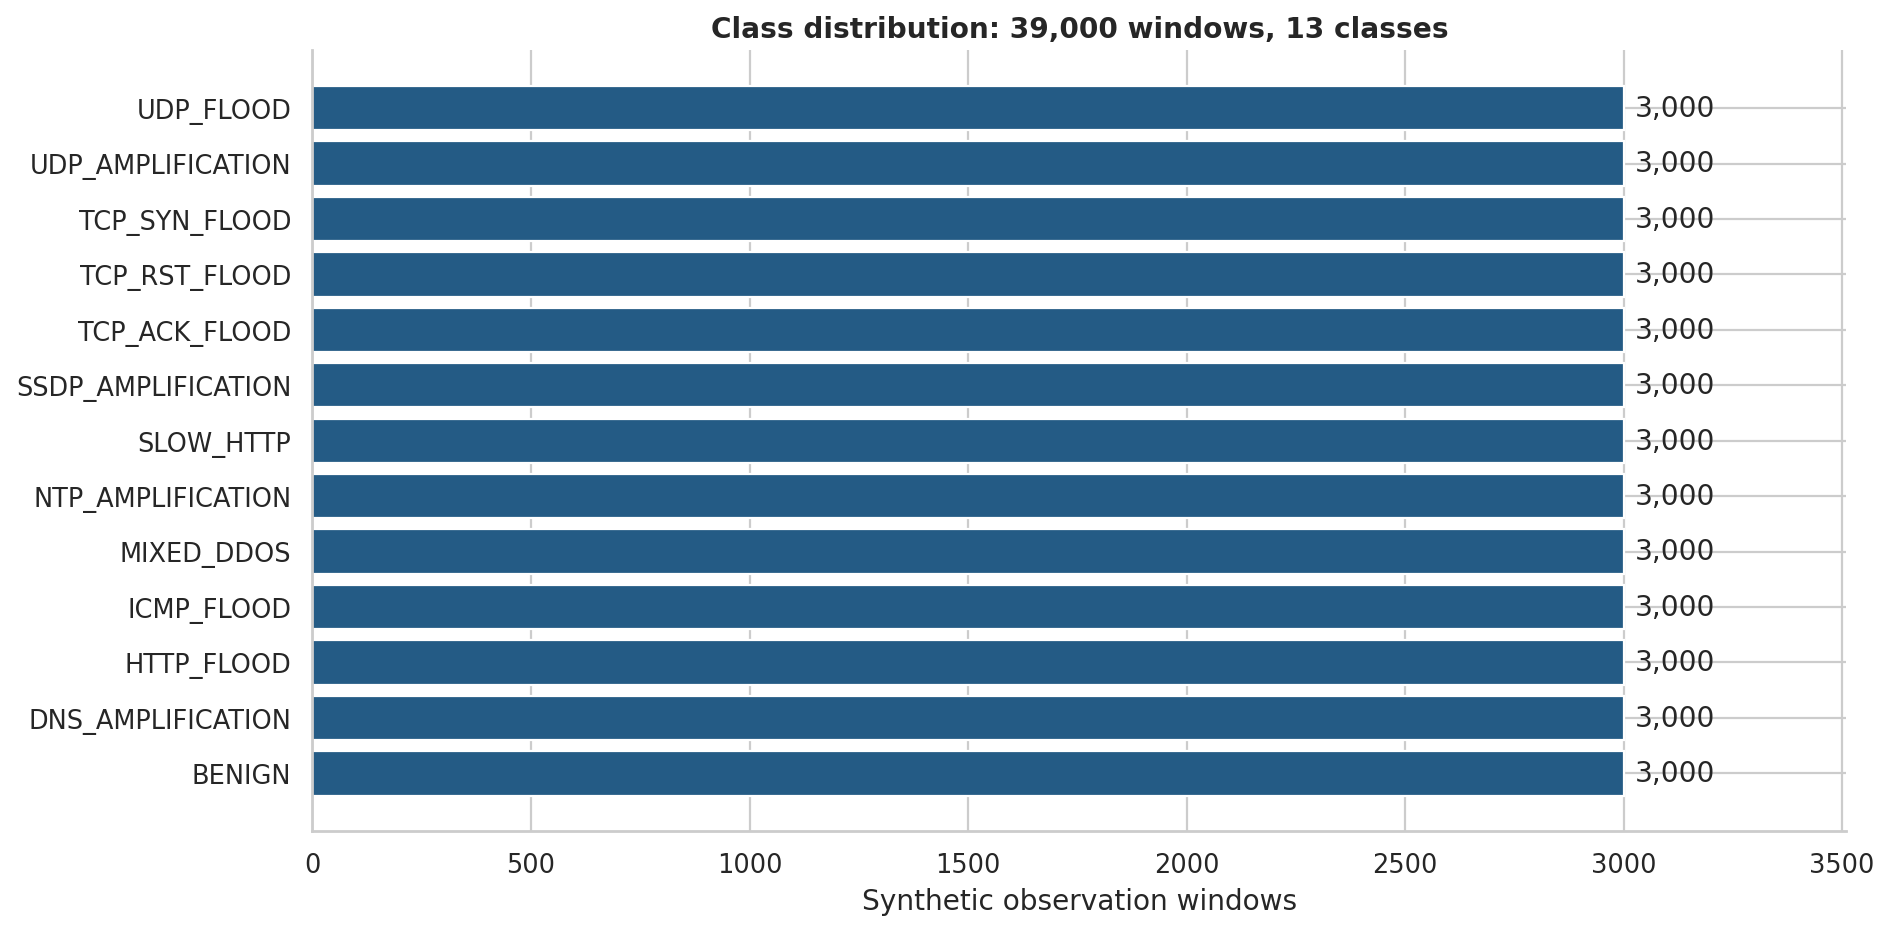

In [5]:
show_figure('01_class_distribution')

### 4.2 Family, protocol and service context

Protocol and application are fixed by scenario definitions here. They are useful for describing the dataset but excluded from the model to reduce scenario shortcuts.

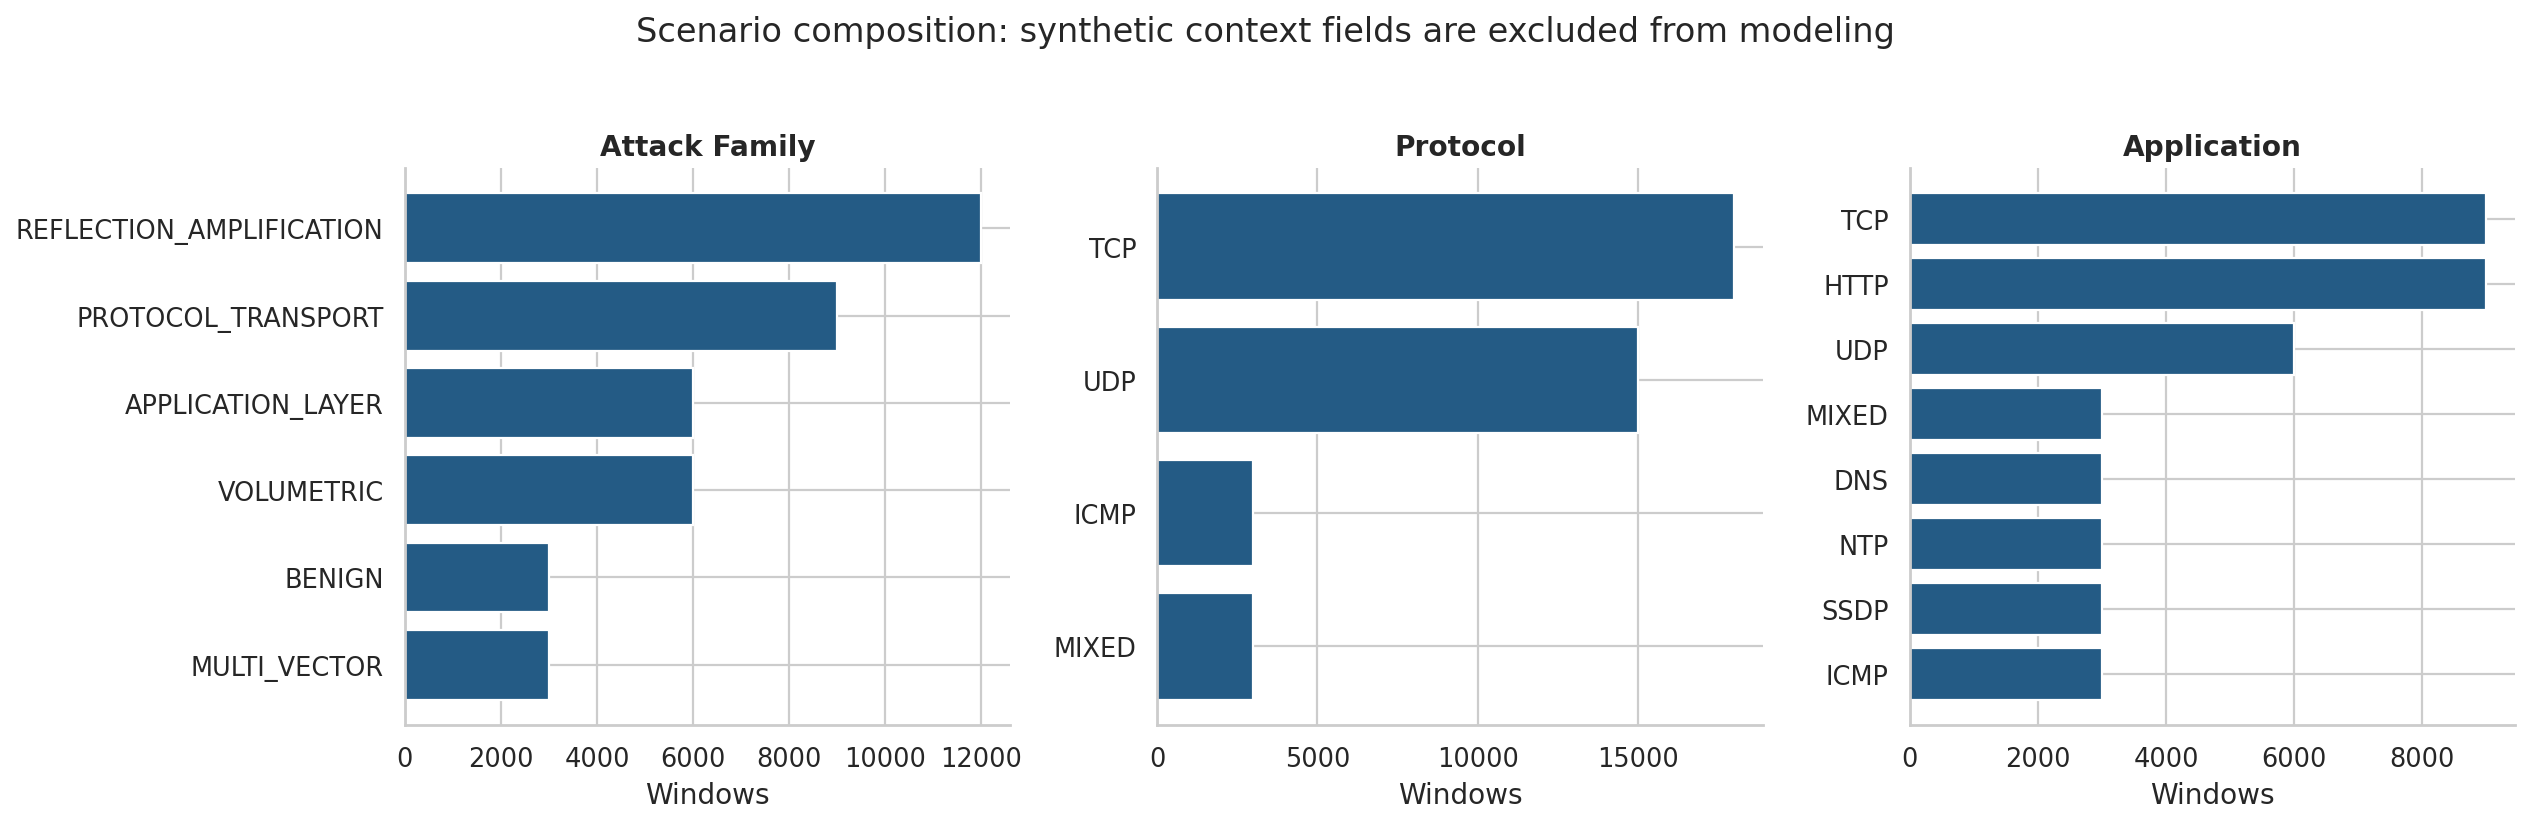

In [6]:
show_figure('02_context_distribution')

### 4.3 Time and identifier leakage

The generator emits class blocks in sequence. Time, sequence and scenario-coded IDs could reveal the label. A chronological split here would also omit entire classes from training; it is not a meaningful deployment test.

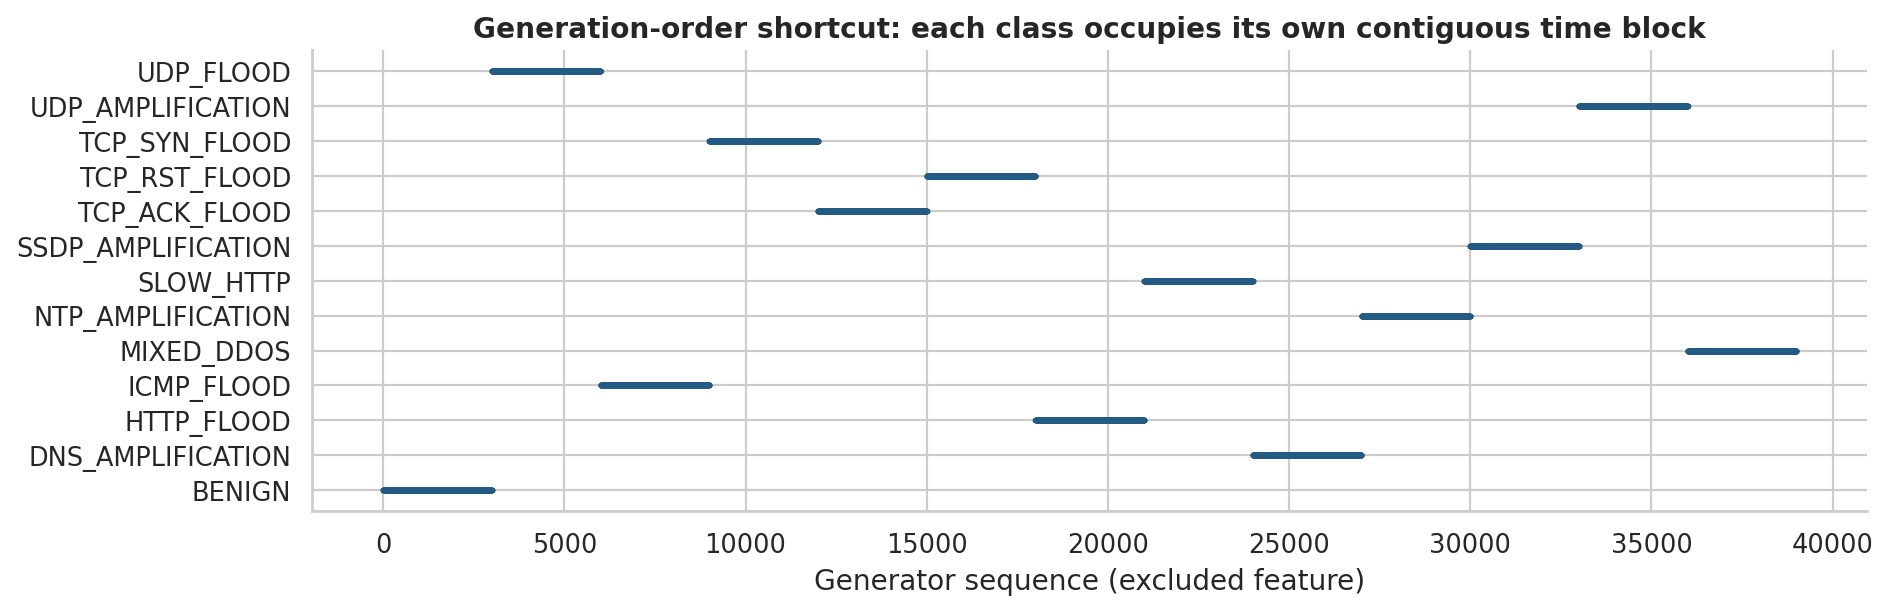

In [7]:
show_figure('03_time_leakage')

### 4.4 Traffic behavior by class

Read the median, interquartile range and overlap, not only extreme rates. Log axes are labelled. Similar amplification classes can have overlapping behavior despite distinct labels.

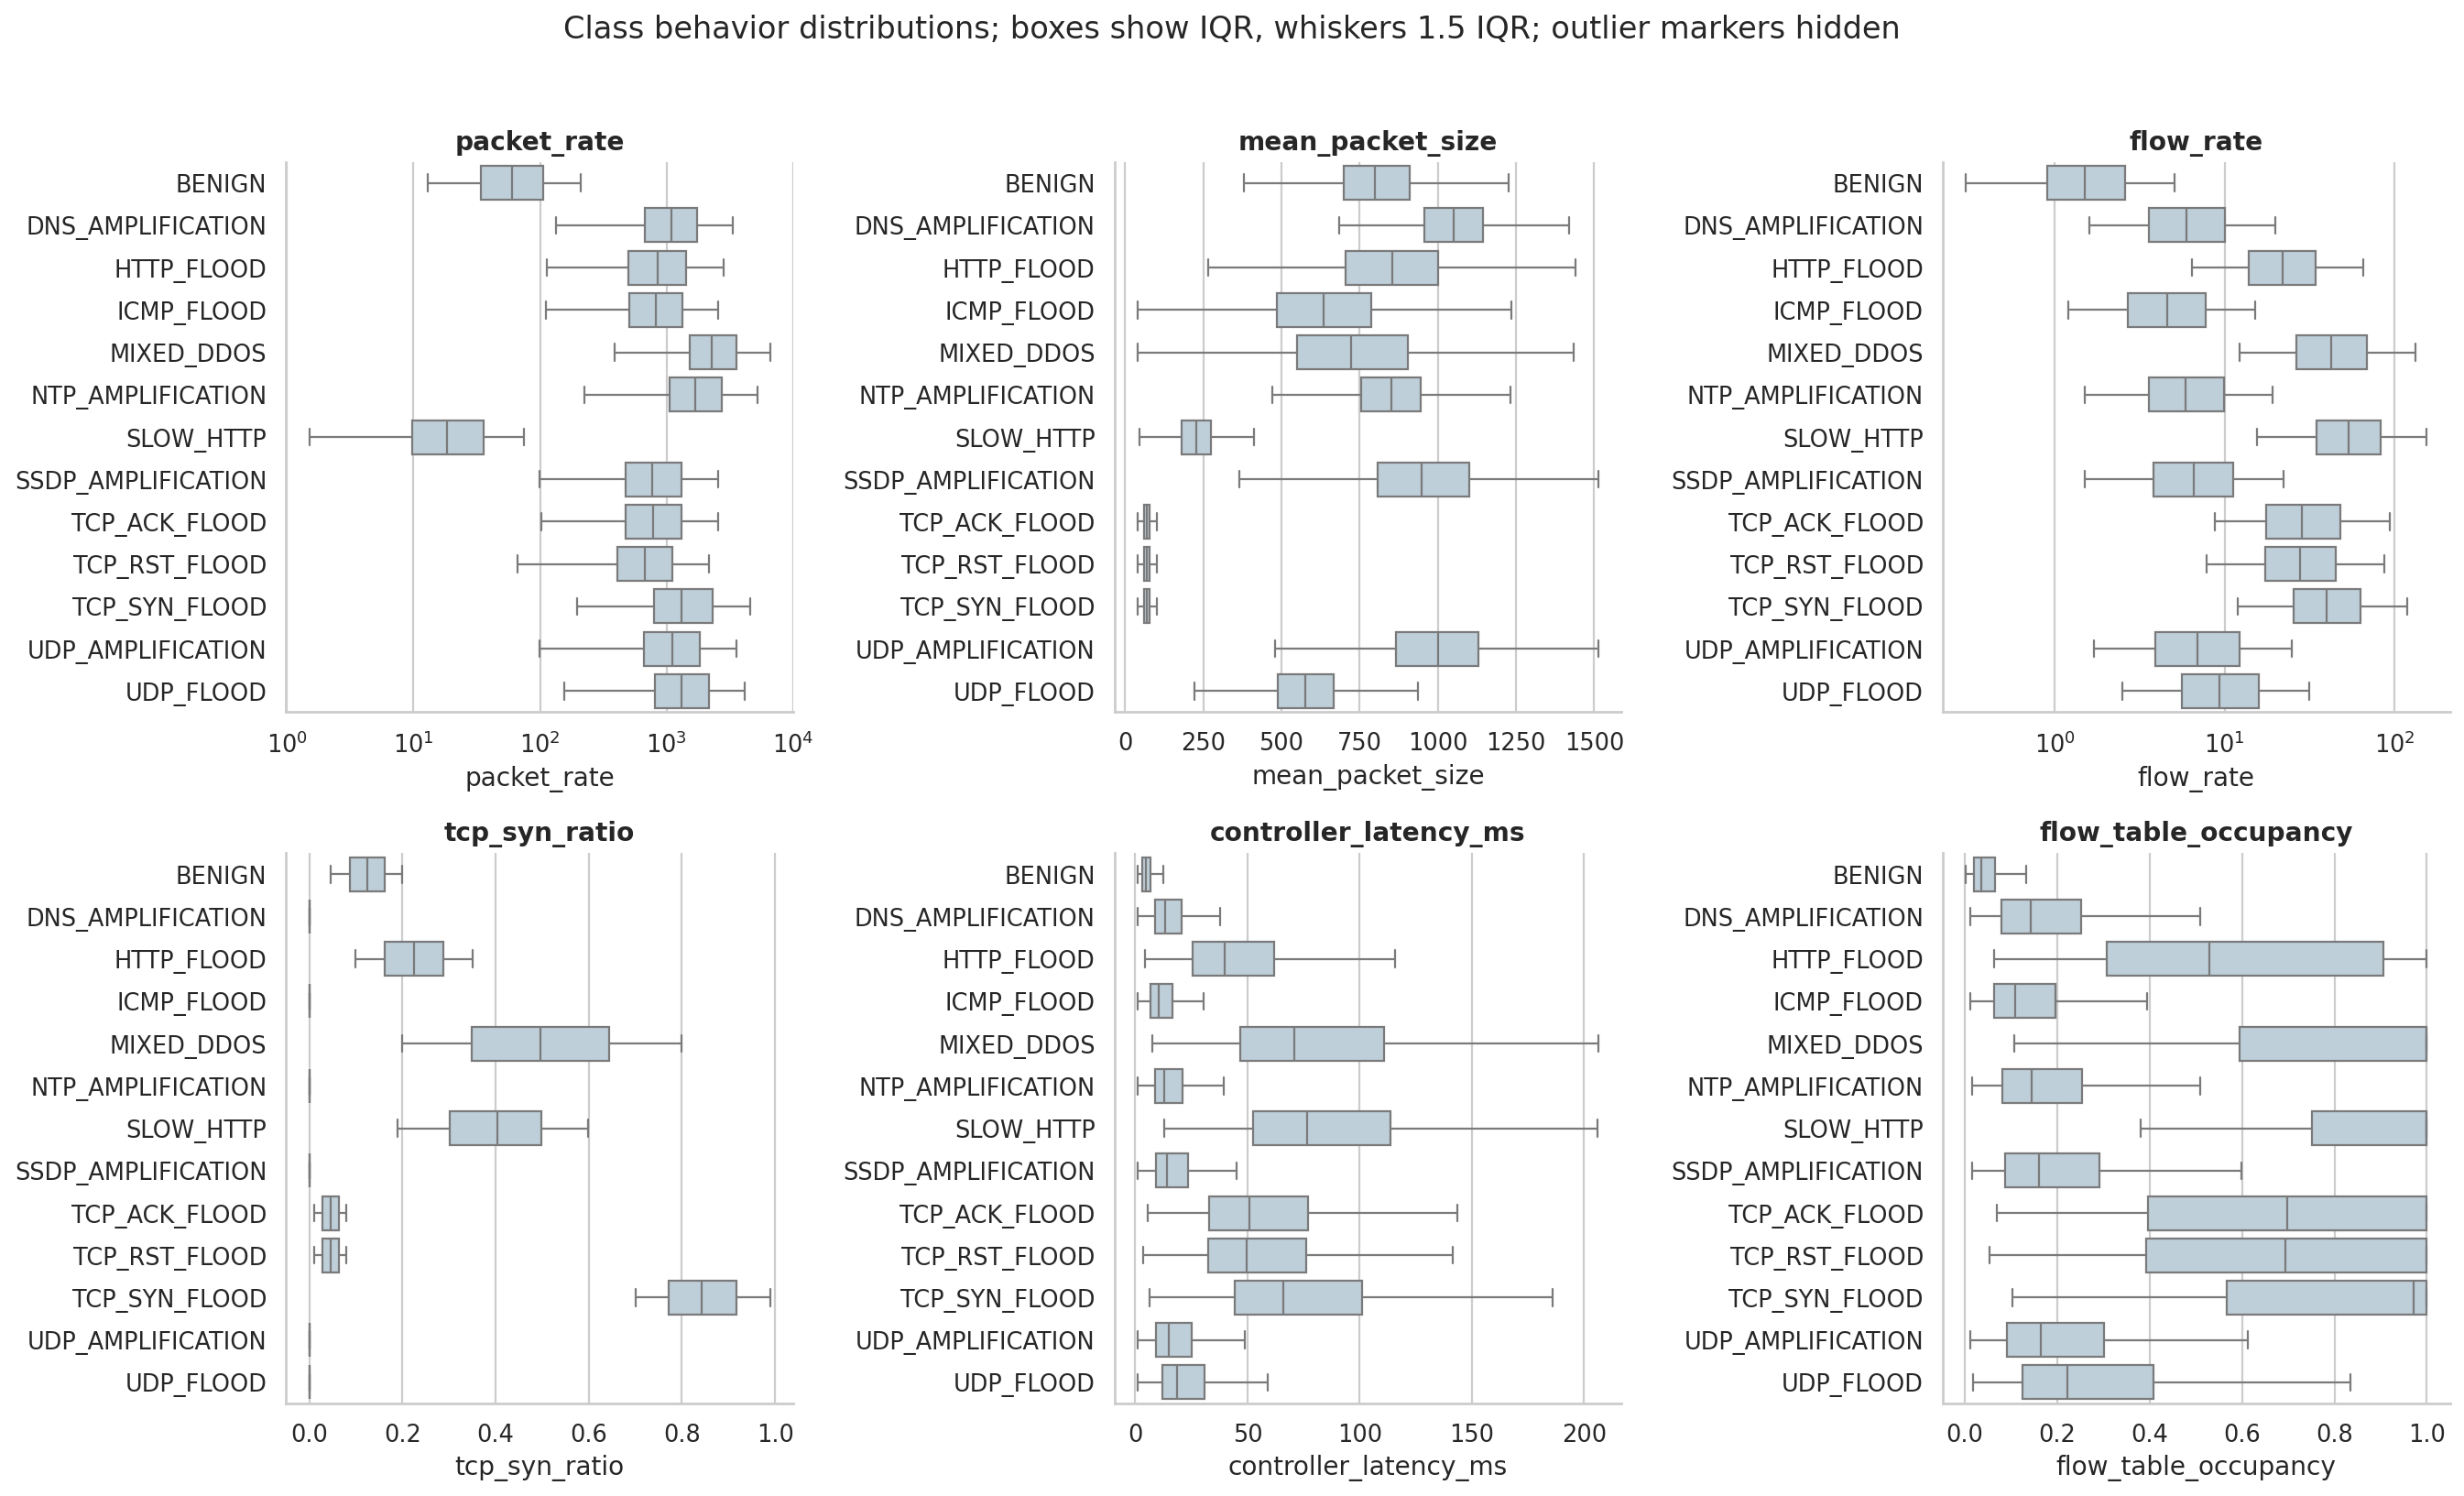

In [8]:
show_figure('04_behavior_boxplots')

### 4.5 Correlation and redundancy

Packet counts and rates share a formula with fixed window length. Correlated inputs violate naive Bayes independence and can overweight distances in KNN. A correlation is not proof of cause.

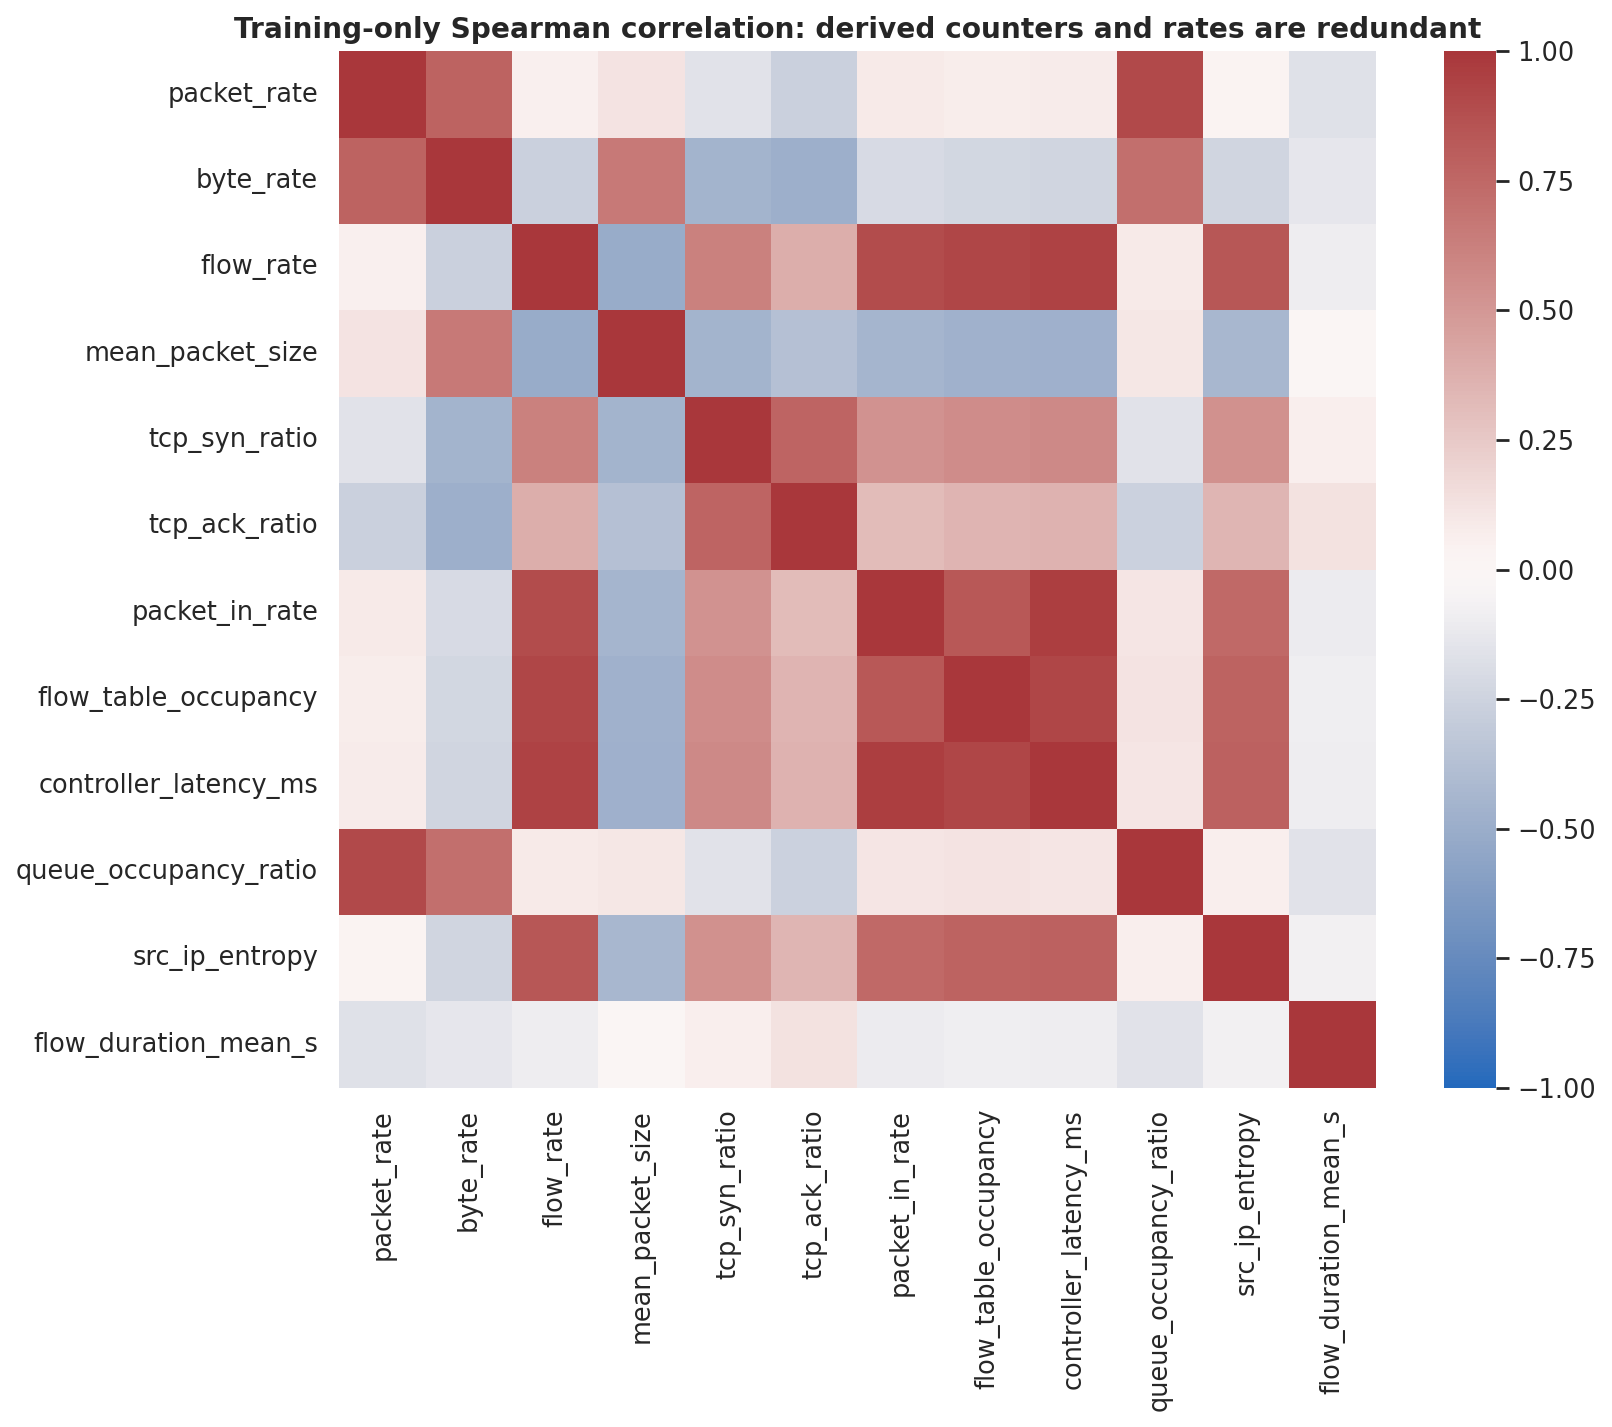

In [9]:
show_figure('05_correlation')

### 4.6 Low-rate attacks and overlap

Slow HTTP can have low packet volume yet high flow pressure. A single packets-per-second threshold is therefore a weak universal attack detector.

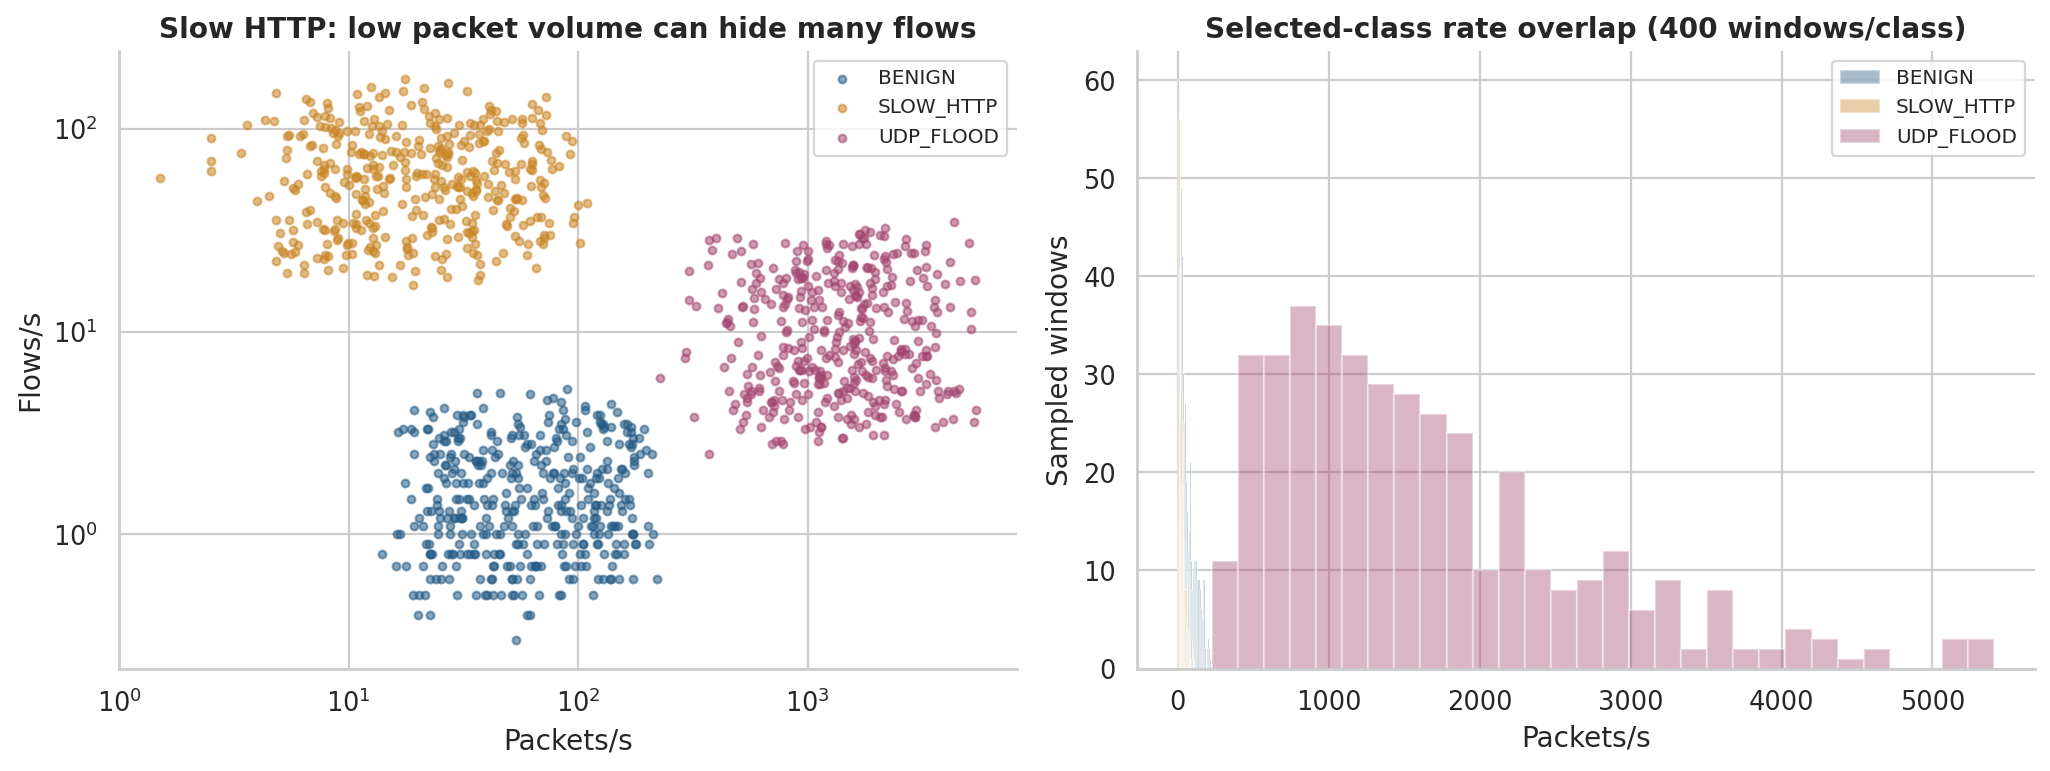

In [10]:
show_figure('06_overlap_scatter')

### 4.7 Missingness and physical inconsistencies

The audit preserves synthetic artifacts instead of silently correcting their meaning. Flow table occupancy is clipped; link utilization assumes 1 Gbit/s while old topology prose says 100 Mbit/s. ACK/SYN is not a measured completion fraction.

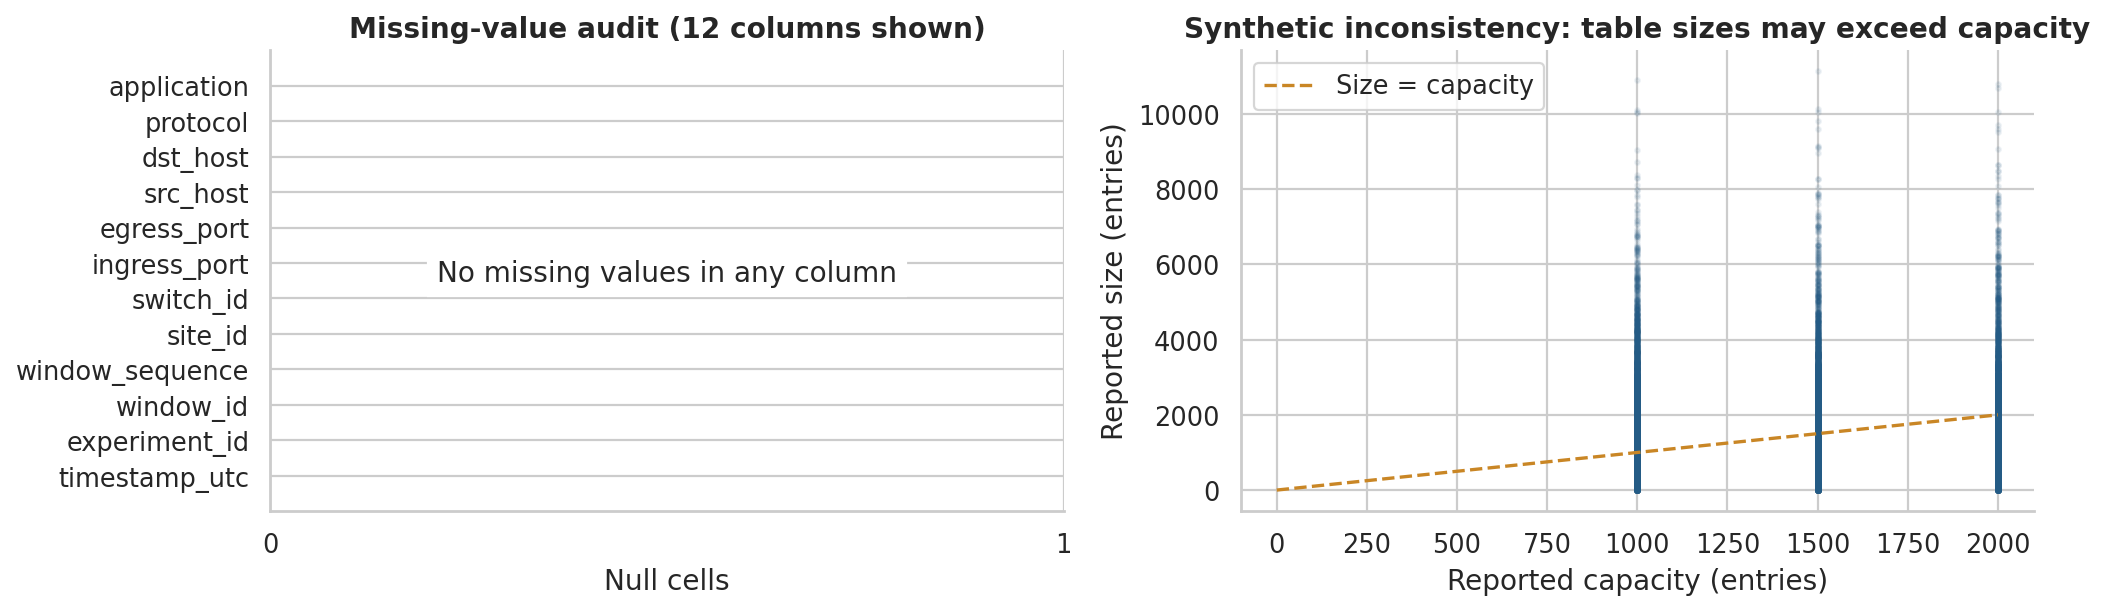

In [11]:
show_figure('09_data_quality')

### 4.8 Distribution atlas: every retained numeric feature

These five pages cover all 40 inputs. Benign and attack groups are normalized separately,
so their densities can be compared despite the 3,000 versus 36,000 support difference.
All finite values are retained in the plotted ranges. The dictionary gives units and generated
meaning. This is descriptive EDA, not a test-driven feature-selection procedure.

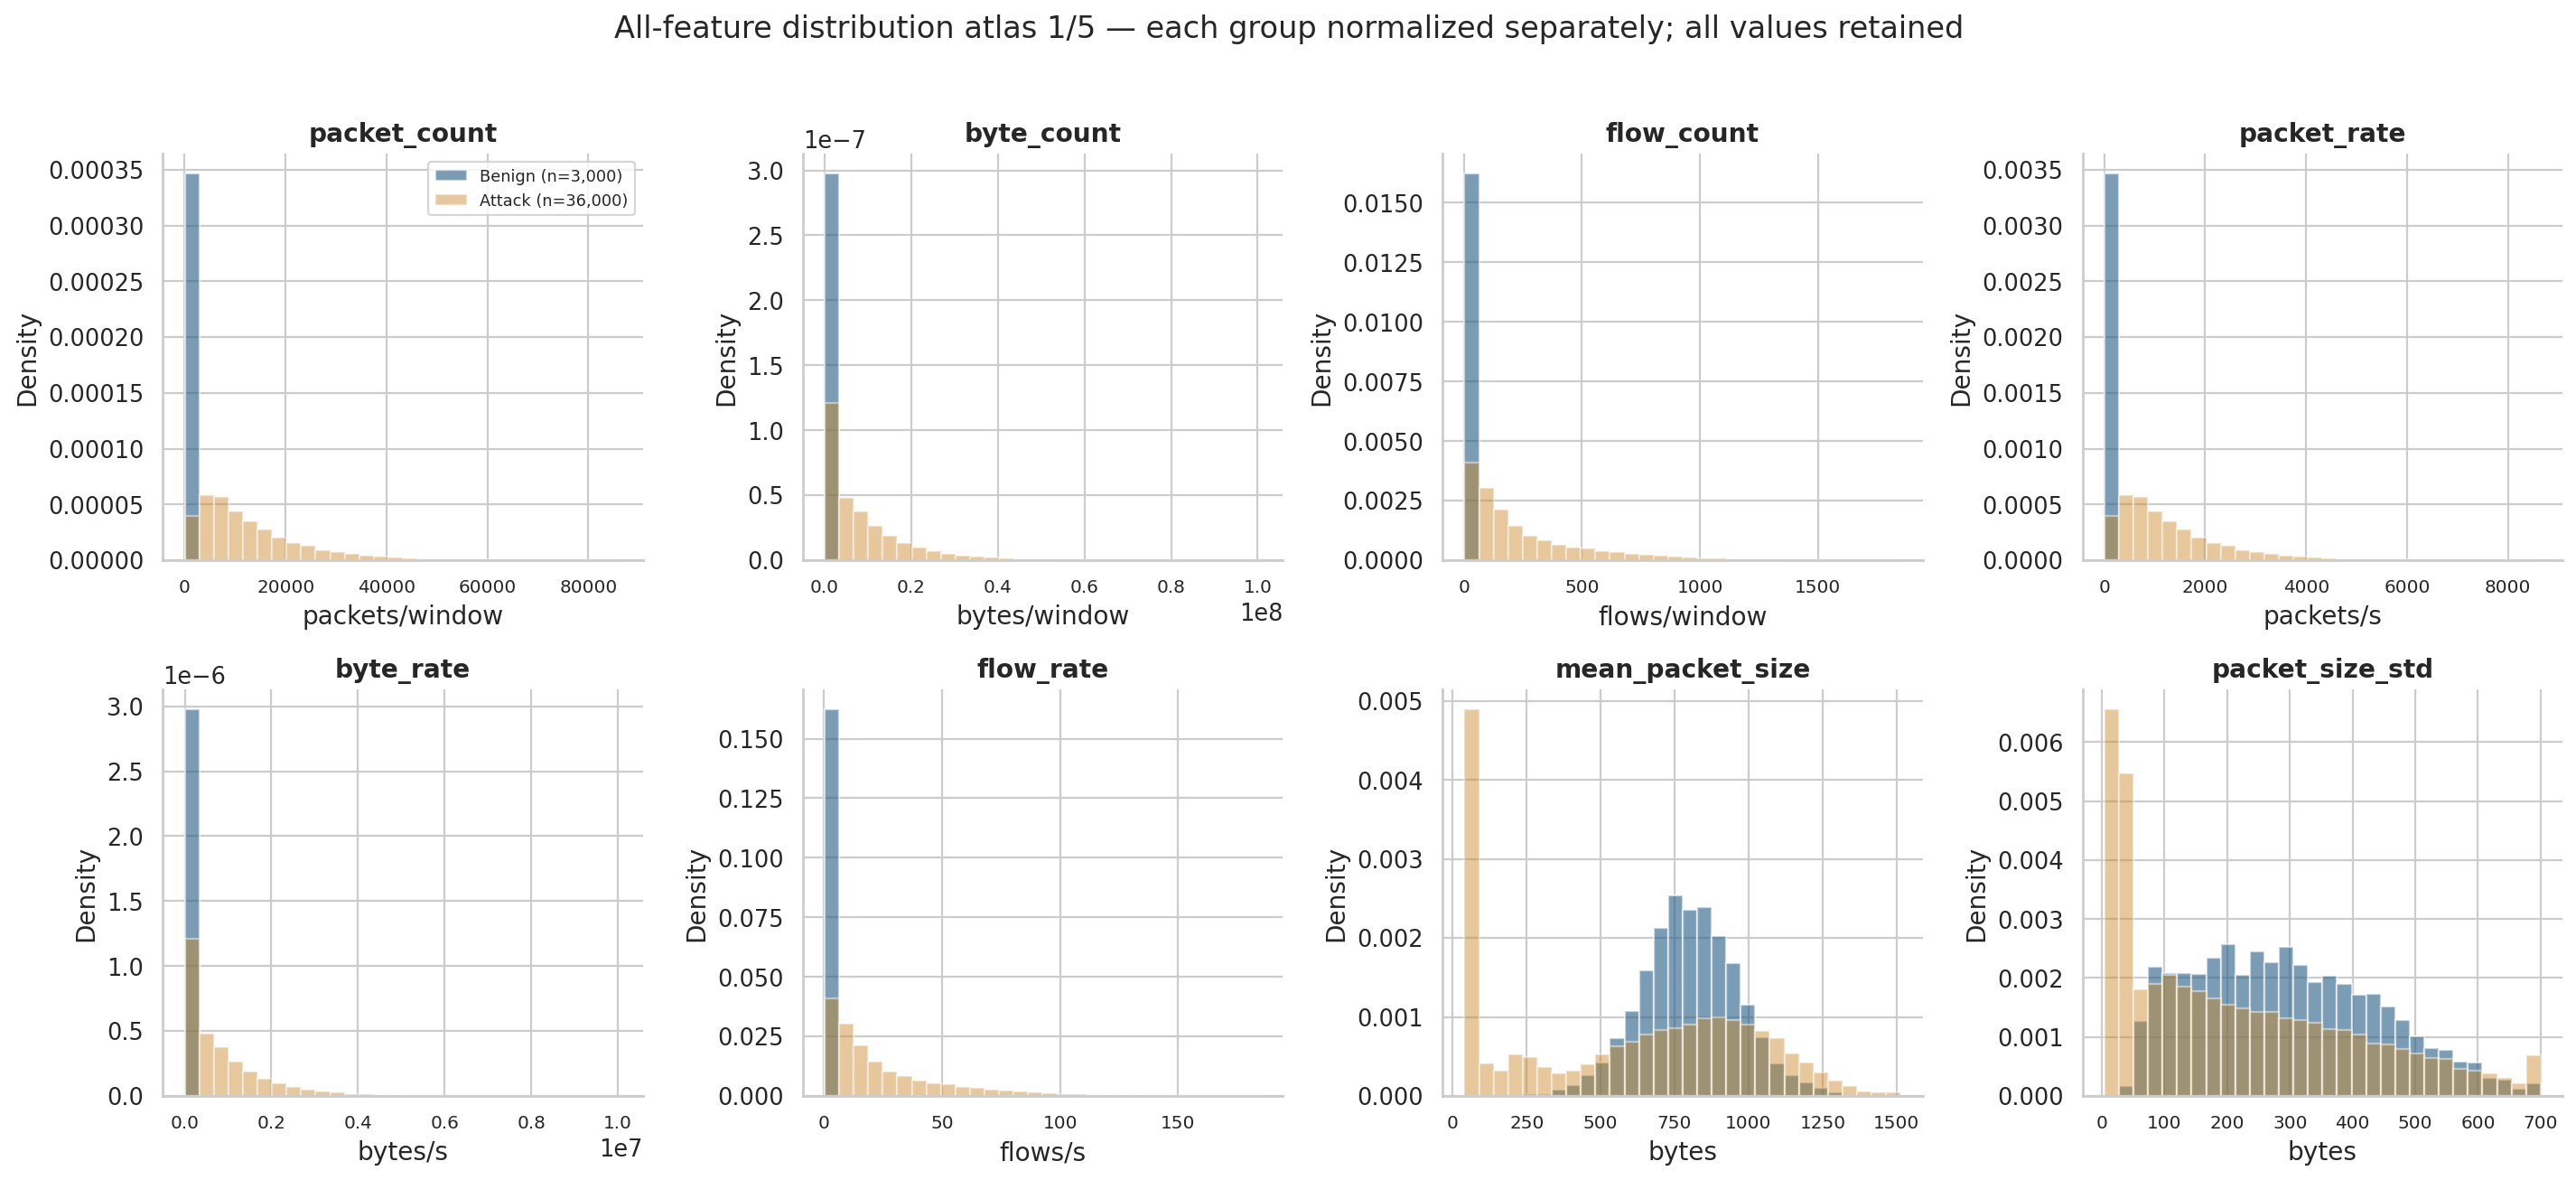

In [12]:
show_figure('atlas_1')

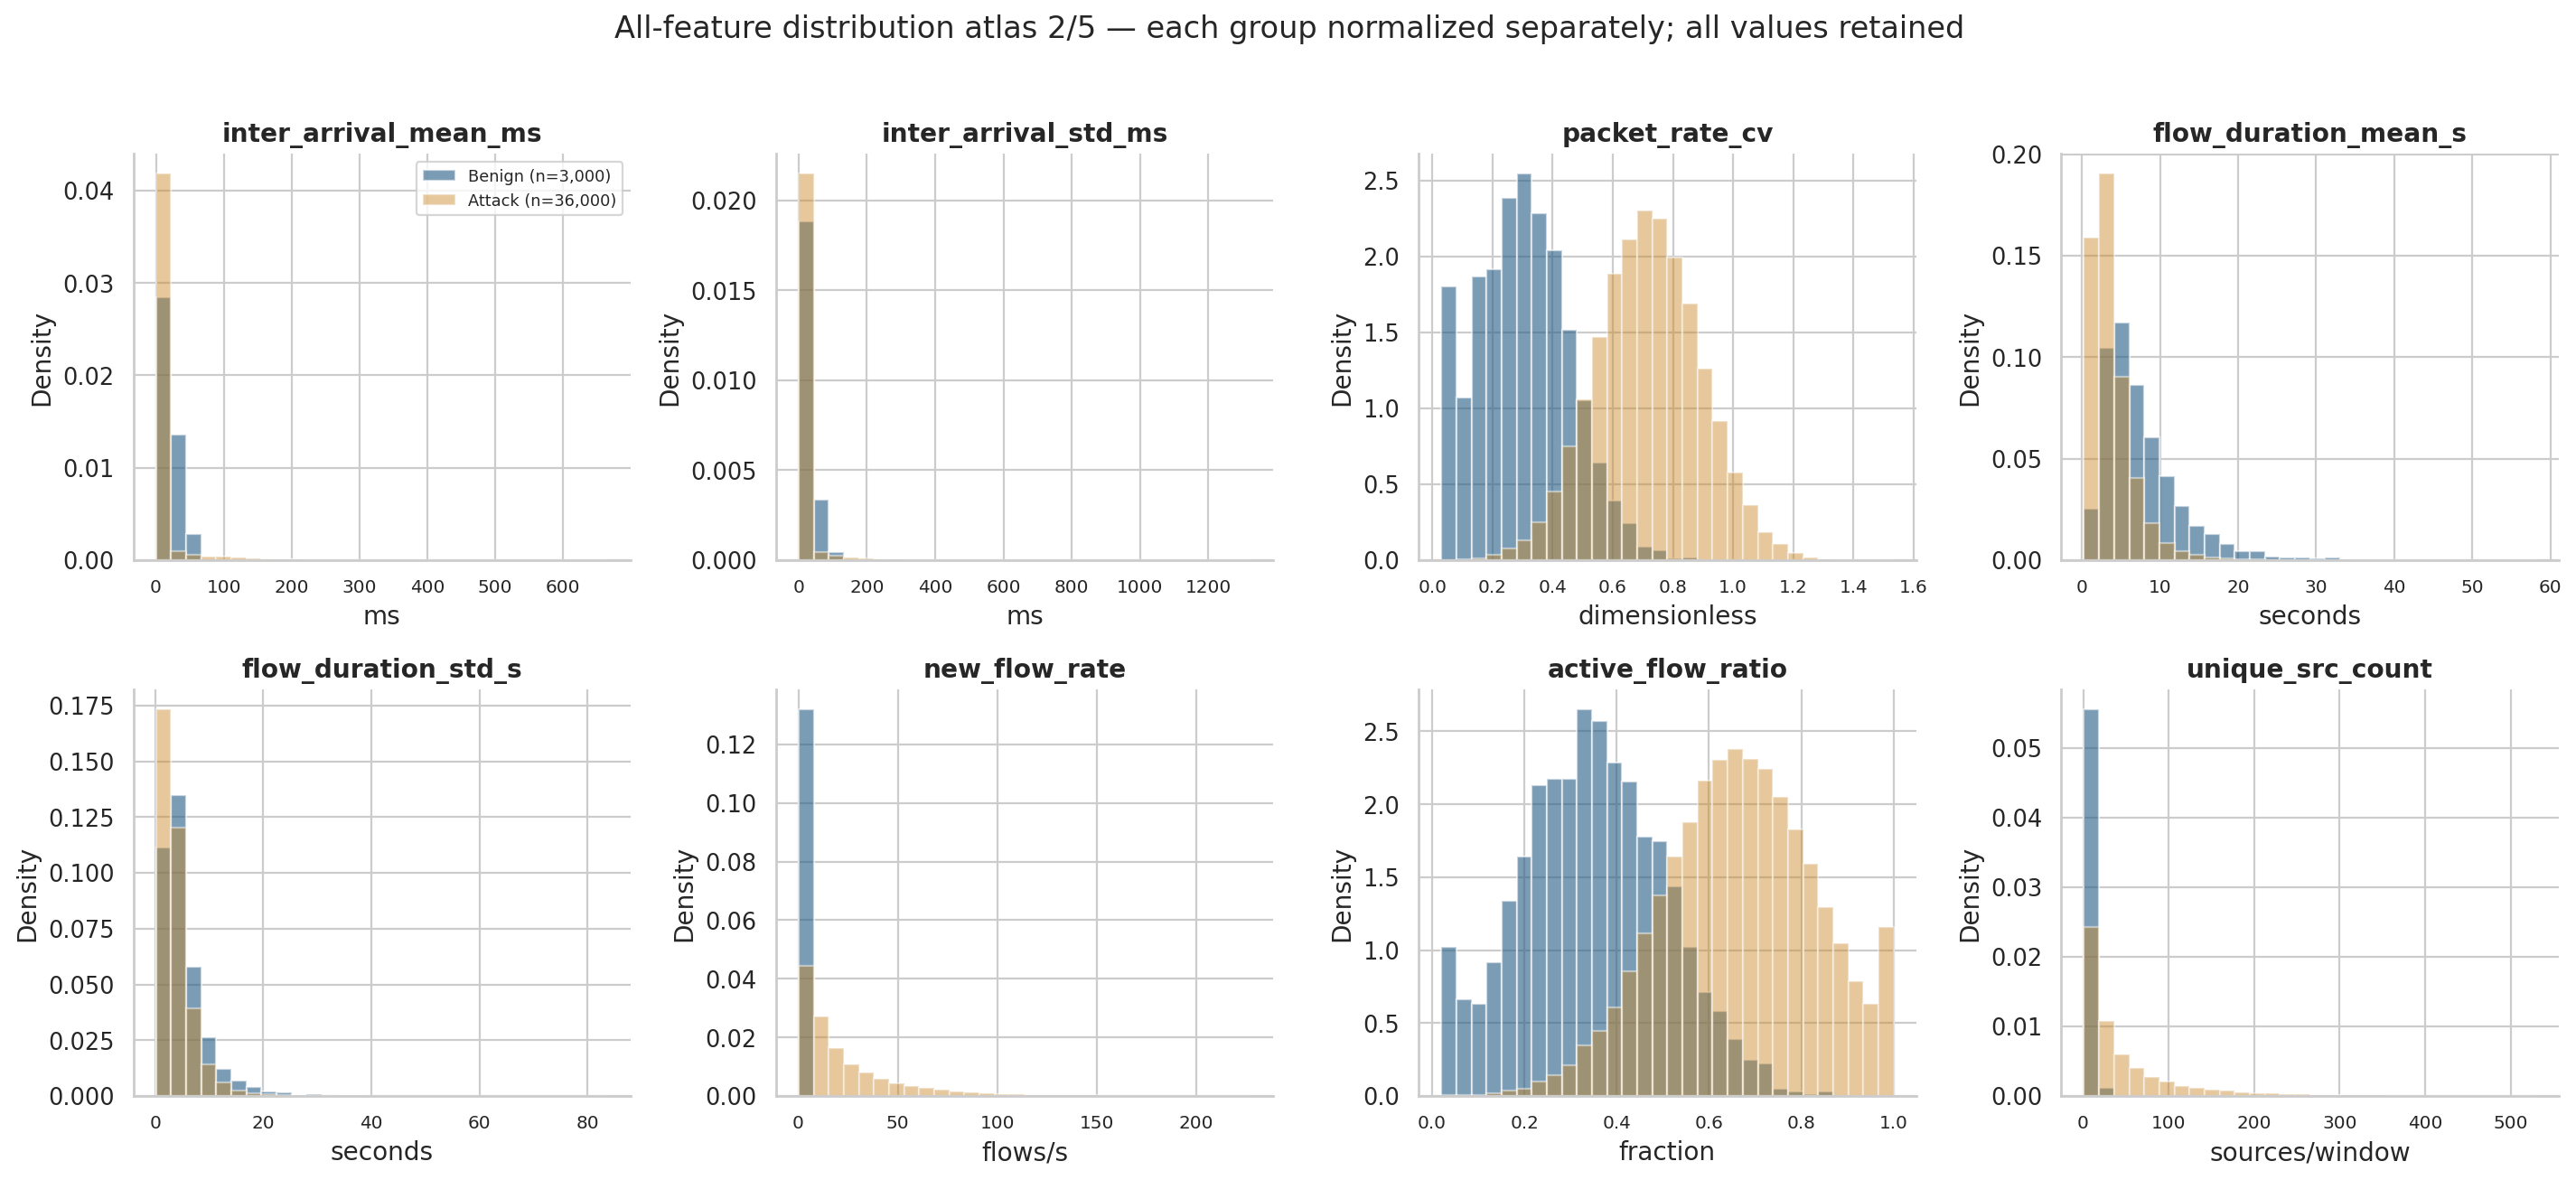

In [13]:
show_figure('atlas_2')

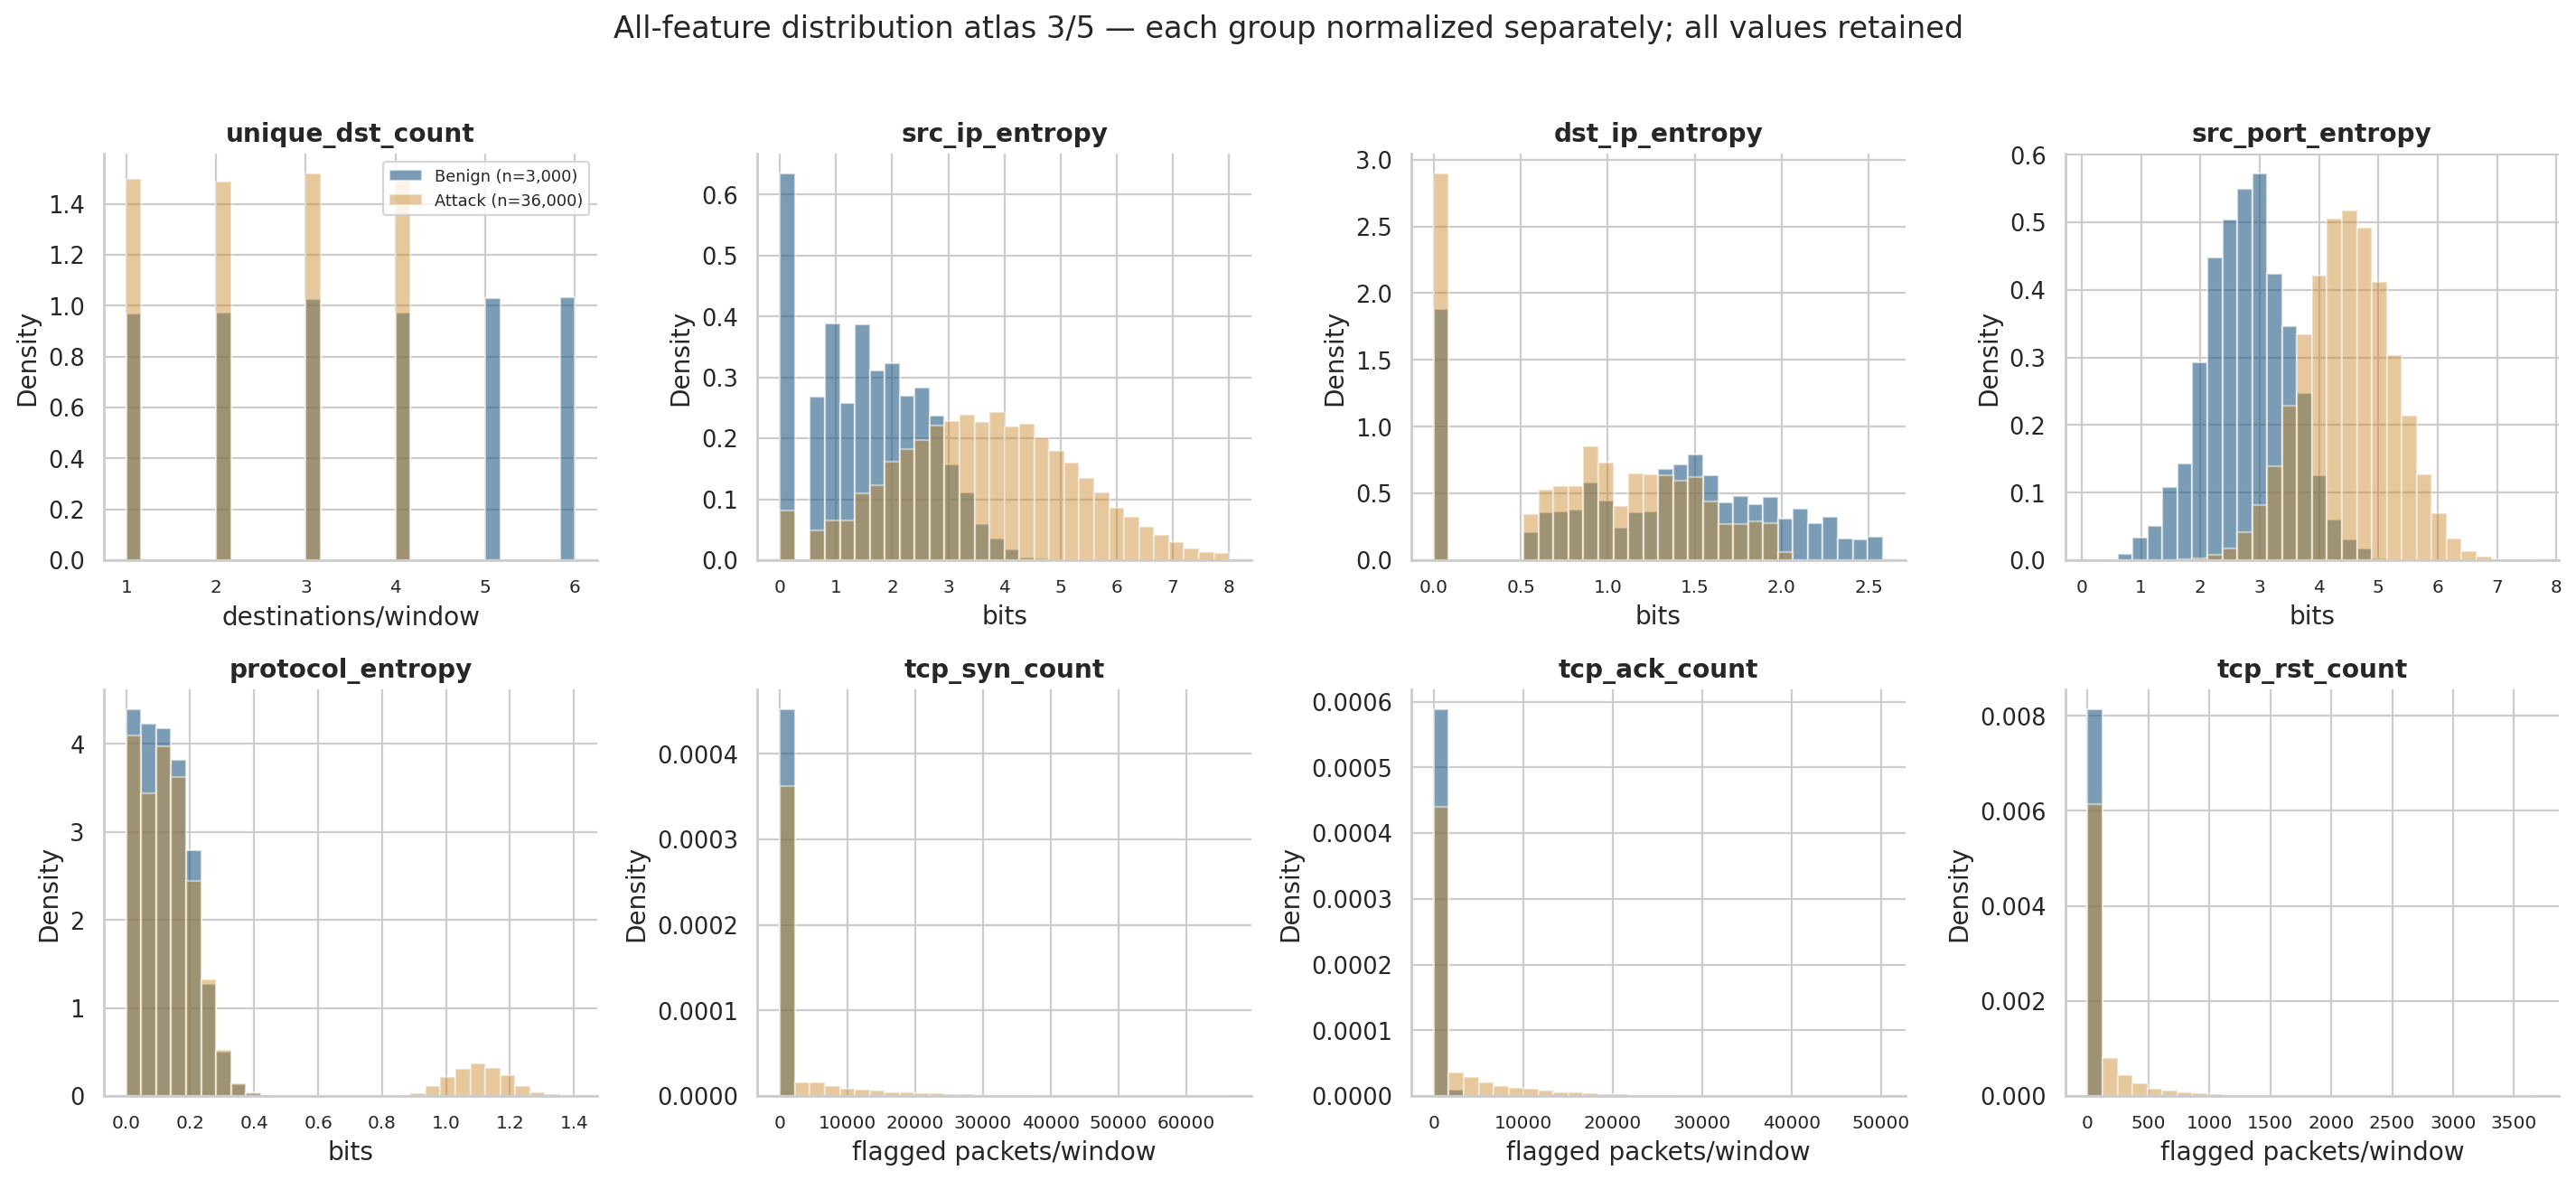

In [14]:
show_figure('atlas_3')

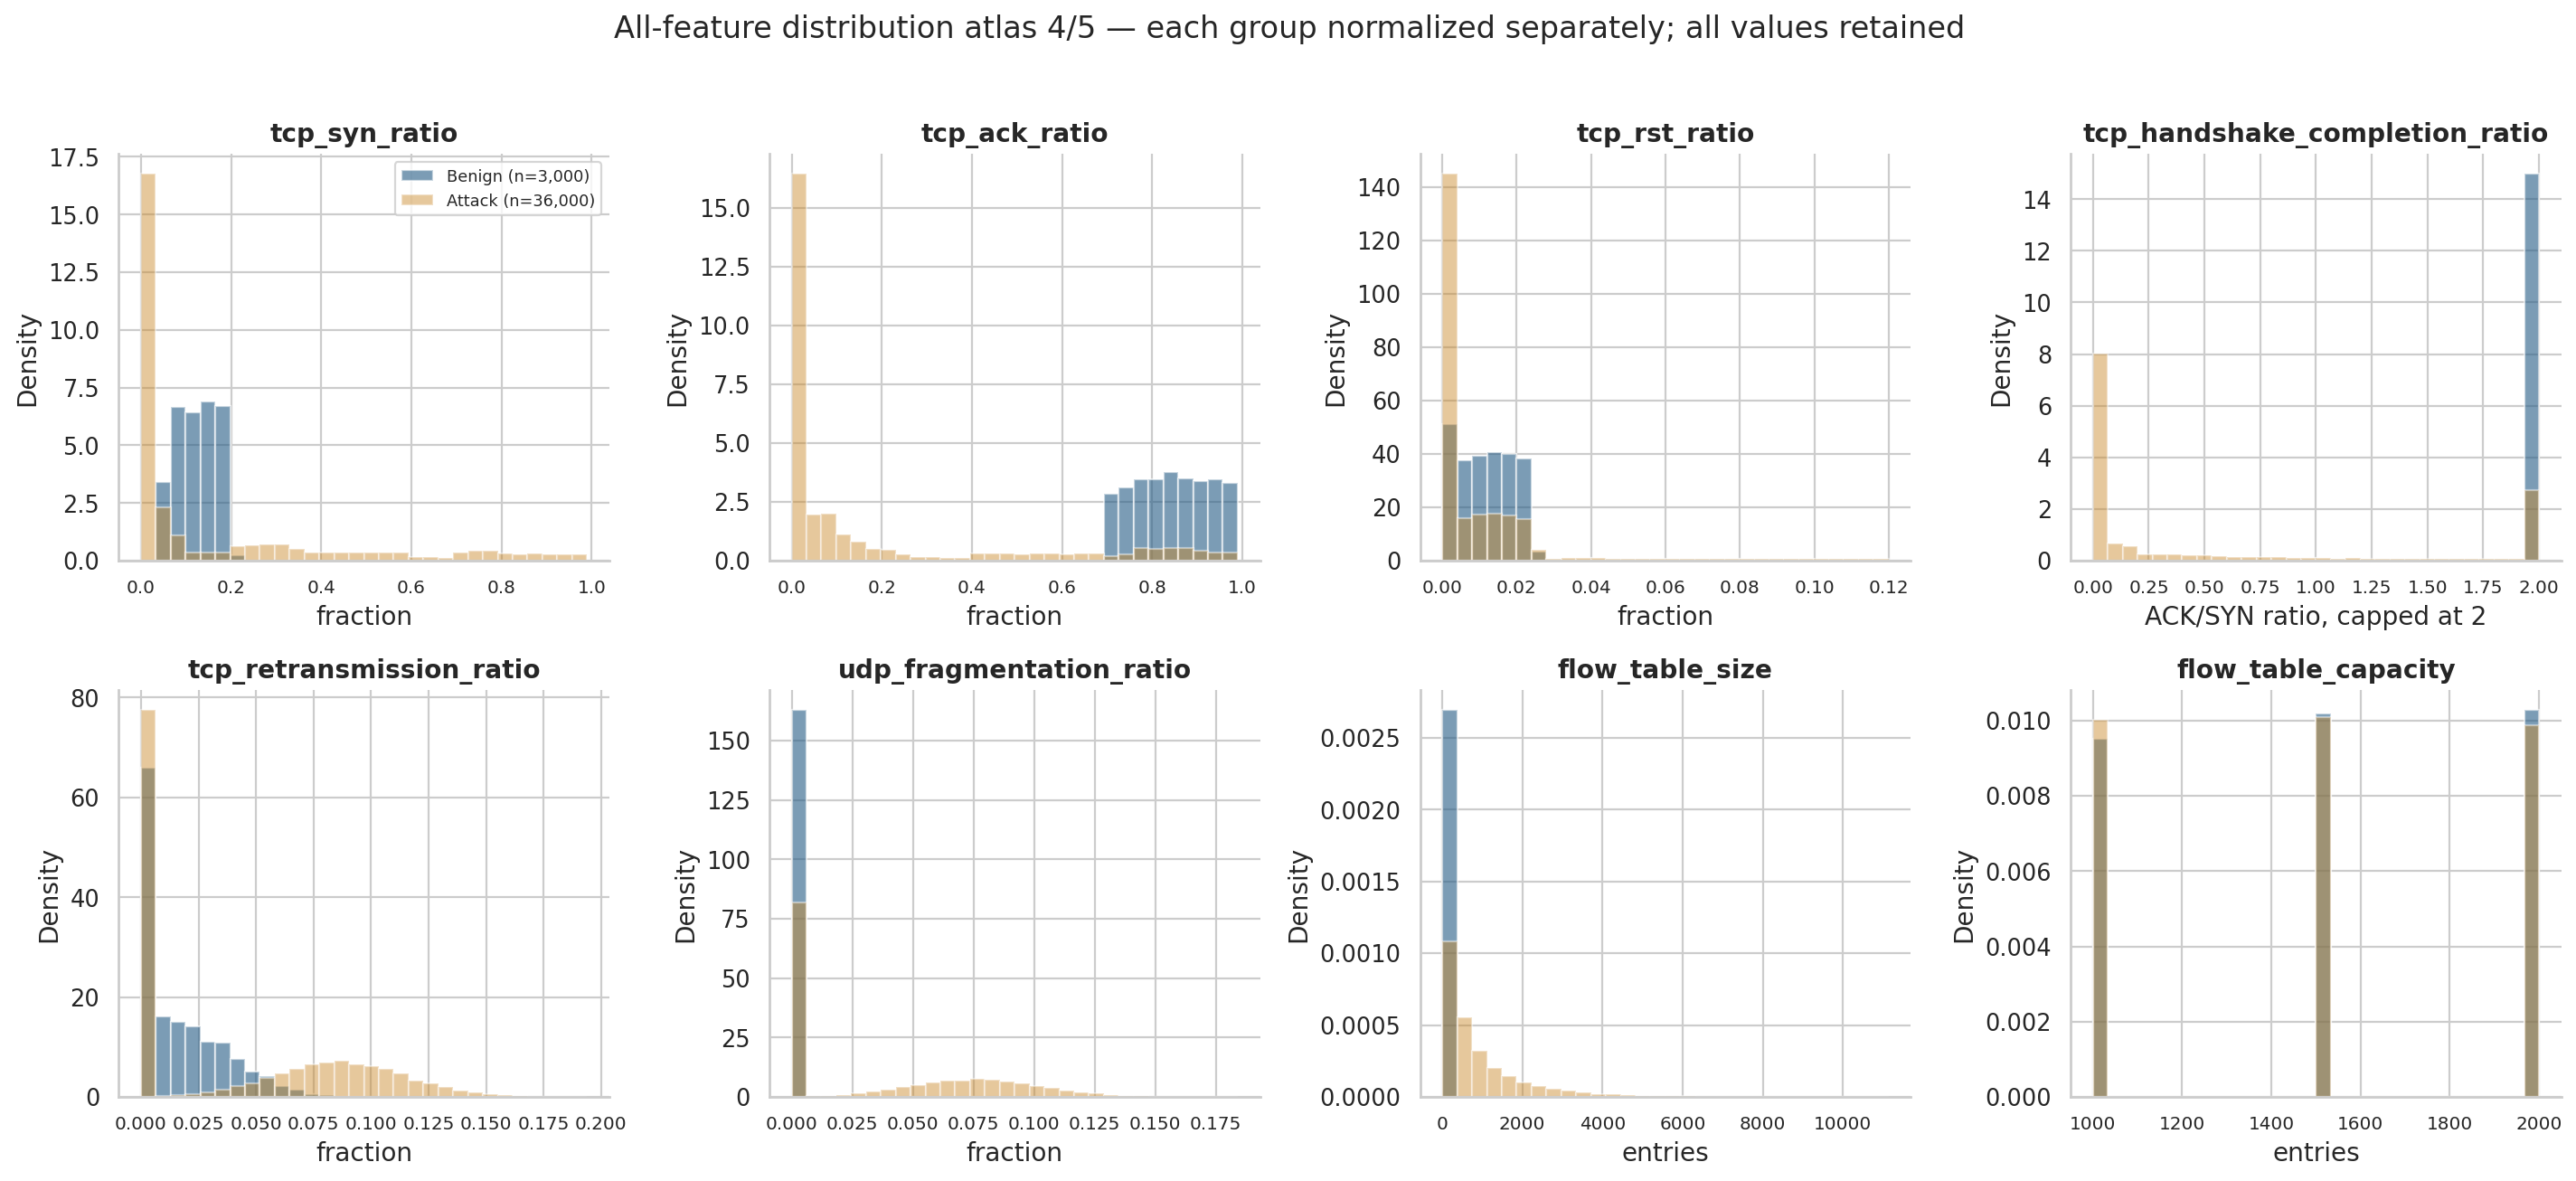

In [15]:
show_figure('atlas_4')

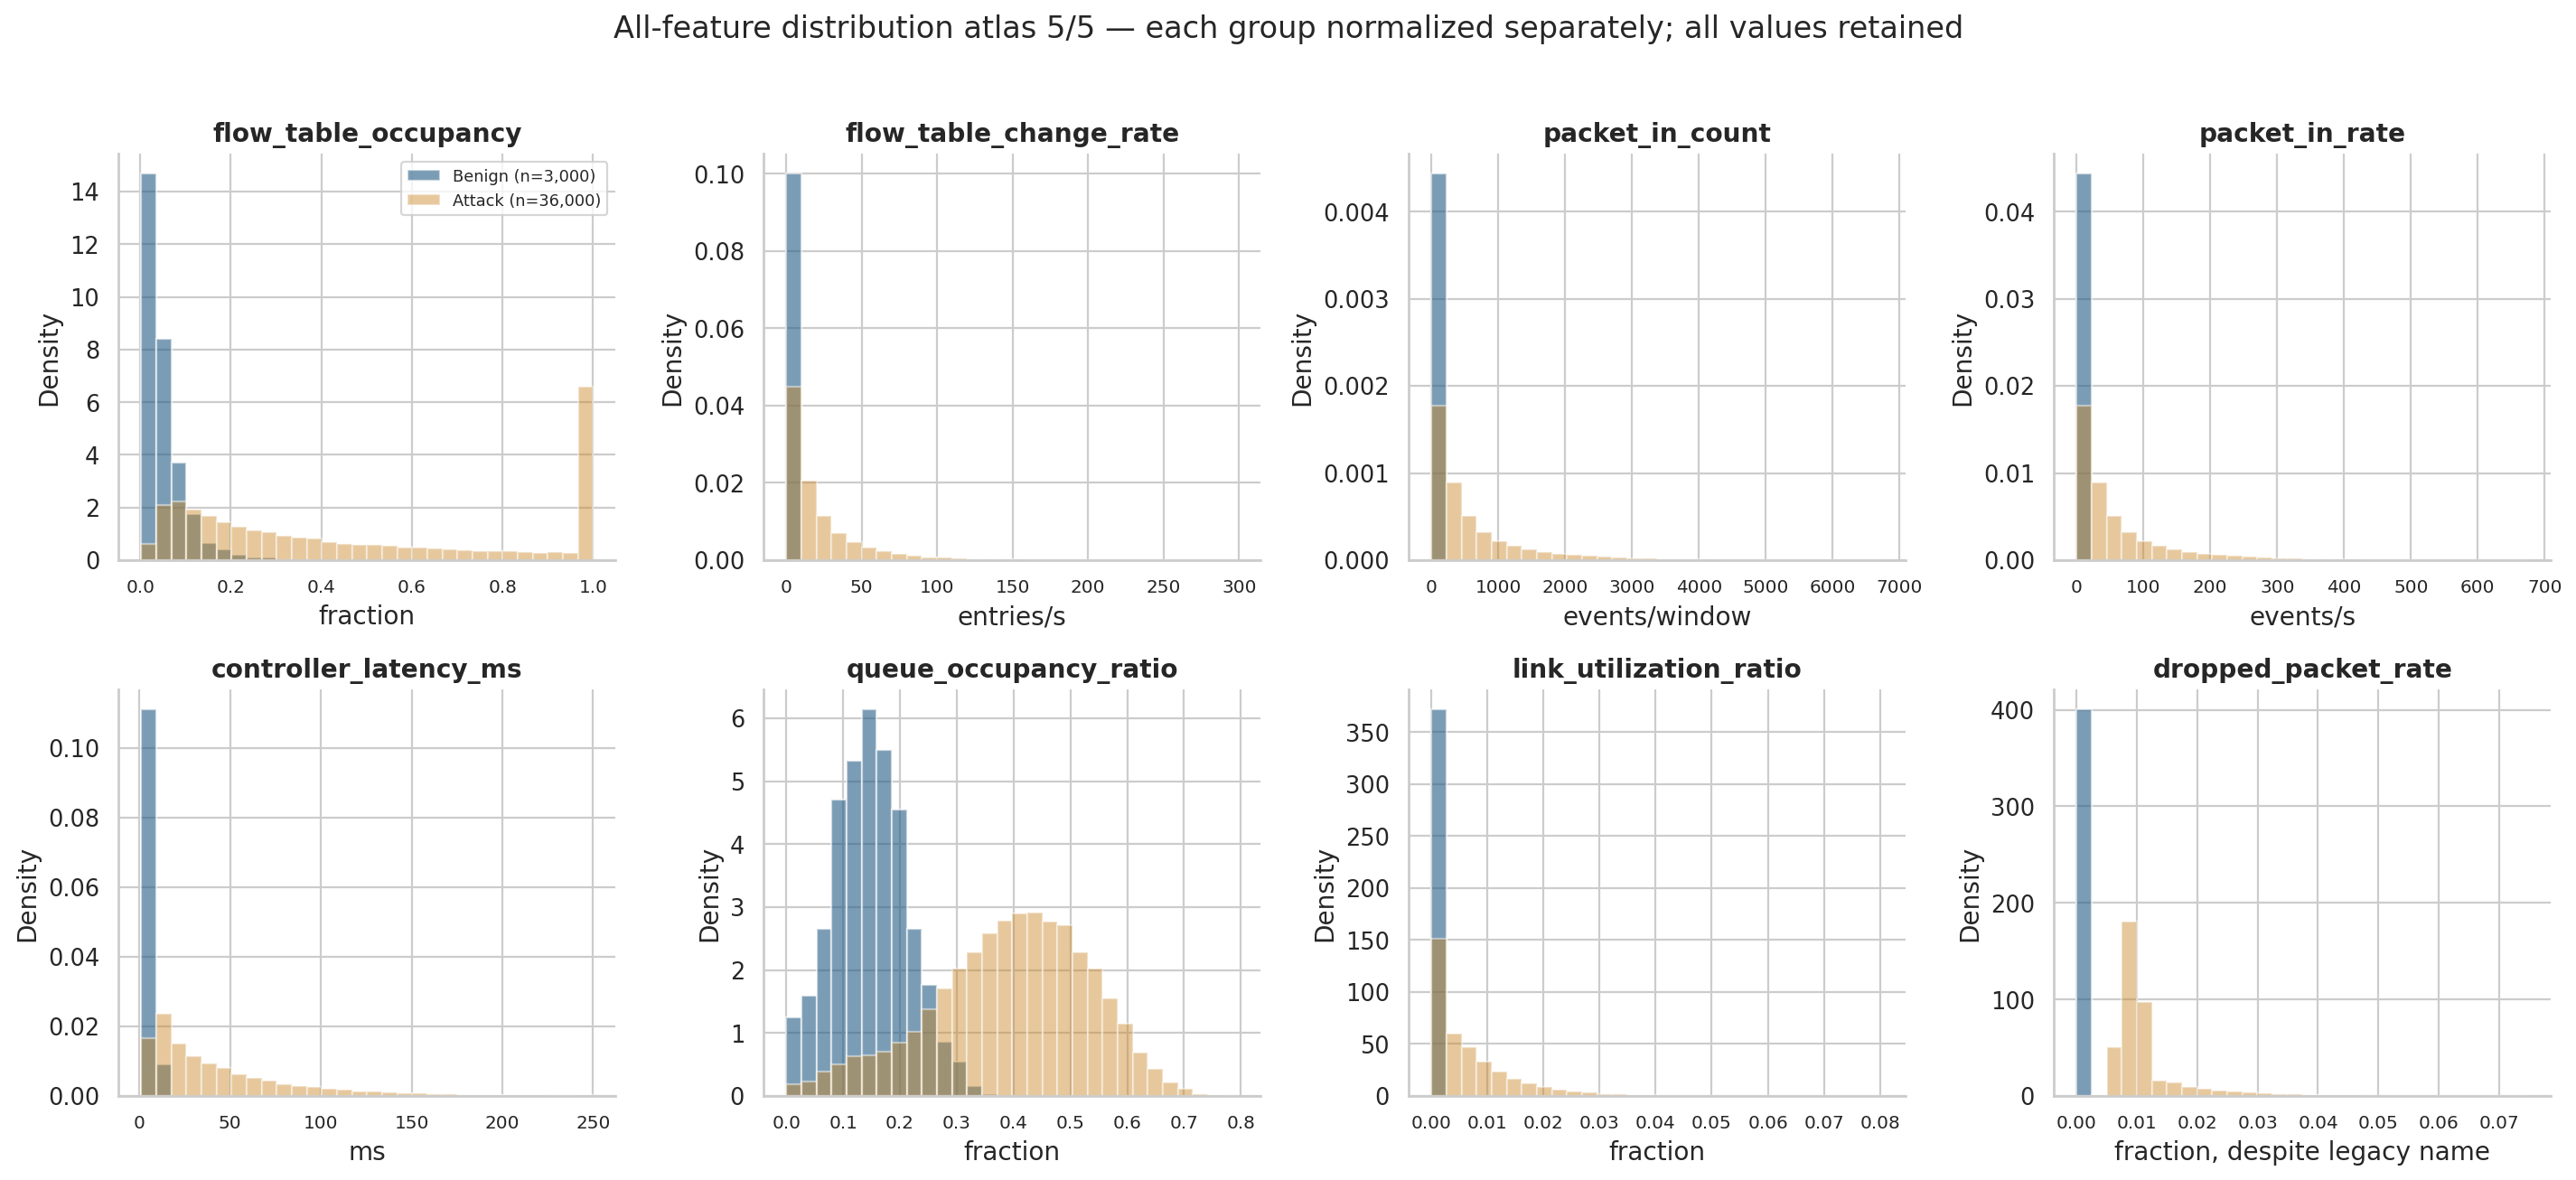

In [16]:
show_figure('atlas_5')

## 5. Preprocessing and leakage prevention

1. Remove identifiers, labels/families, synthetic generation controls, scenario protocol/application,
   random switch/site/port identities and the explicit controller CPU proxy.
2. Save a stratified 70% train / 15% validation / 15% test split with seed 42.
3. Assert no row overlap and no identical retained feature vectors across partitions.
4. Determine all-null/constant features from training rows only; drop them.
5. Fit Spark `Imputer(strategy='median')` on training only, followed by `VectorAssembler` and
   `StandardScaler(withMean=True, withStd=True)`. Spark uses sample standard deviation.
6. Reuse the fitted preprocessing unchanged on validation and test. Export the exact medians,
   means and standard deviations and check Python transformation parity.

For $x_j$, standardization is $z_j=(x_j-\mu_{j,train})/s_{j,train}$.
Do not remove high-rate windows merely because they are outliers; those may be the attacks.
No SMOTE is applied because the current classes are balanced. If future data is imbalanced,
resampling must happen inside the training split only.

,column,dtype,missing,unique,use,reason
0,timestamp_utc,object,0,39000,excluded,class-ordered generation time
1,experiment_id,object,0,1,excluded,experiment identifier
2,window_id,object,0,39000,excluded,encodes scenario index
3,window_sequence,int64,0,39000,excluded,class-ordered sequence
4,site_id,object,0,4,excluded,random site identity
5,switch_id,object,0,6,excluded,random switch identity
6,ingress_port,int64,0,8,excluded,random port identity
7,egress_port,int64,0,8,excluded,random port identity
8,src_host,object,0,48,excluded,c/a prefix directly exposes benign/attack
9,dst_host,object,0,4,excluded,host context


,column,unit,meaning
15,packet_count,packets/window,Generated total packets in the observation win...
16,byte_count,bytes/window,Integer packet count multiplied by generated m...
17,flow_count,flows/window,"Generated count of flows, not observed five-tu..."
18,packet_rate,packets/s,packet_count divided by window_seconds.
19,byte_rate,bytes/s,packet_rate multiplied by mean_packet_size.
20,flow_rate,flows/s,flow_count divided by window_seconds.
21,mean_packet_size,bytes,"Generated average packet size, clipped to 40....."
22,packet_size_std,bytes,Generated packet-size spread; not measured fro...
23,inter_arrival_mean_ms,ms,Derived as 1000 / packet_rate and clipped; red...
24,inter_arrival_std_ms,ms,Generated interval spread scaled by inverse pa...


Dropped training constants: ['window_seconds']
Retained feature order: ['packet_count', 'byte_count', 'flow_count', 'packet_rate', 'byte_rate', 'flow_rate', 'mean_packet_size', 'packet_size_std', 'inter_arrival_mean_ms', 'inter_arrival_std_ms', 'packet_rate_cv', 'flow_duration_mean_s', 'flow_duration_std_s', 'new_flow_rate', 'active_flow_ratio', 'unique_src_count', 'unique_dst_count', 'src_ip_entropy', 'dst_ip_entropy', 'src_port_entropy', 'protocol_entropy', 'tcp_syn_count', 'tcp_ack_count', 'tcp_rst_count', 'tcp_syn_ratio', 'tcp_ack_ratio', 'tcp_rst_ratio', 'tcp_handshake_completion_ratio', 'tcp_retransmission_ratio', 'udp_fragmentation_ratio', 'flow_table_size', 'flow_table_capacity', 'flow_table_occupancy', 'flow_table_change_rate', 'packet_in_count', 'packet_in_rate', 'controller_latency_ms', 'queue_occupancy_ratio', 'link_utilization_ratio', 'dropped_packet_rate']


,feature,training_median,training_mean_after_imputation,training_sample_std
0,packet_count,8.983000e+03,1.188023e+04,1.081838e+04
1,byte_count,4.386040e+06,7.711706e+06,9.475393e+06
2,flow_count,1.330000e+02,2.305321e+02,2.545596e+02
3,packet_rate,8.983000e+02,1.188023e+03,1.081838e+03
4,byte_rate,4.386040e+05,7.711707e+05,9.475393e+05
5,flow_rate,1.330000e+01,2.305321e+01,2.545596e+01
6,mean_packet_size,6.789900e+02,6.063594e+02,3.916092e+02
7,packet_size_std,1.793834e+02,2.209707e+02,1.838221e+02
8,inter_arrival_mean_ms,1.109755e+00,8.245738e+00,2.586252e+01
9,inter_arrival_std_ms,1.264962e+00,1.013150e+01,3.549085e+01


,label,test,train,validation
0,BENIGN,450,2100,450
1,DNS_AMPLIFICATION,450,2100,450
2,HTTP_FLOOD,450,2100,450
3,ICMP_FLOOD,450,2100,450
4,MIXED_DDOS,450,2100,450
5,NTP_AMPLIFICATION,450,2100,450
6,SLOW_HTTP,450,2100,450
7,SSDP_AMPLIFICATION,450,2100,450
8,TCP_ACK_FLOOD,450,2100,450
9,TCP_RST_FLOOD,450,2100,450


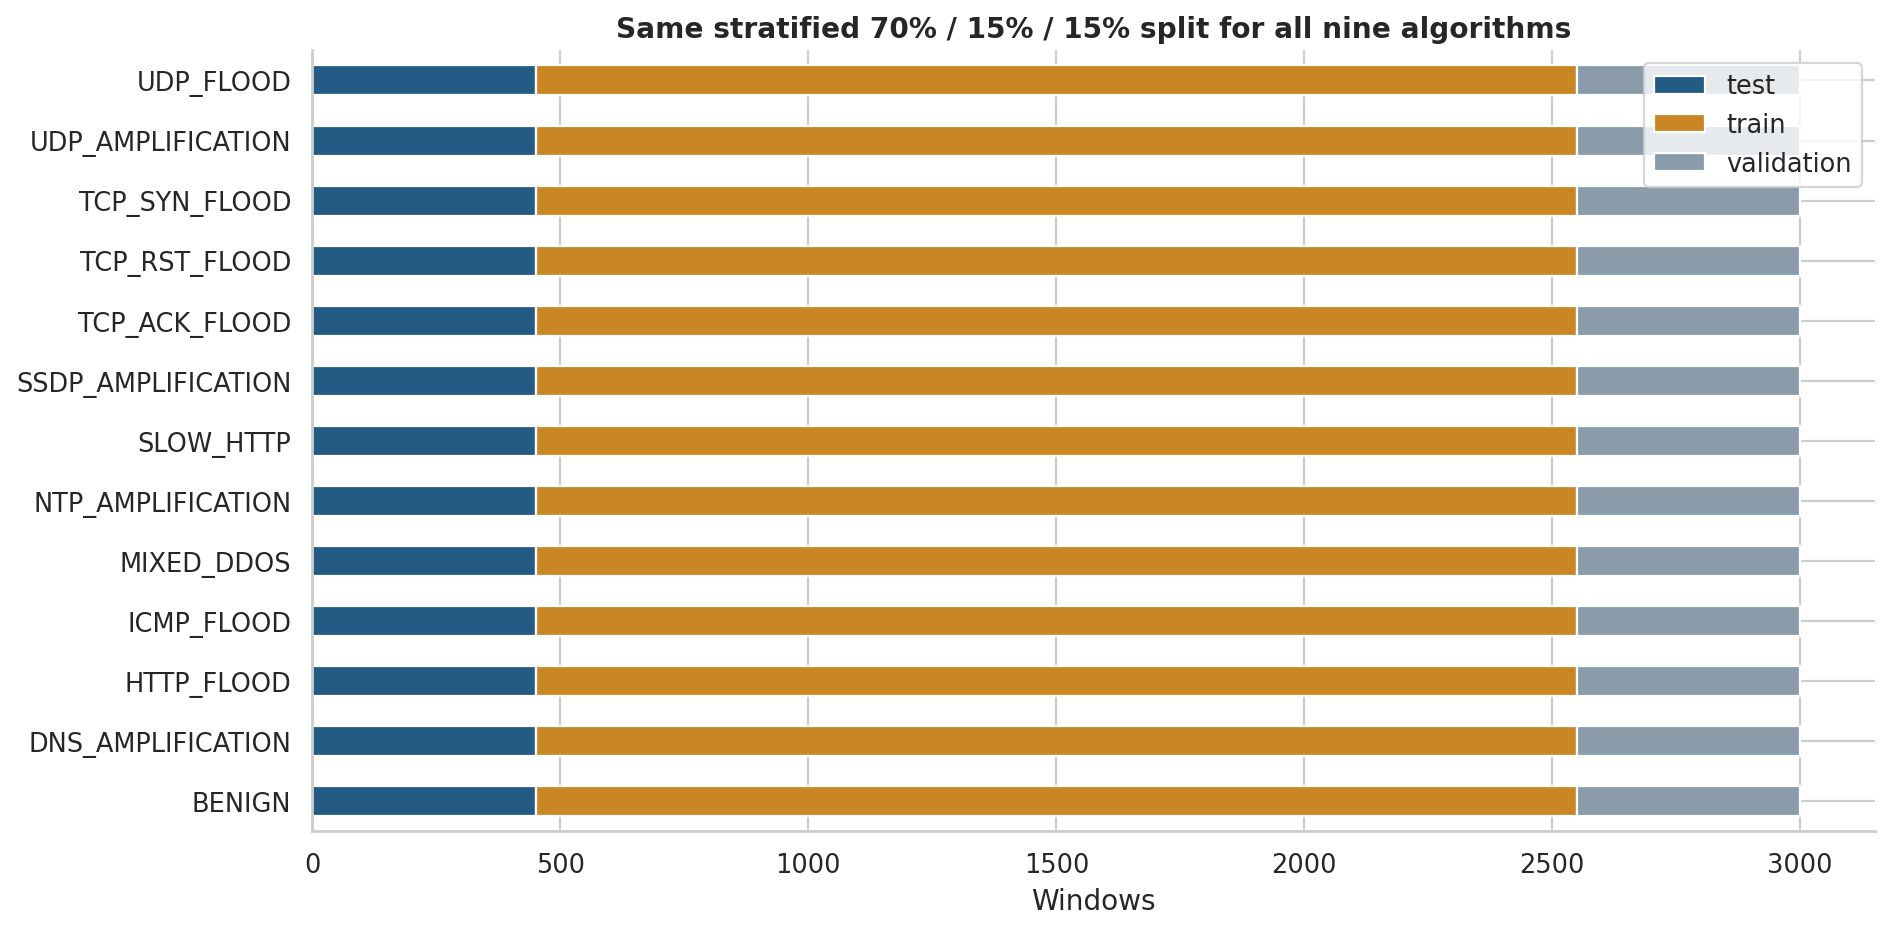

In [17]:
display(audit[['column','dtype','missing','unique','use','reason']])
display(audit[audit.column.isin(features)][['column','unit','meaning']])
print('Dropped training constants:', contract['train_constant_columns'])
print('Retained feature order:', features)
stats = json.loads((RUN_DIR/'preprocessing.json').read_text())
display(pd.DataFrame({'feature':features, 'training_median':stats['median'],
                      'training_mean_after_imputation':stats['mean'], 'training_sample_std':stats['std']}))
display(pd.read_csv(RUN_DIR/'split_counts.csv'))
show_figure('07_split_counts')

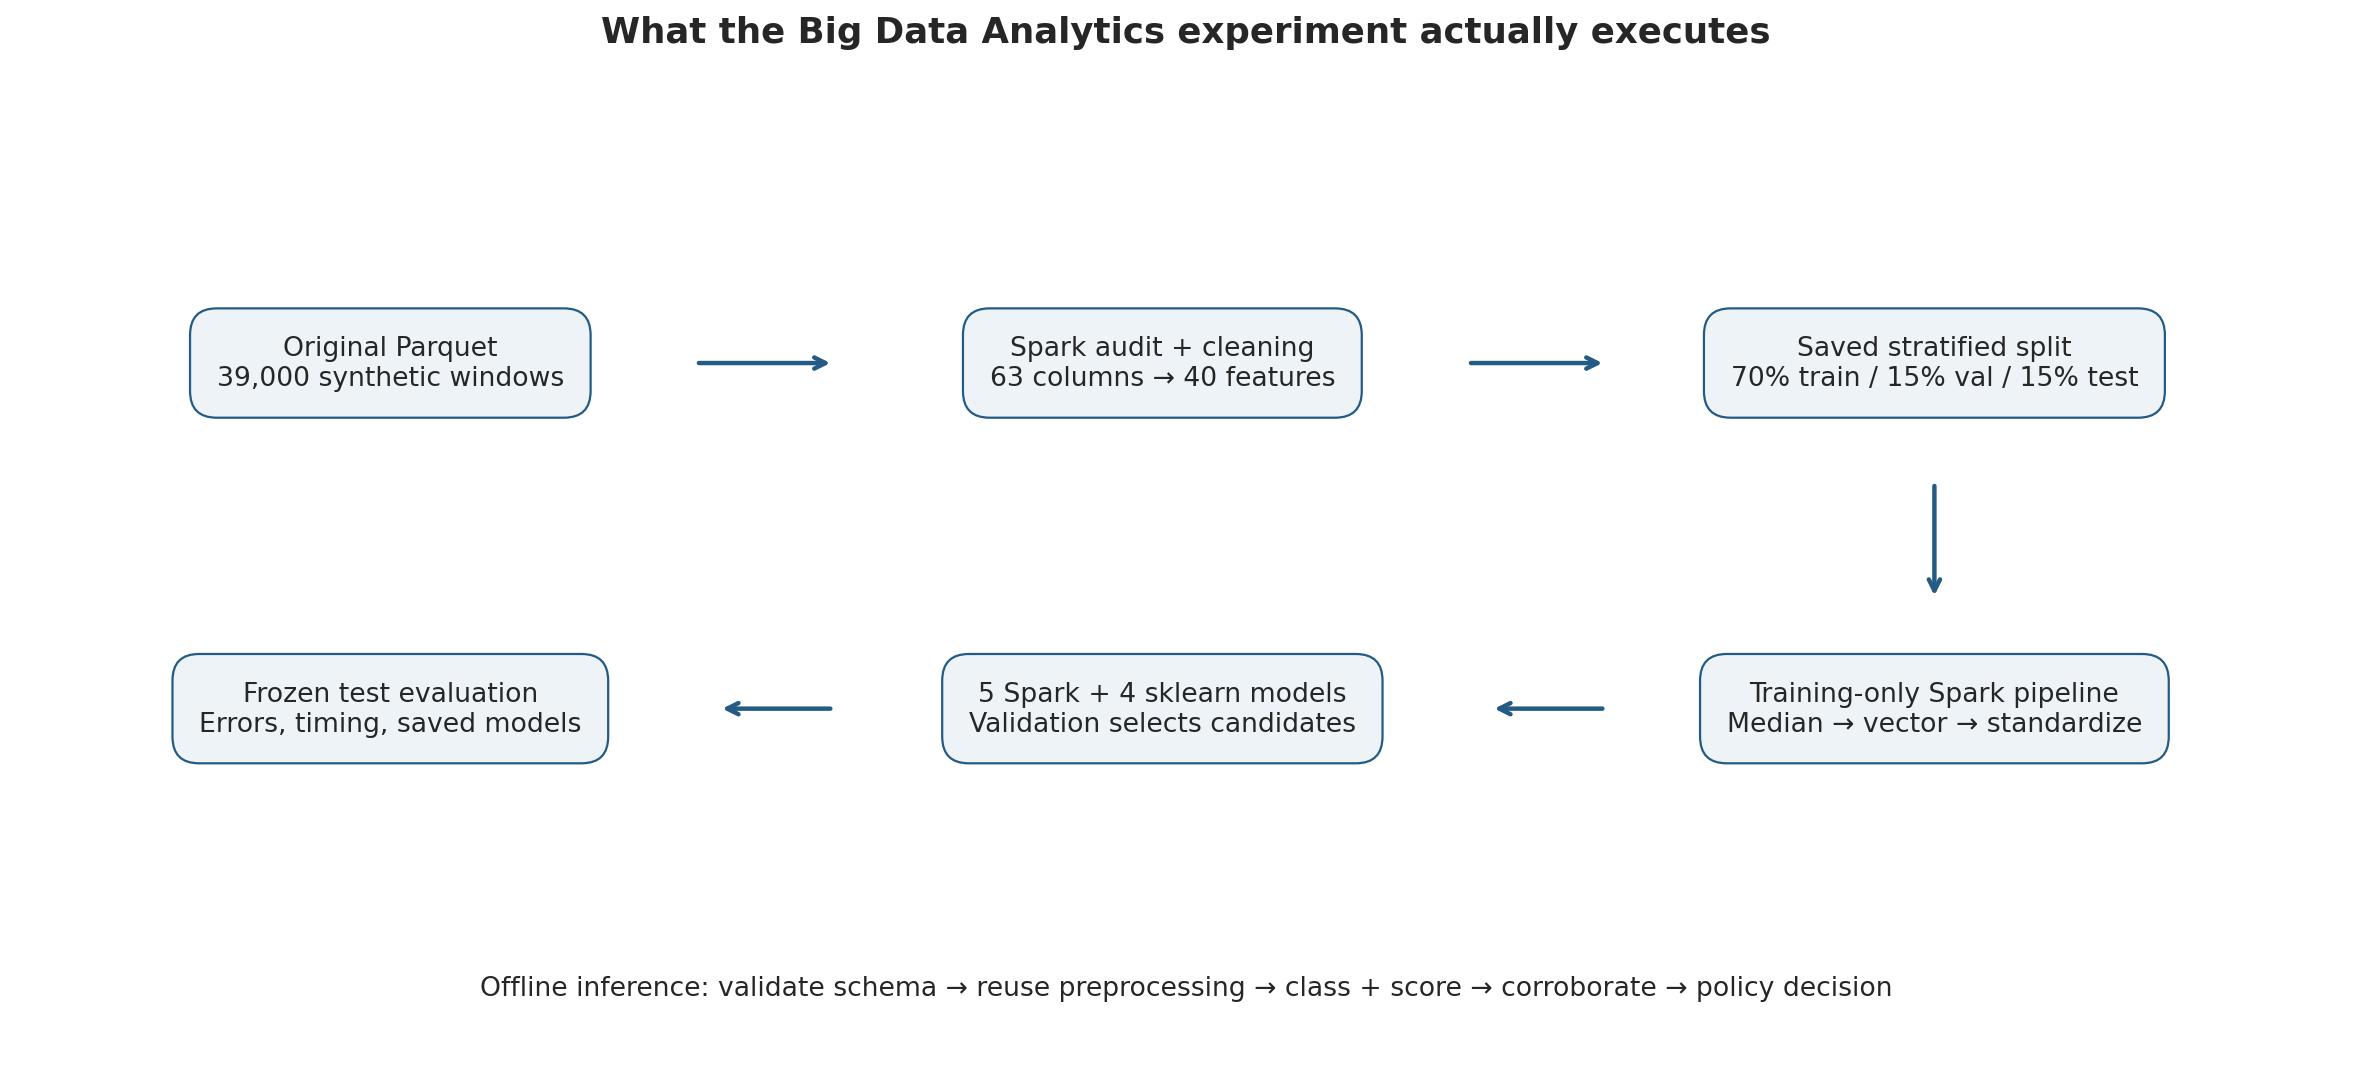

In [18]:
show_figure('00_pipeline')

## 6. Spark versus Pandas: measured scope

Python is a language; Pandas and PySpark are different data-processing systems accessed from Python.
Pandas computes locally; Spark builds plans and schedules tasks through a JVM and workers. A Spark
DataFrame transformation is lazy; timing `groupBy` without a completed action would be misleading.

Here both engines read only `label` and `packet_rate` from the same Parquet and compute class counts
and mean packets/s. Three completed trials alternate engine order. Numerical results must agree.
Spark initialization is reported separately. OS caches are not reset; results include warm-cache effects.
This is a small local benchmark, not a test of cluster scalability. Differences among the nine ML
algorithms must not be interpreted as a controlled Spark-versus-scikit-learn estimator comparison.

,engine,repeat,seconds
0,Pandas,1,0.539978
1,Spark,1,12.633002
2,Spark,2,1.385631
3,Pandas,2,0.075175
4,Pandas,3,0.072083
5,Spark,3,1.433847


,min,median,max
engine,,,
Pandas,0.072083,0.075175,0.539978
Spark,1.385631,1.433847,12.633002


,Spark runtime
startup_seconds,100.103299
version,4.2.0
master,local[4]


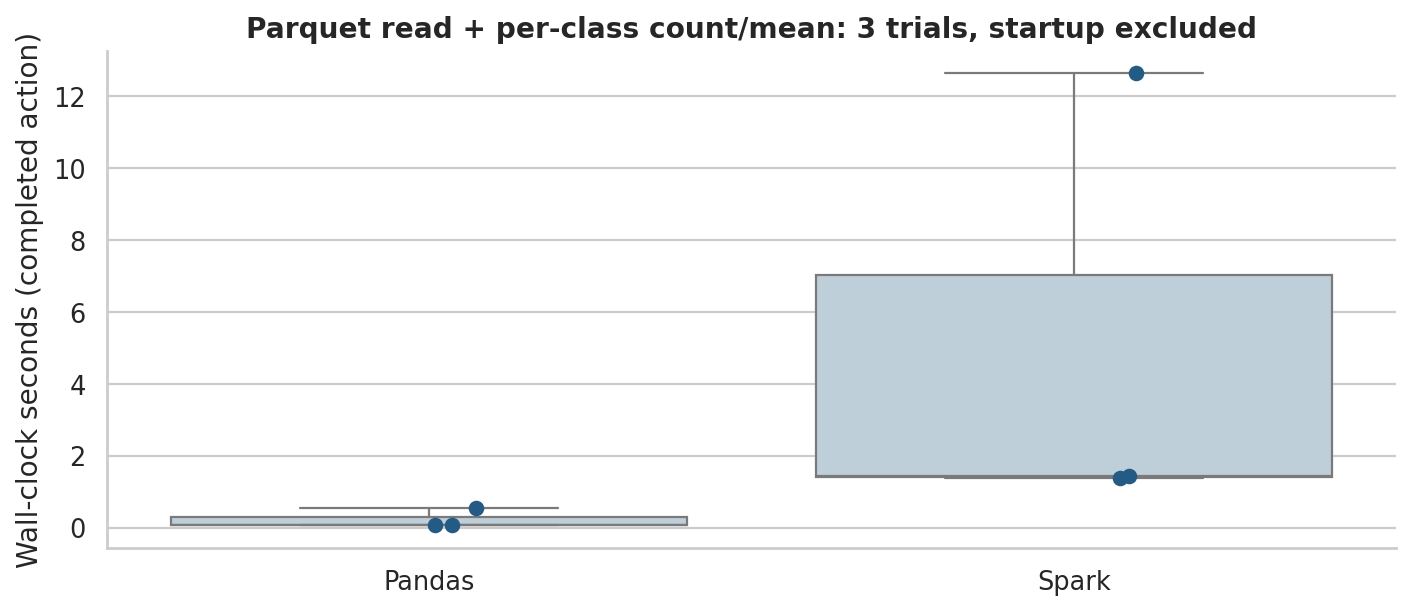

In [19]:
timings = pd.read_csv(RUN_DIR/'engine_benchmark.csv')
display(timings)
display(timings.groupby('engine').seconds.agg(['min','median','max']))
display(pd.Series(json.loads((RUN_DIR/'spark_runtime.json').read_text())).to_frame('Spark runtime'))
show_figure('08_engine_benchmark')

## 7. Model selection and evaluation rules

Each algorithm receives a small predeclared candidate set. Gaussian NB is a fixed baseline.
The best candidate per algorithm is chosen by validation macro F1. The overall model is also selected
by validation macro F1, and this decision is saved before test evaluation. Test ranks are descriptive.
The chosen models remain trained on 70% of rows; there is no hidden train+validation refit.

For each class, $Precision=TP/(TP+FP)$, $Recall=TP/(TP+FN)$ and
$F1=2PR/(P+R)$. Macro averages give each of 13 classes the same weight; weighted F1 uses class support.
Accuracy is total correct divided by total windows. A dummy classifier predicting one class has
accuracy 1/13 on this balanced data; it is a baseline reference and is not counted among the nine.

Fit times cover the selected candidate only. Prediction timing is the median of three completed
5,850-row batches after a warmup. Spark timing includes scheduling and collection; scaling is excluded
for both engines because vectors are prepared. Amortized batch milliseconds per row are **not**
single-request latency or a full controller response time. The fixed random seeds improve reproducibility;
hardware and numeric backend differences can still affect floating-point details and timing.

Validation-selected model: Histogram Gradient Boosting


,model,engine,candidate,validation_macro_f1,fit_seconds
0,Logistic Regression,Spark,0,0.78810,40.16088
1,Logistic Regression,Spark,1,0.78108,18.61241
2,Decision Tree,Spark,0,0.80082,10.83904
3,Decision Tree,Spark,1,0.79924,6.06848
4,Random Forest,Spark,0,0.80057,11.84660
5,Random Forest,Spark,1,0.80952,28.79972
6,Gaussian Naive Bayes,Spark,0,0.75978,4.13681
7,Multilayer Perceptron,Spark,0,0.80535,51.42654
8,Multilayer Perceptron,Spark,1,0.80294,52.37797
9,K Nearest Neighbors,scikit-learn,0,0.74710,0.02201


,model,engine,validation_macro_f1,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,f1_ci_low,f1_ci_high
0,Histogram Gradient Boosting,scikit-learn,0.81665,0.81761,0.81237,0.81761,0.81164,0.81164,0.80473,0.81957
1,Random Forest,Spark,0.80952,0.81162,0.80598,0.81162,0.80296,0.80296,0.79552,0.81058
2,Multilayer Perceptron,Spark,0.80535,0.80855,0.80206,0.80855,0.80178,0.80178,0.79408,0.80907
3,RBF Support Vector Machine,scikit-learn,0.80279,0.80427,0.79901,0.80427,0.79589,0.79589,0.78811,0.80298
4,Decision Tree,Spark,0.80082,0.80462,0.80066,0.80462,0.79930,0.79930,0.79255,0.80700
5,Extra Trees,scikit-learn,0.80057,0.80940,0.80109,0.80940,0.80105,0.80105,0.79388,0.80896
6,Logistic Regression,Spark,0.78810,0.79573,0.78763,0.79573,0.78881,0.78881,0.78134,0.79640
7,K Nearest Neighbors,scikit-learn,0.76038,0.76855,0.76209,0.76855,0.76379,0.76379,0.75655,0.77061
8,Gaussian Naive Bayes,Spark,0.75978,0.76530,0.77987,0.76530,0.76001,0.76001,0.75230,0.76789


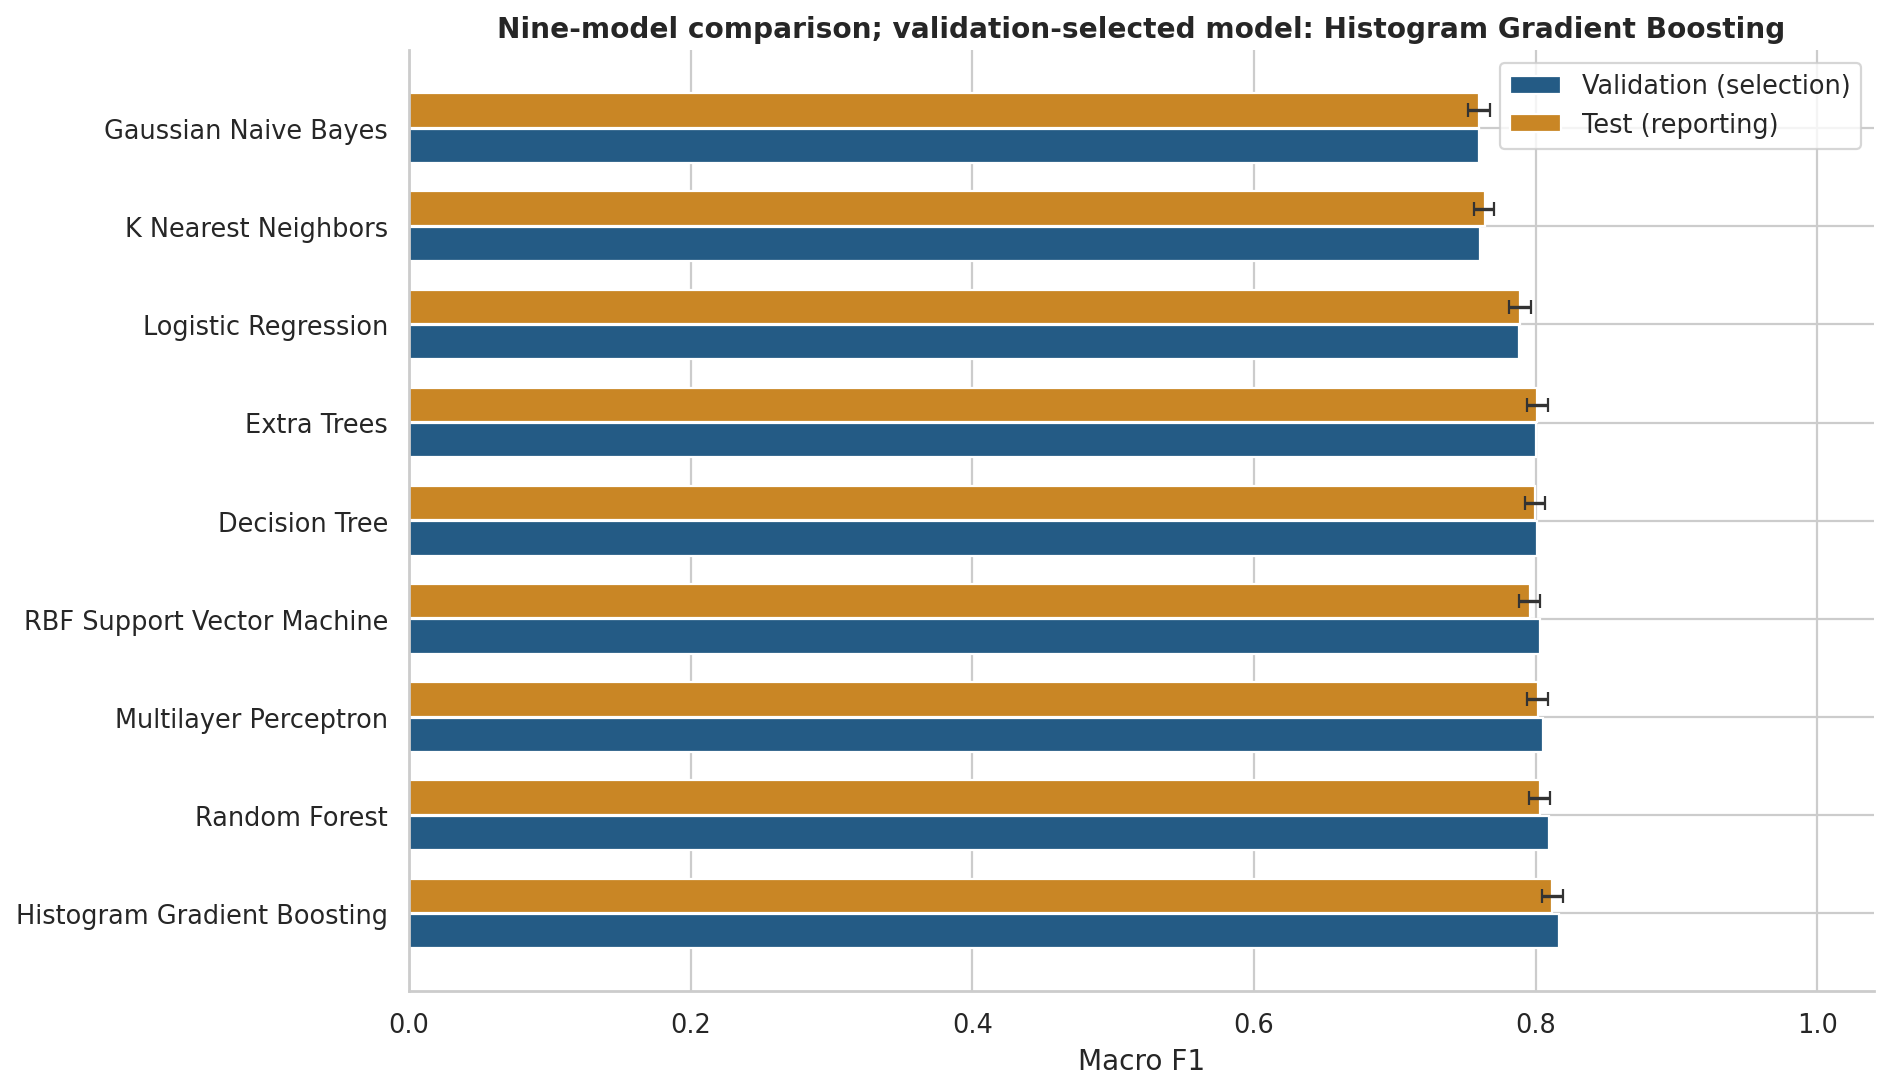

In [20]:
metrics = pd.read_csv(RUN_DIR/'model_metrics.csv')
per_class = pd.read_csv(RUN_DIR/'per_class_metrics.csv')
tuning = pd.read_csv(RUN_DIR/'tuning_results.csv')
selection = json.loads((RUN_DIR/'selection.json').read_text())
winner = selection['winner']
print('Validation-selected model:', winner)
display(tuning[['model','engine','candidate','validation_macro_f1','fit_seconds']].round(5))
display(metrics[['model','engine','validation_macro_f1','accuracy','precision_macro','recall_macro','f1_macro','f1_weighted','f1_ci_low','f1_ci_high']].round(5))
show_figure('10_model_comparison')

**Uncertainty:** the macro F1 intervals use 200 stratified bootstrap resamples of the fixed test
population. They quantify sampling variation within the existing synthetic distribution, not generator
validity, domain shift, independent-session generalization or training-seed variation.

## 8.1 K Nearest Neighbors

**Presenter:** Roydon. **Training backend:** scikit-learn.

KNN stores training examples. For a new window, calculate distances to training windows,
retrieve the $k$ closest, and combine their labels. Euclidean distance is
$d(x,z)=\sqrt{\sum_j(x_j-z_j)^2}$. Distance weighting gives nearby neighbors more influence.

**Execution:** standardized query → nearest stored vectors → weighted vote → class probabilities.
Compare 7 and 15 neighbors. The exact same Spark-fitted numeric vectors are collected to the driver.
This collection is safe at the current size but is not distributed KNN.

**Strength:** simple reference case reasoning; almost no fitting work.
**Failure mode:** prediction and storage grow with training data; irrelevant or redundant dimensions
distort distance. Tiny fit time does not imply inexpensive deployment. Use nearest examples to
illustrate similarity, while checking whether those examples represent the real environment.

,model,engine,candidate,validation_macro_f1,fit_seconds
9,K Nearest Neighbors,scikit-learn,0,0.74710,0.02201
10,K Nearest Neighbors,scikit-learn,1,0.76038,0.01640


Selected settings:


,Value
algorithm,auto
leaf_size,30
metric,minkowski
metric_params,None
n_jobs,4
n_neighbors,15
p,2
weights,distance


,7
accuracy,0.768547
precision_macro,0.762092
recall_macro,0.768547
f1_macro,0.763787
f1_weighted,0.763787
attack_recall_argmax,1.0
benign_fpr_argmax,0.0
attack_roc_auc,1.0
attack_average_precision,1.0
tn,450


,class,precision,recall,f1-score,support
65,BENIGN,1.0000,1.0000,1.0000,450.0
66,DNS_AMPLIFICATION,0.3365,0.3889,0.3608,450.0
67,HTTP_FLOOD,1.0000,0.9756,0.9876,450.0
68,ICMP_FLOOD,0.8747,0.9467,0.9093,450.0
69,MIXED_DDOS,1.0000,1.0000,1.0000,450.0
70,NTP_AMPLIFICATION,0.4015,0.4756,0.4354,450.0
71,SLOW_HTTP,0.9956,0.9978,0.9967,450.0
72,SSDP_AMPLIFICATION,0.3621,0.3267,0.3435,450.0
73,TCP_ACK_FLOOD,0.9761,1.0000,0.9879,450.0
74,TCP_RST_FLOOD,0.9978,0.9956,0.9967,450.0


**Measured inference:** test macro F1 **0.7638**, accuracy **76.85%**. The lowest-recall classes are **UDP_AMPLIFICATION, SSDP_AMPLIFICATION, DNS_AMPLIFICATION**. Inspect their off-diagonal errors below.

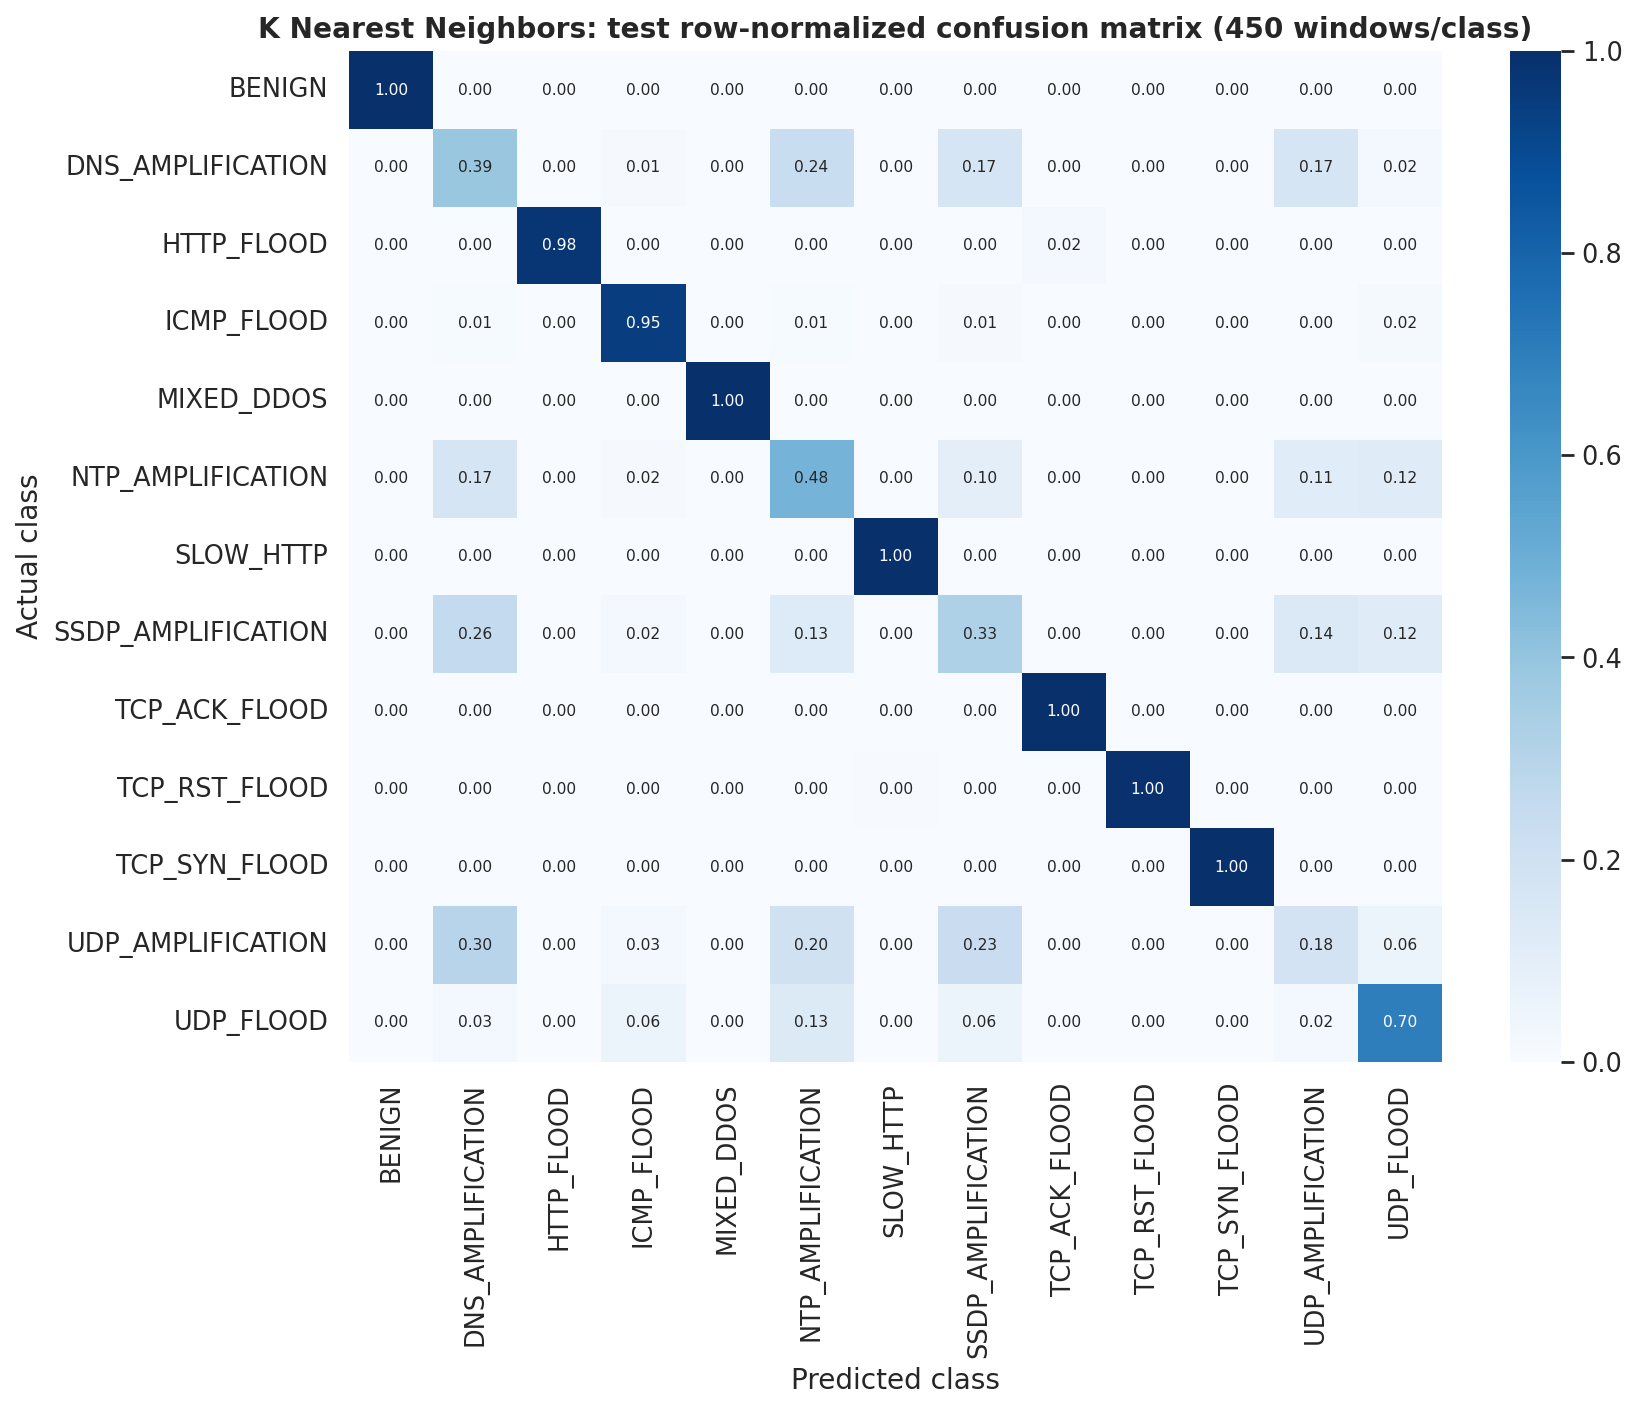

In [21]:
name = 'K Nearest Neighbors'
display(tuning[tuning.model == name].drop(columns='parameters').round(5))
print('Selected settings:')
display(pd.Series(selection['models'][name]['parameters'], dtype=object).to_frame('Value'))
display(metrics[metrics.model == name].T)
display(per_class[per_class.model == name].drop(columns='model').round(4))
model_row = metrics[metrics.model == name].iloc[0]
weak = per_class[per_class.model == name].nsmallest(3, 'recall')
display(Markdown(f"**Measured inference:** test macro F1 **{model_row.f1_macro:.4f}**, accuracy **{model_row.accuracy:.2%}**. "
                 f"The lowest-recall classes are **{', '.join(weak['class'])}**. Inspect their off-diagonal errors below."))
show_figure('cm_' + name.lower().replace(' ', '_'))

In [22]:
name = 'K Nearest Neighbors'
model_predictions = pd.read_parquet(RUN_DIR/'predictions'/(name.lower().replace(' ', '_')+'.parquet'))
print('Actual held-out model outputs, one example per true class:')
print('Score kind:', json.loads((RUN_DIR/'operating_points.json').read_text())[name]['score_kind'])
display(model_predictions.groupby('actual', sort=True).head(1))

Actual held-out model outputs, one example per true class:
Score kind: uncalibrated probability estimate


,window_id,actual,predicted,attack_score,threshold_attack,top_class_probability
0,v3_00_000003,BENIGN,BENIGN,0.0,False,1.000000
450,v3_01_000001,UDP_FLOOD,SSDP_AMPLIFICATION,1.0,True,0.552445
900,v3_02_000002,ICMP_FLOOD,ICMP_FLOOD,1.0,True,0.669470
1350,v3_03_000010,TCP_SYN_FLOOD,TCP_SYN_FLOOD,1.0,True,1.000000
1800,v3_04_000005,TCP_ACK_FLOOD,TCP_ACK_FLOOD,1.0,True,1.000000
2250,v3_05_000009,TCP_RST_FLOOD,TCP_RST_FLOOD,1.0,True,0.740383
2700,v3_06_000027,HTTP_FLOOD,HTTP_FLOOD,1.0,True,1.000000
3150,v3_07_000003,SLOW_HTTP,SLOW_HTTP,1.0,True,1.000000
3600,v3_08_000009,DNS_AMPLIFICATION,SSDP_AMPLIFICATION,1.0,True,0.594017
4050,v3_09_000004,NTP_AMPLIFICATION,SSDP_AMPLIFICATION,1.0,True,0.442389


**How to explain this result in the viva:** identify one strong class, one weak class and
its most frequent confusion. Connect that behavior to the algorithm's assumptions and the observed
feature overlap. A weak model is a valid finding; do not change the split just to improve its score.
Use the target label as a diagnostic category, then separately examine whether the model missed
an attack entirely or merely predicted a different attack type.

## 8.2 Extra Trees

**Presenter:** Roydon. **Training backend:** scikit-learn.

Extremely Randomized Trees add split-threshold randomization to a tree ensemble.
Instead of optimizing every threshold as in a conventional forest, random candidate thresholds
increase diversity; the ensemble averages tree class estimates.

**Execution:** window → 100 randomized trees → averaged class probabilities → predicted label.
Compare depth 16 and unrestricted depth, with minimum 2 rows per leaf and seed 42.
This is a multicore Python model after bounded Spark-to-driver collection, not Spark ML training.

**Strength:** often effective on numeric tabular data with little feature engineering.
**Failure mode:** deep trees can memorize narrow synthetic distributions; model storage and serving
cost rise with tree count. Treat importance as association, and revalidate on independent captures
before using these probabilities for controller decisions.

,model,engine,candidate,validation_macro_f1,fit_seconds
13,Extra Trees,scikit-learn,0,0.79671,1.91024
14,Extra Trees,scikit-learn,1,0.80057,3.81283


Selected settings:


,Value
bootstrap,False
ccp_alpha,0.0
class_weight,None
criterion,gini
max_depth,None
max_features,sqrt
max_leaf_nodes,None
max_samples,None
min_impurity_decrease,0.0
min_samples_leaf,2


,5
accuracy,0.809402
precision_macro,0.801091
recall_macro,0.809402
f1_macro,0.801046
f1_weighted,0.801046
attack_recall_argmax,1.0
benign_fpr_argmax,0.0
attack_roc_auc,1.0
attack_average_precision,1.0
tn,450


,class,precision,recall,f1-score,support
91,BENIGN,1.0000,1.0000,1.0000,450.0
92,DNS_AMPLIFICATION,0.4149,0.5200,0.4615,450.0
93,HTTP_FLOOD,1.0000,0.9978,0.9989,450.0
94,ICMP_FLOOD,0.9474,1.0000,0.9730,450.0
95,MIXED_DDOS,1.0000,1.0000,1.0000,450.0
96,NTP_AMPLIFICATION,0.5028,0.6000,0.5471,450.0
97,SLOW_HTTP,1.0000,1.0000,1.0000,450.0
98,SSDP_AMPLIFICATION,0.4195,0.3244,0.3659,450.0
99,TCP_ACK_FLOOD,0.9978,1.0000,0.9989,450.0
100,TCP_RST_FLOOD,1.0000,1.0000,1.0000,450.0


**Measured inference:** test macro F1 **0.8010**, accuracy **80.94%**. The lowest-recall classes are **UDP_AMPLIFICATION, SSDP_AMPLIFICATION, DNS_AMPLIFICATION**. Inspect their off-diagonal errors below.

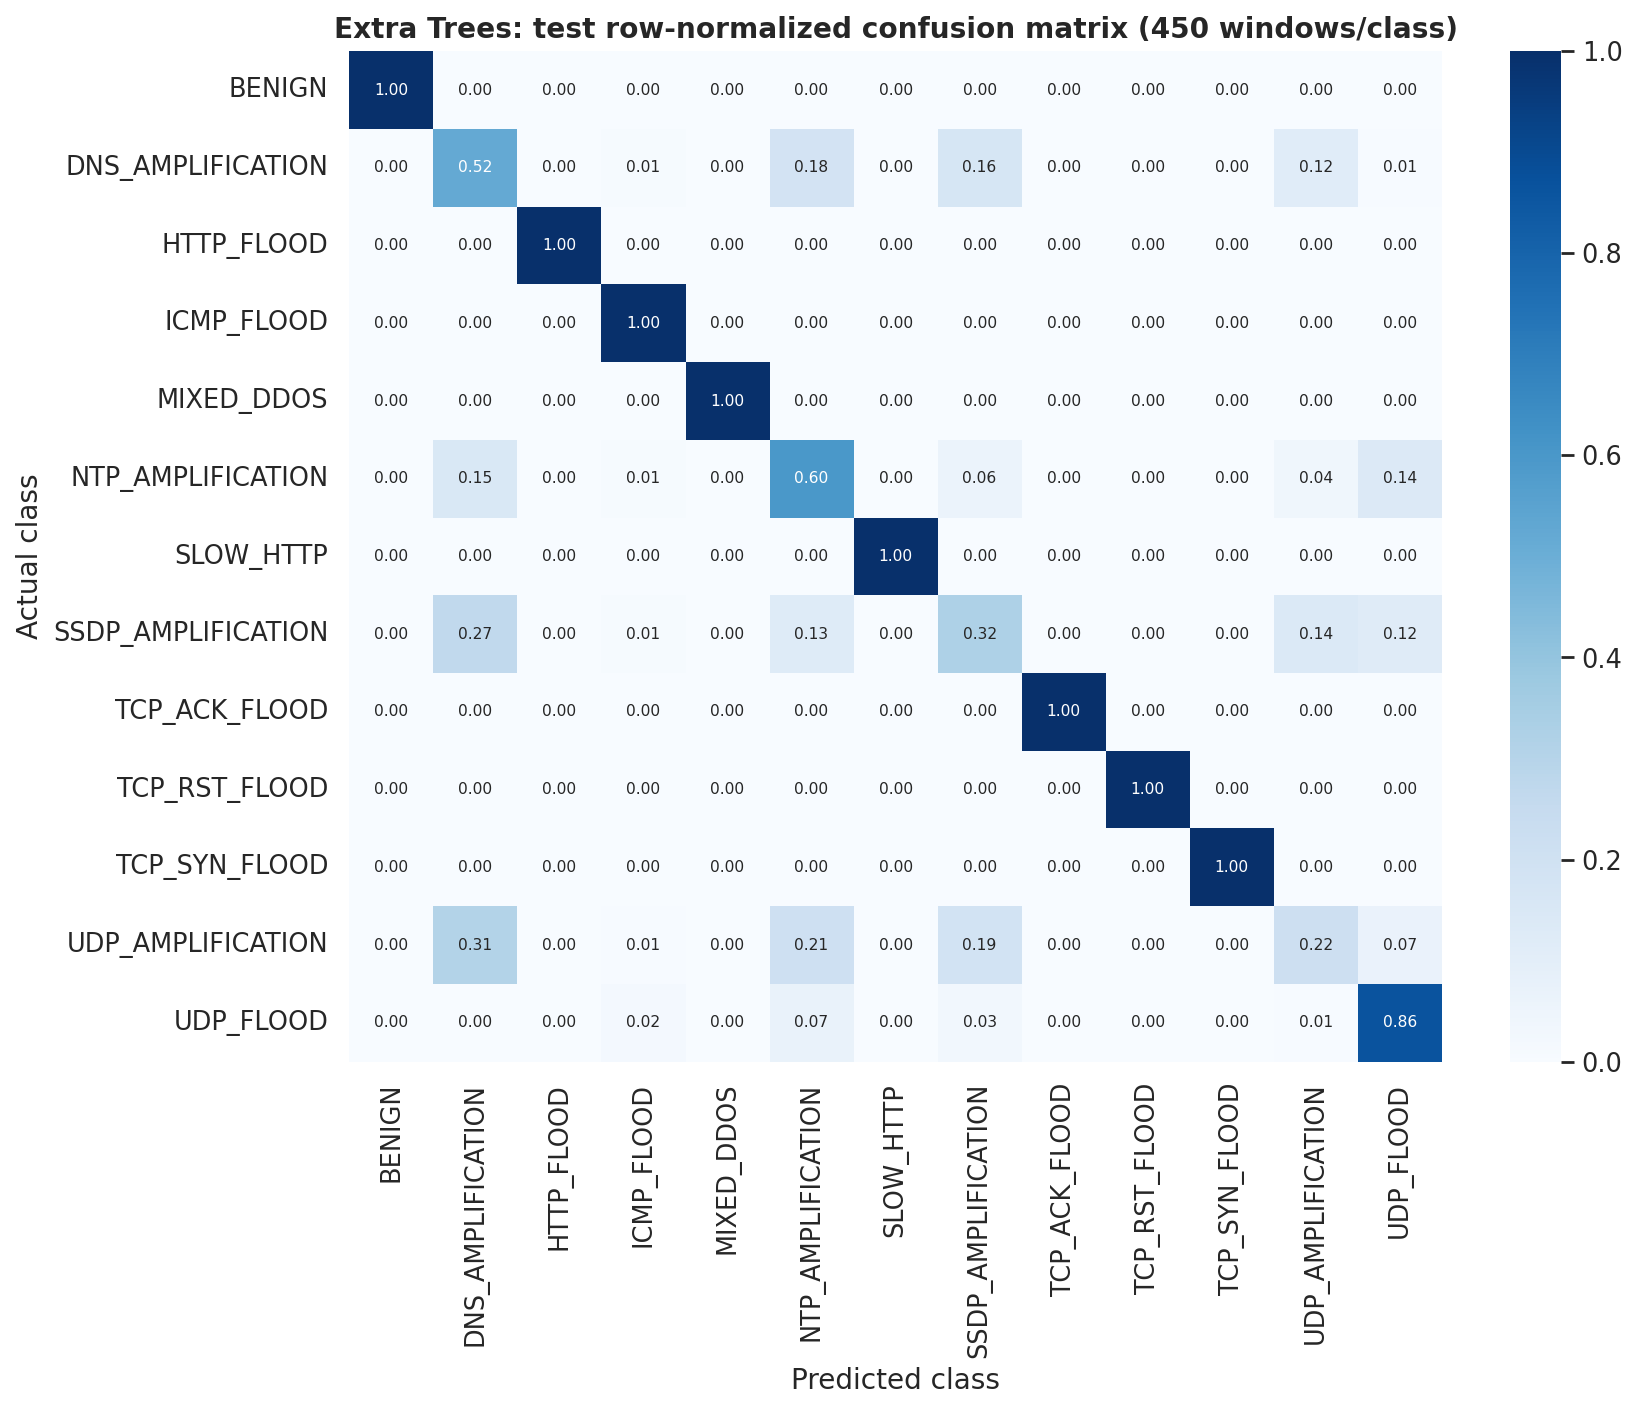

In [23]:
name = 'Extra Trees'
display(tuning[tuning.model == name].drop(columns='parameters').round(5))
print('Selected settings:')
display(pd.Series(selection['models'][name]['parameters'], dtype=object).to_frame('Value'))
display(metrics[metrics.model == name].T)
display(per_class[per_class.model == name].drop(columns='model').round(4))
model_row = metrics[metrics.model == name].iloc[0]
weak = per_class[per_class.model == name].nsmallest(3, 'recall')
display(Markdown(f"**Measured inference:** test macro F1 **{model_row.f1_macro:.4f}**, accuracy **{model_row.accuracy:.2%}**. "
                 f"The lowest-recall classes are **{', '.join(weak['class'])}**. Inspect their off-diagonal errors below."))
show_figure('cm_' + name.lower().replace(' ', '_'))

In [24]:
name = 'Extra Trees'
model_predictions = pd.read_parquet(RUN_DIR/'predictions'/(name.lower().replace(' ', '_')+'.parquet'))
print('Actual held-out model outputs, one example per true class:')
print('Score kind:', json.loads((RUN_DIR/'operating_points.json').read_text())[name]['score_kind'])
display(model_predictions.groupby('actual', sort=True).head(1))

Actual held-out model outputs, one example per true class:
Score kind: uncalibrated probability estimate


,window_id,actual,predicted,attack_score,threshold_attack,top_class_probability
0,v3_00_000003,BENIGN,BENIGN,0.00,False,1.000000
450,v3_01_000001,UDP_FLOOD,SSDP_AMPLIFICATION,1.00,True,0.304333
900,v3_02_000002,ICMP_FLOOD,ICMP_FLOOD,1.00,True,0.615667
1350,v3_03_000010,TCP_SYN_FLOOD,TCP_SYN_FLOOD,1.00,True,0.990000
1800,v3_04_000005,TCP_ACK_FLOOD,TCP_ACK_FLOOD,1.00,True,1.000000
2250,v3_05_000009,TCP_RST_FLOOD,TCP_RST_FLOOD,1.00,True,0.980000
2700,v3_06_000027,HTTP_FLOOD,HTTP_FLOOD,0.99,True,0.985000
3150,v3_07_000003,SLOW_HTTP,SLOW_HTTP,1.00,True,0.994970
3600,v3_08_000009,DNS_AMPLIFICATION,SSDP_AMPLIFICATION,1.00,True,0.404128
4050,v3_09_000004,NTP_AMPLIFICATION,NTP_AMPLIFICATION,1.00,True,0.315528


**How to explain this result in the viva:** identify one strong class, one weak class and
its most frequent confusion. Connect that behavior to the algorithm's assumptions and the observed
feature overlap. A weak model is a valid finding; do not change the split just to improve its score.
Use the target label as a diagnostic category, then separately examine whether the model missed
an attack entirely or merely predicted a different attack type.

## 8.3 Histogram Gradient Boosting

**Presenter:** Roydon. **Training backend:** scikit-learn.

Boosting adds trees sequentially to reduce the current loss. For multiclass classification,
the additive class scores are converted to probabilities with softmax. A learning rate shrinks
each update; histogram bins reduce the cost of considering continuous split thresholds.

**Execution:** initial class scores → add corrections from successive trees → probabilities → argmax.
Use maximum 100 iterations, learning rate 0.1, L2 penalty 1, and compare 15 versus 31 leaf nodes.
Early stopping uses an internal subset drawn only from the external training split; the external
validation set still chooses between candidates. This is different from Spark's binary-only GBTClassifier.

**Strength:** powerful nonlinear numeric-table baseline. **Failure mode:** sequential training,
more tuning choices, and overfitting to generator-specific relationships. Use its class distribution
to produce a diagnostic alert with alternatives and explain errors on similar amplification classes.

,model,engine,candidate,validation_macro_f1,fit_seconds
15,Histogram Gradient Boosting,scikit-learn,0,0.81665,14.74547
16,Histogram Gradient Boosting,scikit-learn,1,0.81077,8.73129


Selected settings:


,Value
categorical_features,from_dtype
class_weight,None
early_stopping,True
interaction_cst,None
l2_regularization,1.0
learning_rate,0.1
loss,log_loss
max_bins,255
max_depth,None
max_features,1.0


,0
accuracy,0.817607
precision_macro,0.812369
recall_macro,0.817607
f1_macro,0.811639
f1_weighted,0.811639
attack_recall_argmax,1.0
benign_fpr_argmax,0.0
attack_roc_auc,1.0
attack_average_precision,1.0
tn,450


,class,precision,recall,f1-score,support
104,BENIGN,1.0000,1.0000,1.0000,450.0
105,DNS_AMPLIFICATION,0.4231,0.5378,0.4736,450.0
106,HTTP_FLOOD,1.0000,1.0000,1.0000,450.0
107,ICMP_FLOOD,0.9825,1.0000,0.9912,450.0
108,MIXED_DDOS,1.0000,1.0000,1.0000,450.0
109,NTP_AMPLIFICATION,0.5217,0.6156,0.5647,450.0
110,SLOW_HTTP,1.0000,1.0000,1.0000,450.0
111,SSDP_AMPLIFICATION,0.4349,0.3489,0.3872,450.0
112,TCP_ACK_FLOOD,1.0000,1.0000,1.0000,450.0
113,TCP_RST_FLOOD,1.0000,1.0000,1.0000,450.0


**Measured inference:** test macro F1 **0.8116**, accuracy **81.76%**. The lowest-recall classes are **UDP_AMPLIFICATION, SSDP_AMPLIFICATION, DNS_AMPLIFICATION**. Inspect their off-diagonal errors below.

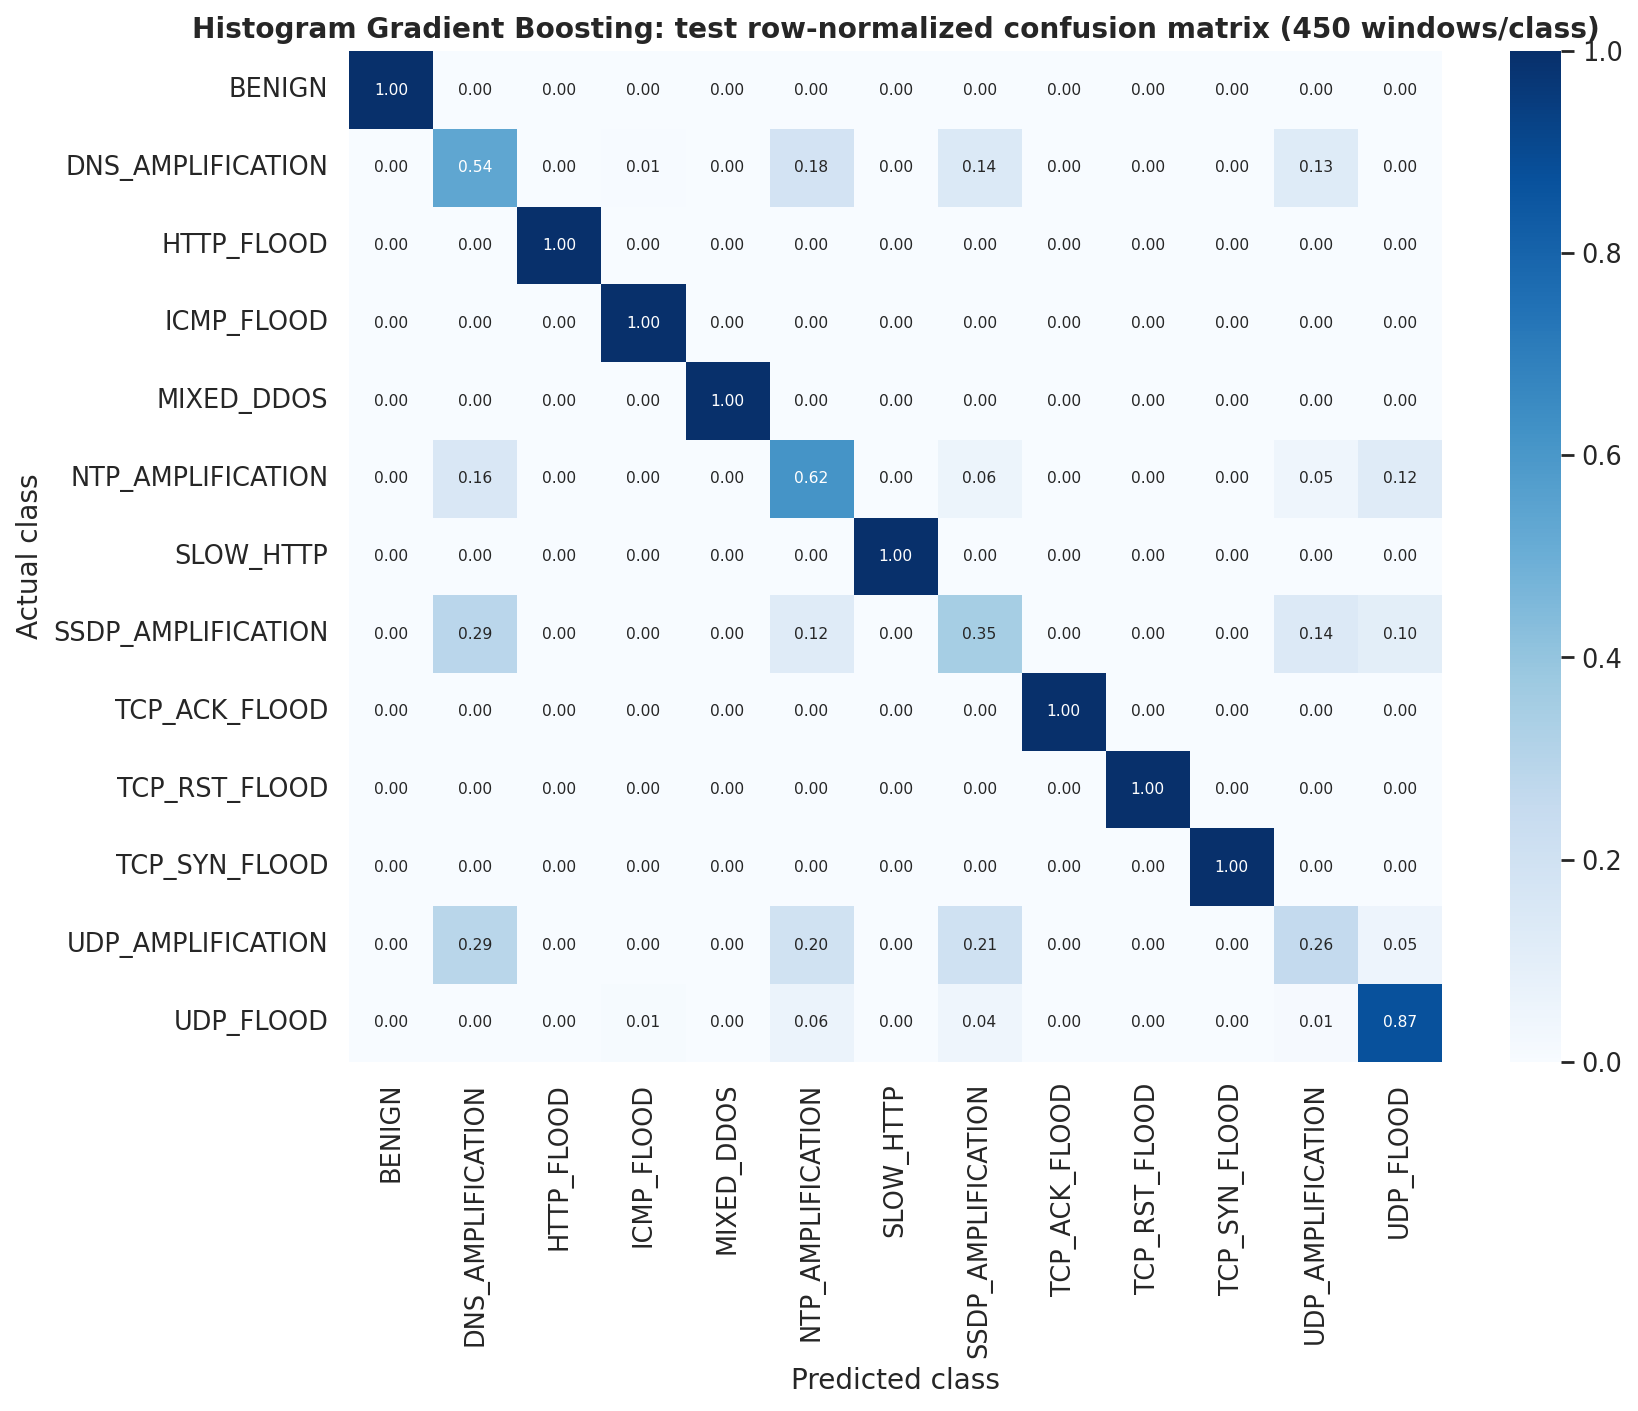

In [25]:
name = 'Histogram Gradient Boosting'
display(tuning[tuning.model == name].drop(columns='parameters').round(5))
print('Selected settings:')
display(pd.Series(selection['models'][name]['parameters'], dtype=object).to_frame('Value'))
display(metrics[metrics.model == name].T)
display(per_class[per_class.model == name].drop(columns='model').round(4))
model_row = metrics[metrics.model == name].iloc[0]
weak = per_class[per_class.model == name].nsmallest(3, 'recall')
display(Markdown(f"**Measured inference:** test macro F1 **{model_row.f1_macro:.4f}**, accuracy **{model_row.accuracy:.2%}**. "
                 f"The lowest-recall classes are **{', '.join(weak['class'])}**. Inspect their off-diagonal errors below."))
show_figure('cm_' + name.lower().replace(' ', '_'))

In [26]:
name = 'Histogram Gradient Boosting'
model_predictions = pd.read_parquet(RUN_DIR/'predictions'/(name.lower().replace(' ', '_')+'.parquet'))
print('Actual held-out model outputs, one example per true class:')
print('Score kind:', json.loads((RUN_DIR/'operating_points.json').read_text())[name]['score_kind'])
display(model_predictions.groupby('actual', sort=True).head(1))

Actual held-out model outputs, one example per true class:
Score kind: uncalibrated probability estimate


,window_id,actual,predicted,attack_score,threshold_attack,top_class_probability
0,v3_00_000003,BENIGN,BENIGN,0.000405,False,0.999595
450,v3_01_000001,UDP_FLOOD,SSDP_AMPLIFICATION,0.999732,True,0.347966
900,v3_02_000002,ICMP_FLOOD,ICMP_FLOOD,0.999982,True,0.993196
1350,v3_03_000010,TCP_SYN_FLOOD,TCP_SYN_FLOOD,0.999997,True,0.999783
1800,v3_04_000005,TCP_ACK_FLOOD,TCP_ACK_FLOOD,0.999997,True,0.999760
2250,v3_05_000009,TCP_RST_FLOOD,TCP_RST_FLOOD,0.999997,True,0.999772
2700,v3_06_000027,HTTP_FLOOD,HTTP_FLOOD,0.999998,True,0.999668
3150,v3_07_000003,SLOW_HTTP,SLOW_HTTP,0.999997,True,0.999792
3600,v3_08_000009,DNS_AMPLIFICATION,SSDP_AMPLIFICATION,0.999828,True,0.453674
4050,v3_09_000004,NTP_AMPLIFICATION,NTP_AMPLIFICATION,0.999799,True,0.350110


**How to explain this result in the viva:** identify one strong class, one weak class and
its most frequent confusion. Connect that behavior to the algorithm's assumptions and the observed
feature overlap. A weak model is a valid finding; do not change the split just to improve its score.
Use the target label as a diagnostic category, then separately examine whether the model missed
an attack entirely or merely predicted a different attack type.

## 9. Cross-model comparison and error analysis

The recall heatmap exposes class-level failures that aggregate accuracy can hide. Rows are true classes.
In confusion matrices, diagonal mass is correct classification; off-diagonal mass is confusion.
A wrong amplification subtype can still be a correct binary attack alert. BENIGN→attack causes false
alarms; attack→BENIGN is a missed attack. Those errors deserve separate treatment.

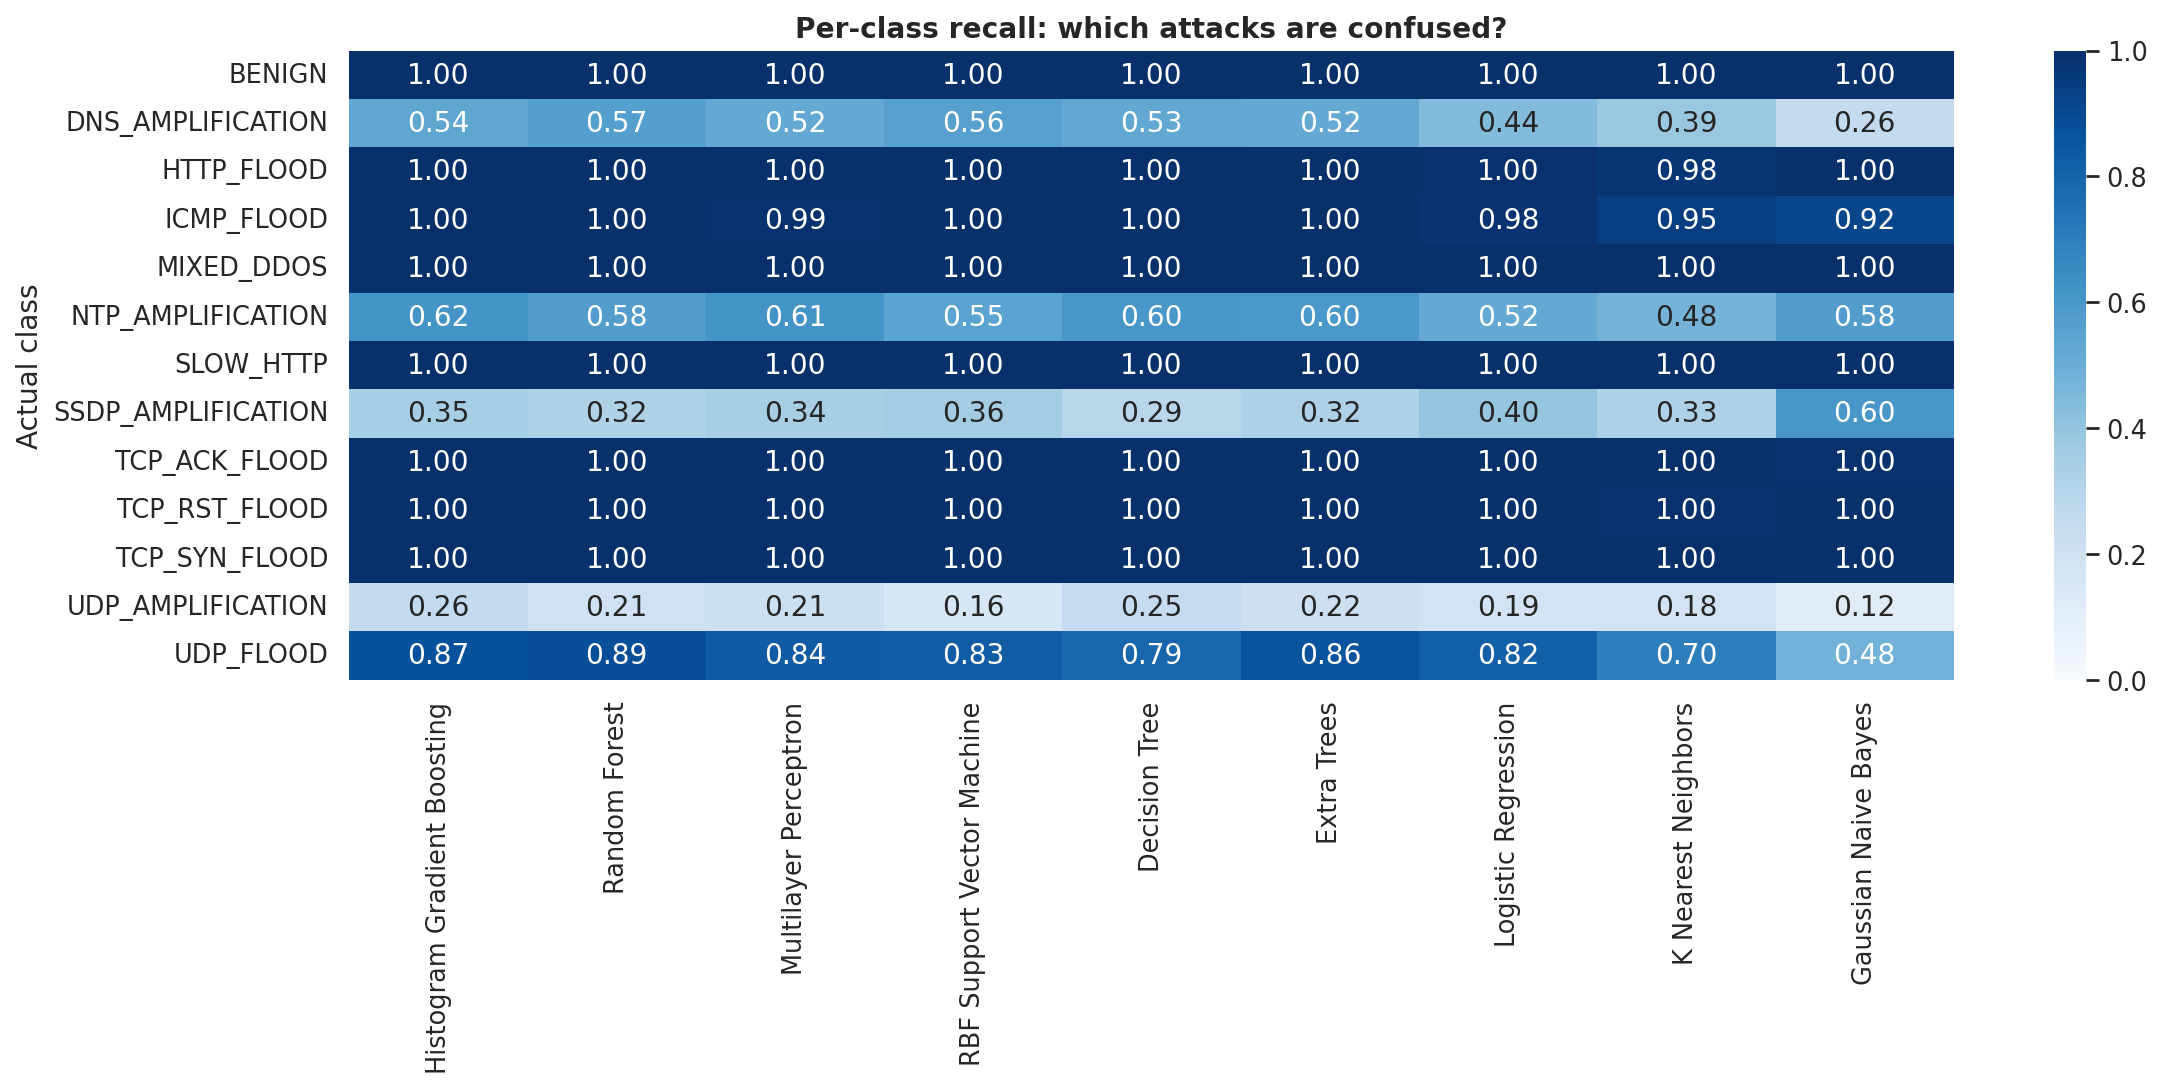

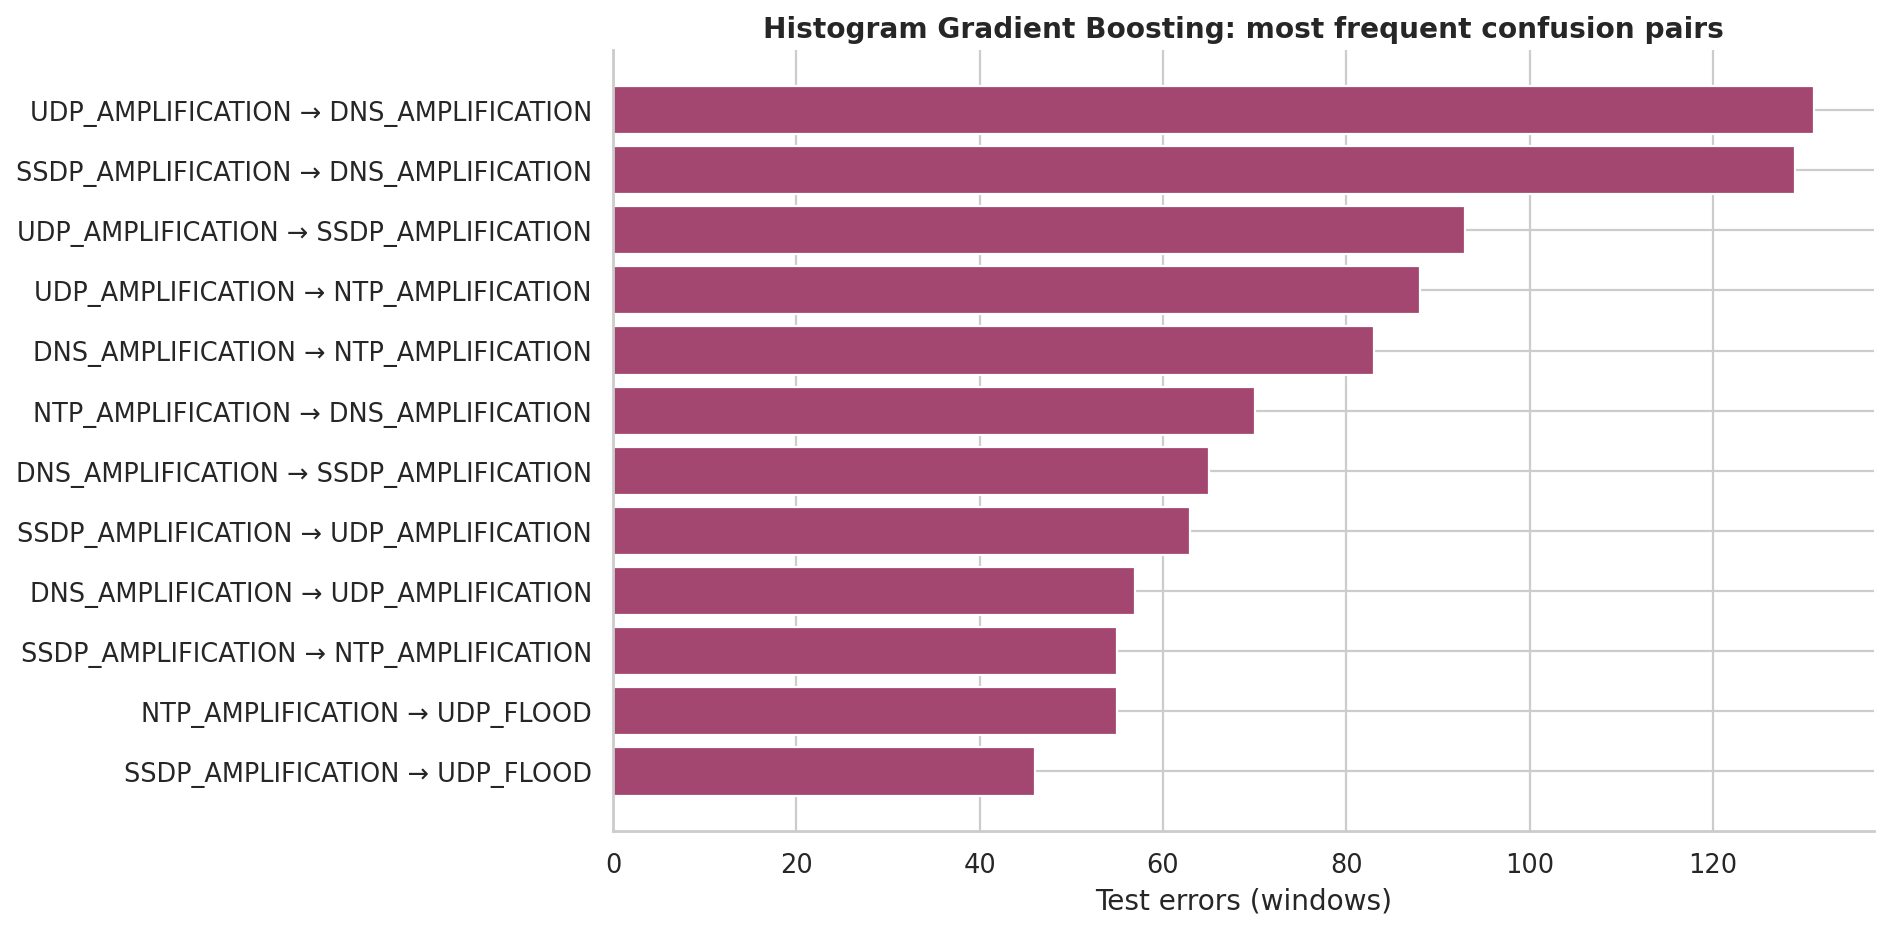

In [27]:
show_figure('12_recall_heatmap')
show_figure('18_error_pairs')

### 9.1 Compute and serving tradeoffs

Choose on validation quality subject to resource requirements. This benchmark does not impose a
measured controller latency budget. A per-row batch average below one millisecond does not prove
line-rate packet classification. The system classifies aggregate windows and must wait for collection,
feature construction, transport, scheduling, inference and policy enforcement.

,model,fit_seconds,prediction_batch_seconds,amortized_prediction_ms
0,Histogram Gradient Boosting,14.74547,0.79341,0.13563
1,Random Forest,28.79972,2.45153,0.41907
2,Multilayer Perceptron,51.42654,0.61375,0.10491
3,RBF Support Vector Machine,21.67701,26.33816,4.50225
4,Decision Tree,10.83904,0.57971,0.09910
5,Extra Trees,3.81283,0.41093,0.07024
6,Logistic Regression,40.16088,0.41596,0.07110
7,K Nearest Neighbors,0.01640,2.99537,0.51203
8,Gaussian Naive Bayes,4.13681,0.60645,0.10367


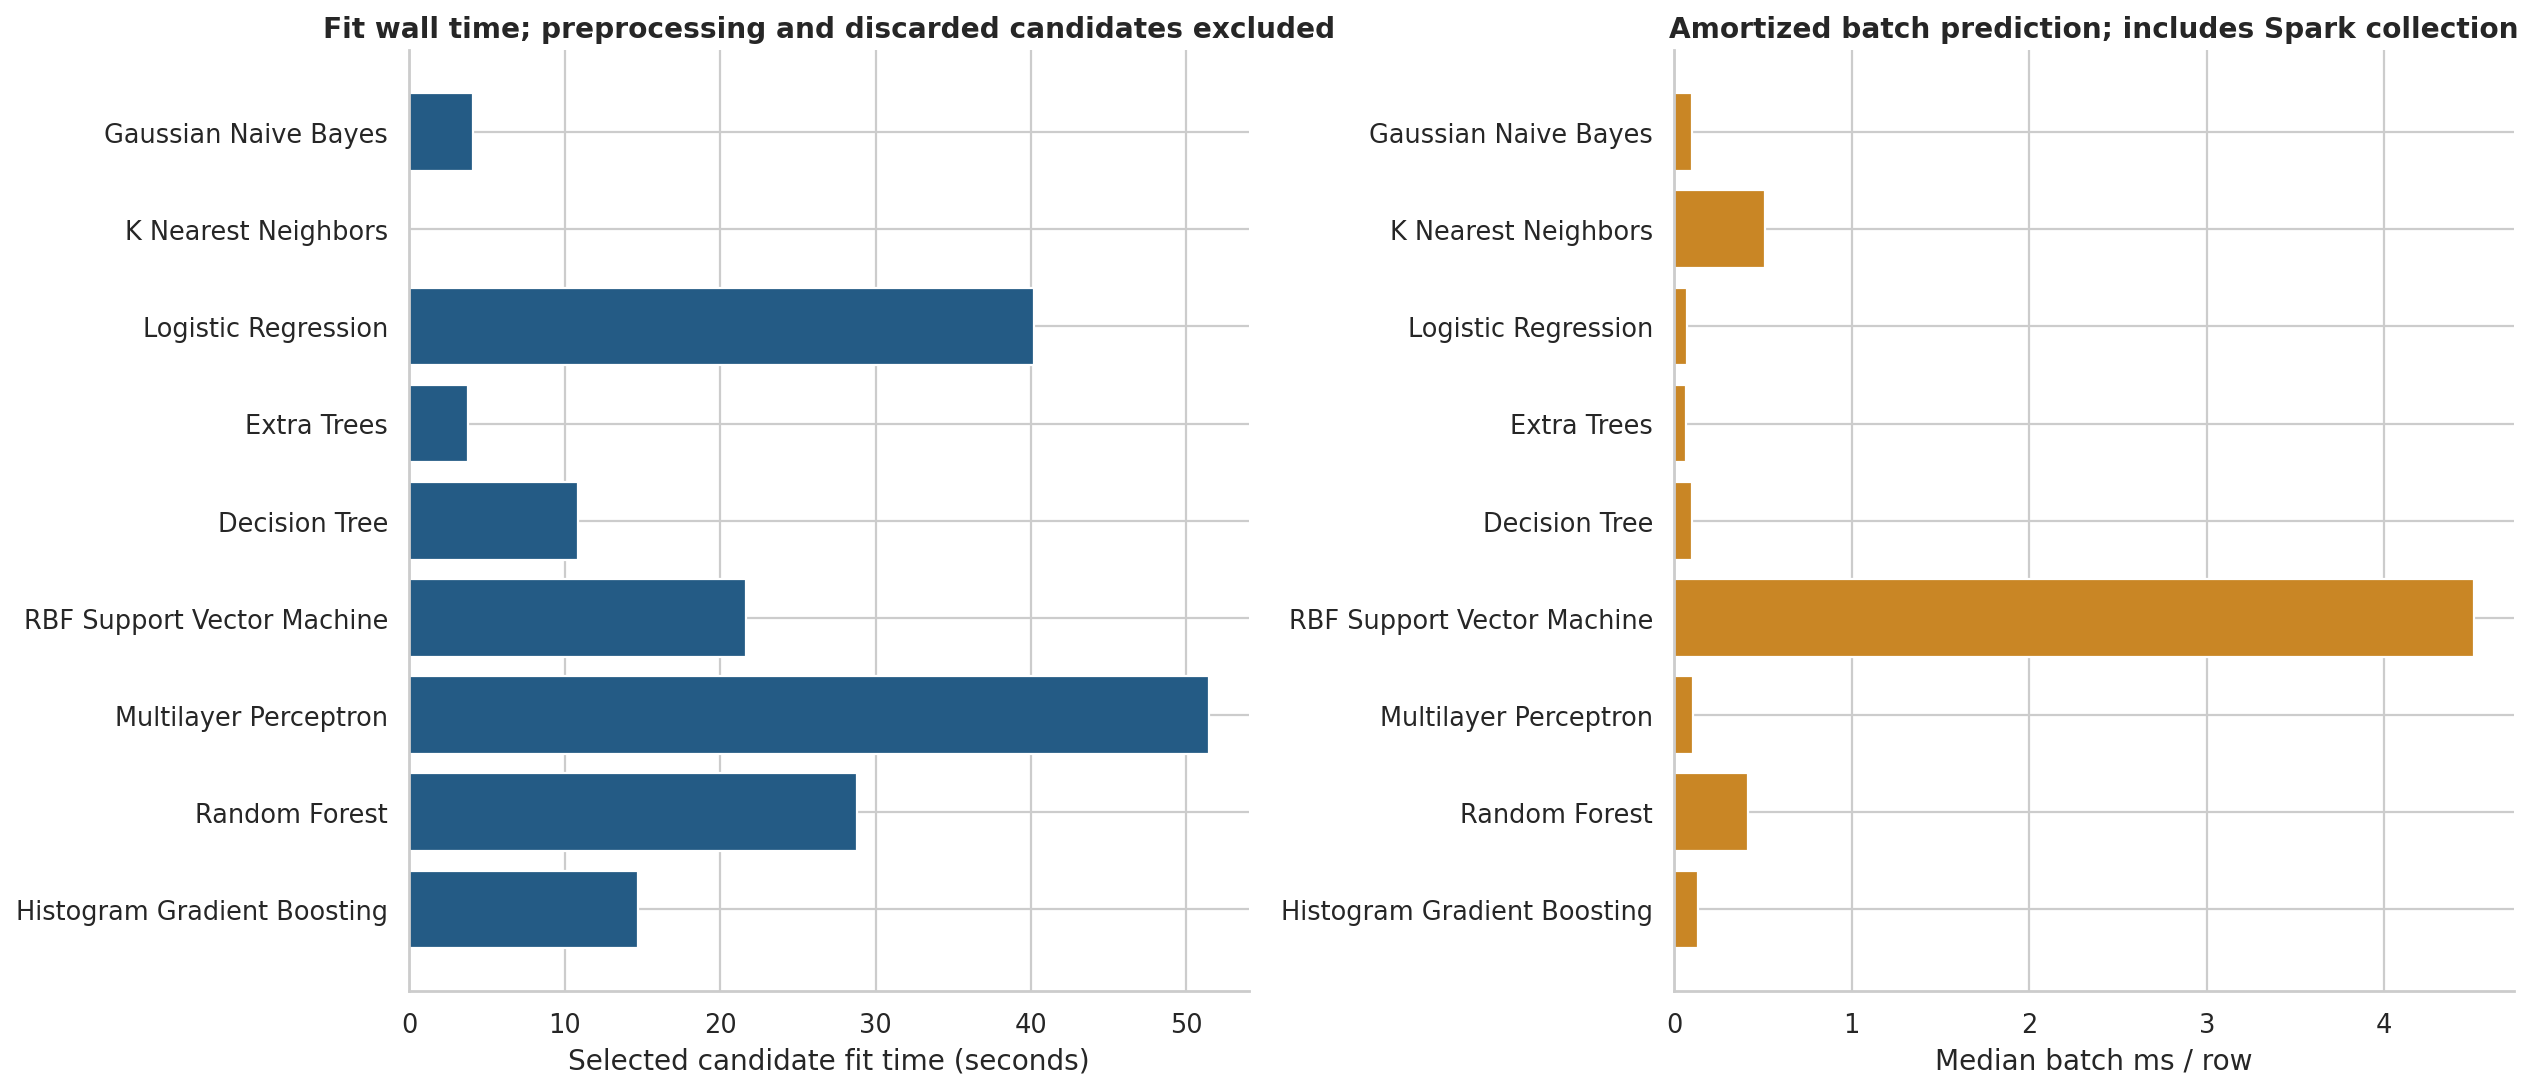

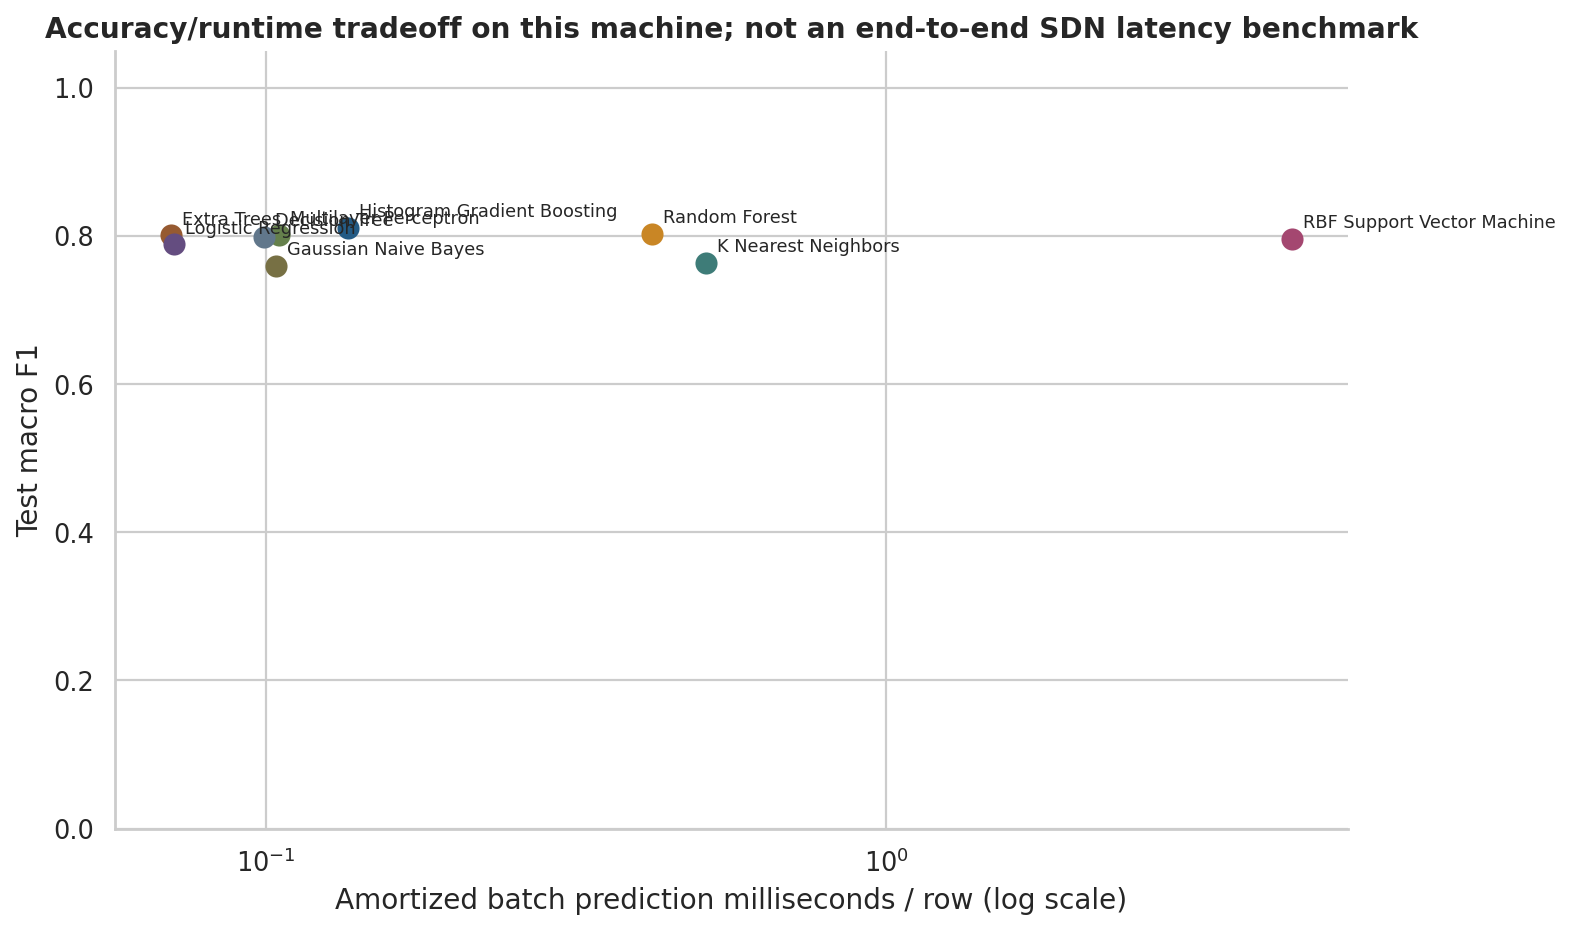

In [28]:
display(metrics[['model','fit_seconds','prediction_batch_seconds','amortized_prediction_ms']].round(5))
show_figure('11_runtime')
show_figure('14_tradeoff')

### 9.2 Feature relevance and confidence

Impurity importance describes the fitted tree models. It is not a causal ranking and can be split across
redundant counters. A top-class confidence plot compares predicted confidence with observed correctness
in bins. It is descriptive only: no calibrator or decision rule is tuned on test outcomes.

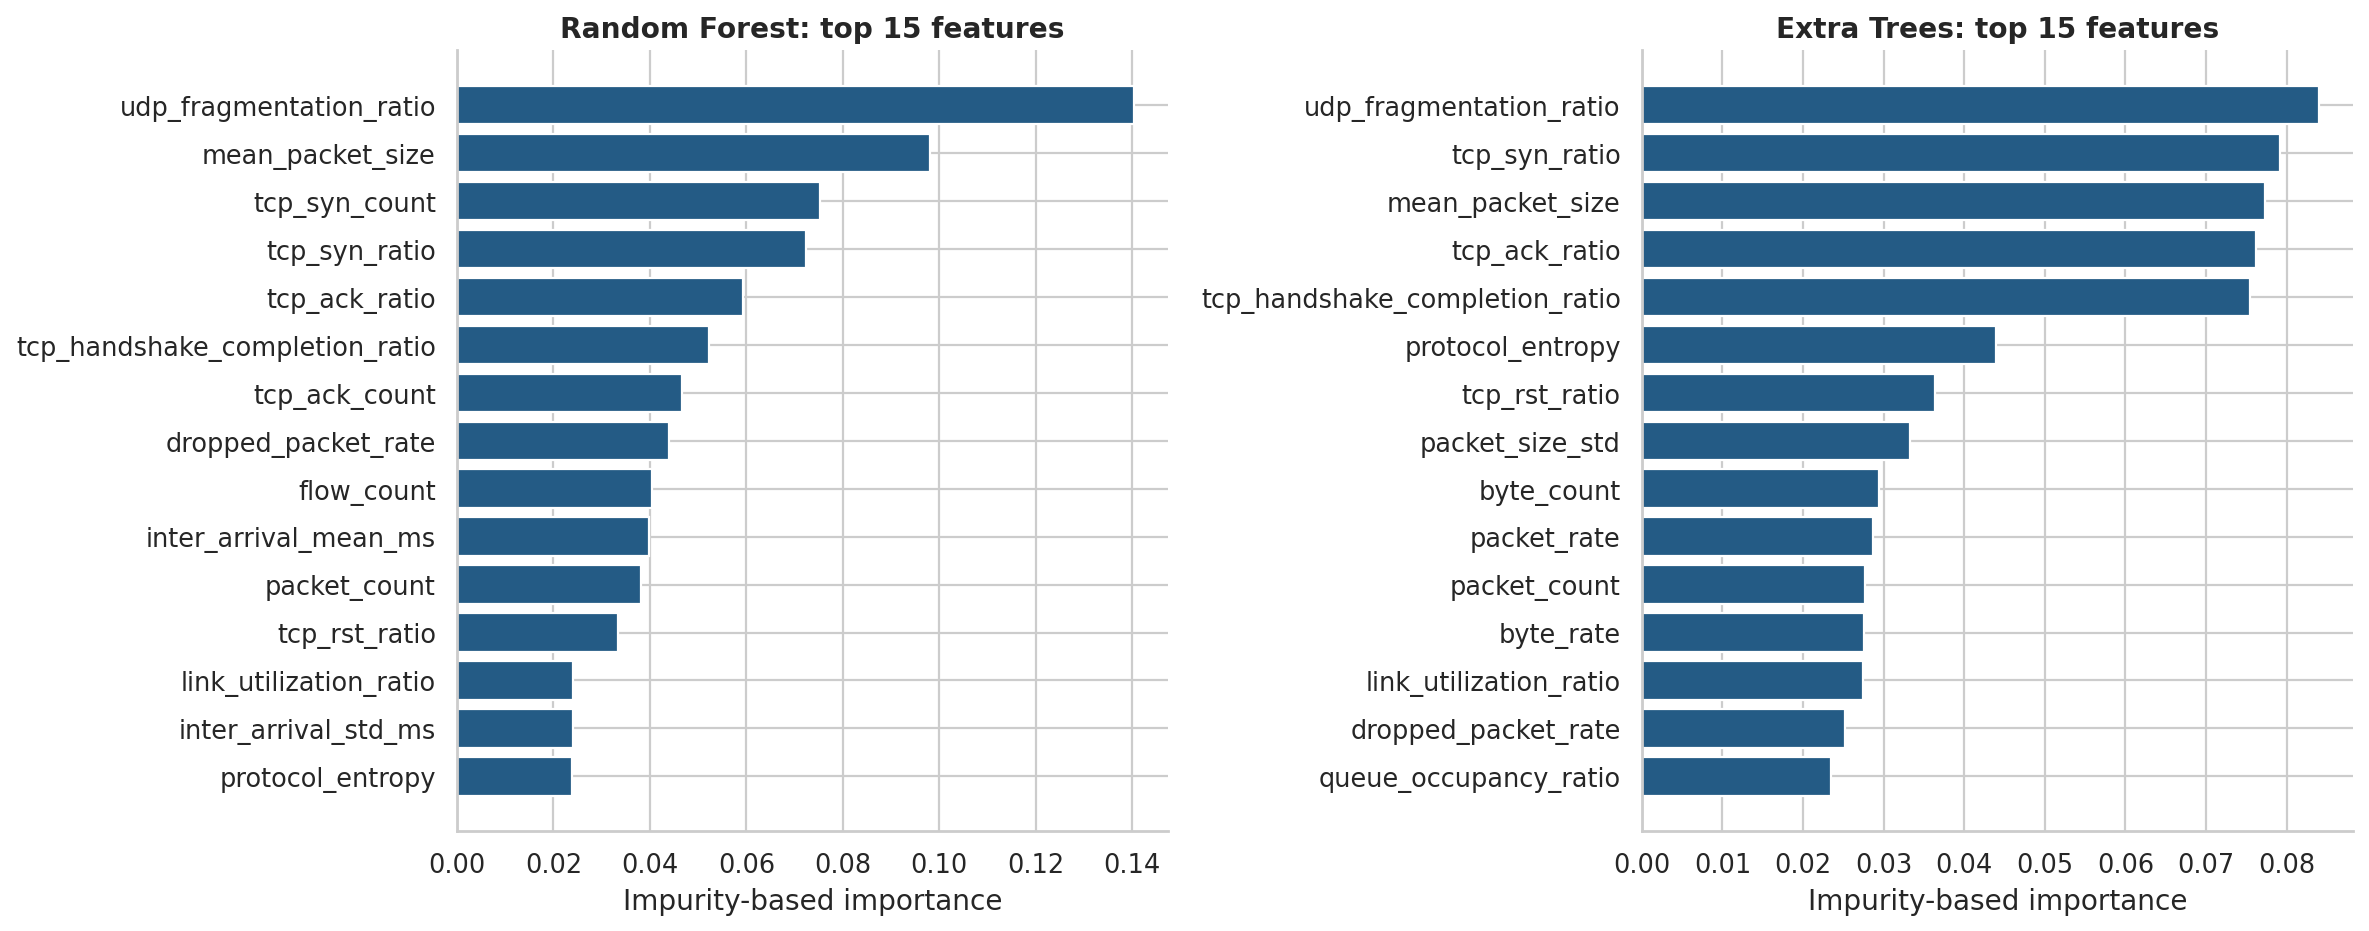

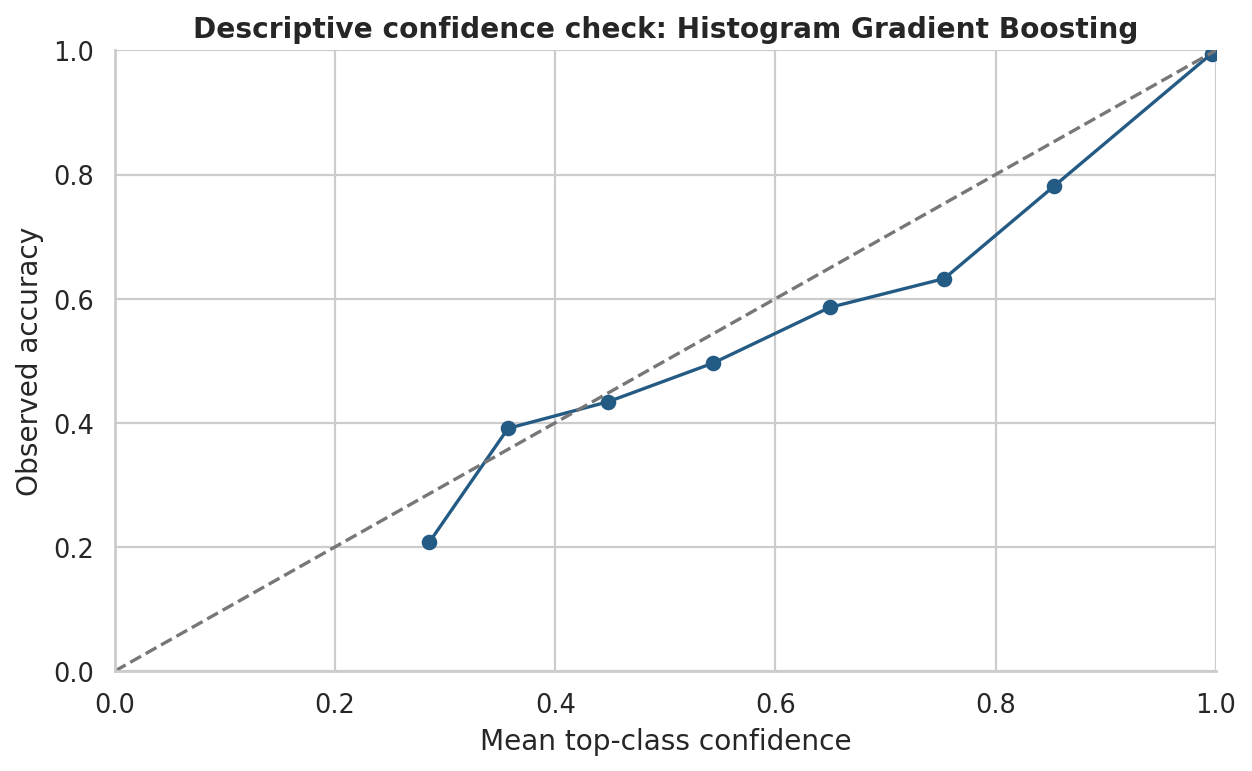

In [29]:
show_figure('15_feature_importance')
show_figure('16_reliability')

## 10. Turning class predictions into operational evidence

For probability-producing models, attack score is $1-P(BENIGN)$, a model estimate rather than a measured
attack probability. For SVM, use the negative benign margin as a ranking score. ROC and precision-recall
curves assess this binary question separately from 13-class classification.

For every model, select a threshold using validation data: maximize attack recall subject to at most
1% benign false alarms on that validation set. Freeze it, then report test false alarms and missed attacks.
With only 450 benign validation windows, a 1% requirement is coarse; it is not a deployment guarantee.
The balanced synthetic dataset's high attack prevalence can make PR results look very favorable.

,threshold,score_kind,validation_fpr_limit,test_attack_recall,test_benign_fpr,tn,fp,fn,tp
Logistic Regression,0.817399,uncalibrated probability estimate,0.01,0.999815,0.0,450,0,1,5399
Decision Tree,1.0,uncalibrated probability estimate,0.01,1.0,0.0,450,0,0,5400
Random Forest,0.92479,uncalibrated probability estimate,0.01,0.99963,0.0,450,0,2,5398
Gaussian Naive Bayes,1.0,uncalibrated probability estimate,0.01,1.0,0.0,450,0,0,5400
Multilayer Perceptron,0.955002,uncalibrated probability estimate,0.01,0.999815,0.0,450,0,1,5399
K Nearest Neighbors,0.685215,uncalibrated probability estimate,0.01,0.999815,0.0,450,0,1,5399
RBF Support Vector Machine,-11.293132,negative benign SVM margin,0.01,1.0,0.0,450,0,0,5400
Extra Trees,0.835,uncalibrated probability estimate,0.01,1.0,0.0,450,0,0,5400
Histogram Gradient Boosting,0.999364,uncalibrated probability estimate,0.01,0.999259,0.0,450,0,4,5396


,model,metric,events,denominator,estimate,wilson_95_low,wilson_95_high
0,Logistic Regression,benign_fpr,0,450,0.000000,0.000000,0.008464
1,Logistic Regression,attack_recall,5399,5400,0.999815,0.998952,0.999967
2,Decision Tree,benign_fpr,0,450,0.000000,0.000000,0.008464
3,Decision Tree,attack_recall,5400,5400,1.000000,0.999289,1.000000
4,Random Forest,benign_fpr,0,450,0.000000,0.000000,0.008464
5,Random Forest,attack_recall,5398,5400,0.999630,0.998650,0.999898
6,Gaussian Naive Bayes,benign_fpr,0,450,0.000000,0.000000,0.008464
7,Gaussian Naive Bayes,attack_recall,5400,5400,1.000000,0.999289,1.000000
8,Multilayer Perceptron,benign_fpr,0,450,0.000000,0.000000,0.008464
9,Multilayer Perceptron,attack_recall,5399,5400,0.999815,0.998952,0.999967


,model,attack_recall_argmax,benign_fpr_argmax,attack_roc_auc,attack_average_precision,tn,fp,fn,tp
0,Histogram Gradient Boosting,1.0,0.0,1.0,1.0,450,0,0,5400
1,Random Forest,1.0,0.0,1.0,1.0,450,0,0,5400
2,Multilayer Perceptron,1.0,0.0,1.0,1.0,450,0,0,5400
3,RBF Support Vector Machine,1.0,0.0,1.0,1.0,450,0,0,5400
4,Decision Tree,1.0,0.0,1.0,1.0,450,0,0,5400
5,Extra Trees,1.0,0.0,1.0,1.0,450,0,0,5400
6,Logistic Regression,1.0,0.0,1.0,1.0,450,0,0,5400
7,K Nearest Neighbors,1.0,0.0,1.0,1.0,450,0,0,5400
8,Gaussian Naive Bayes,1.0,0.0,1.0,1.0,450,0,0,5400


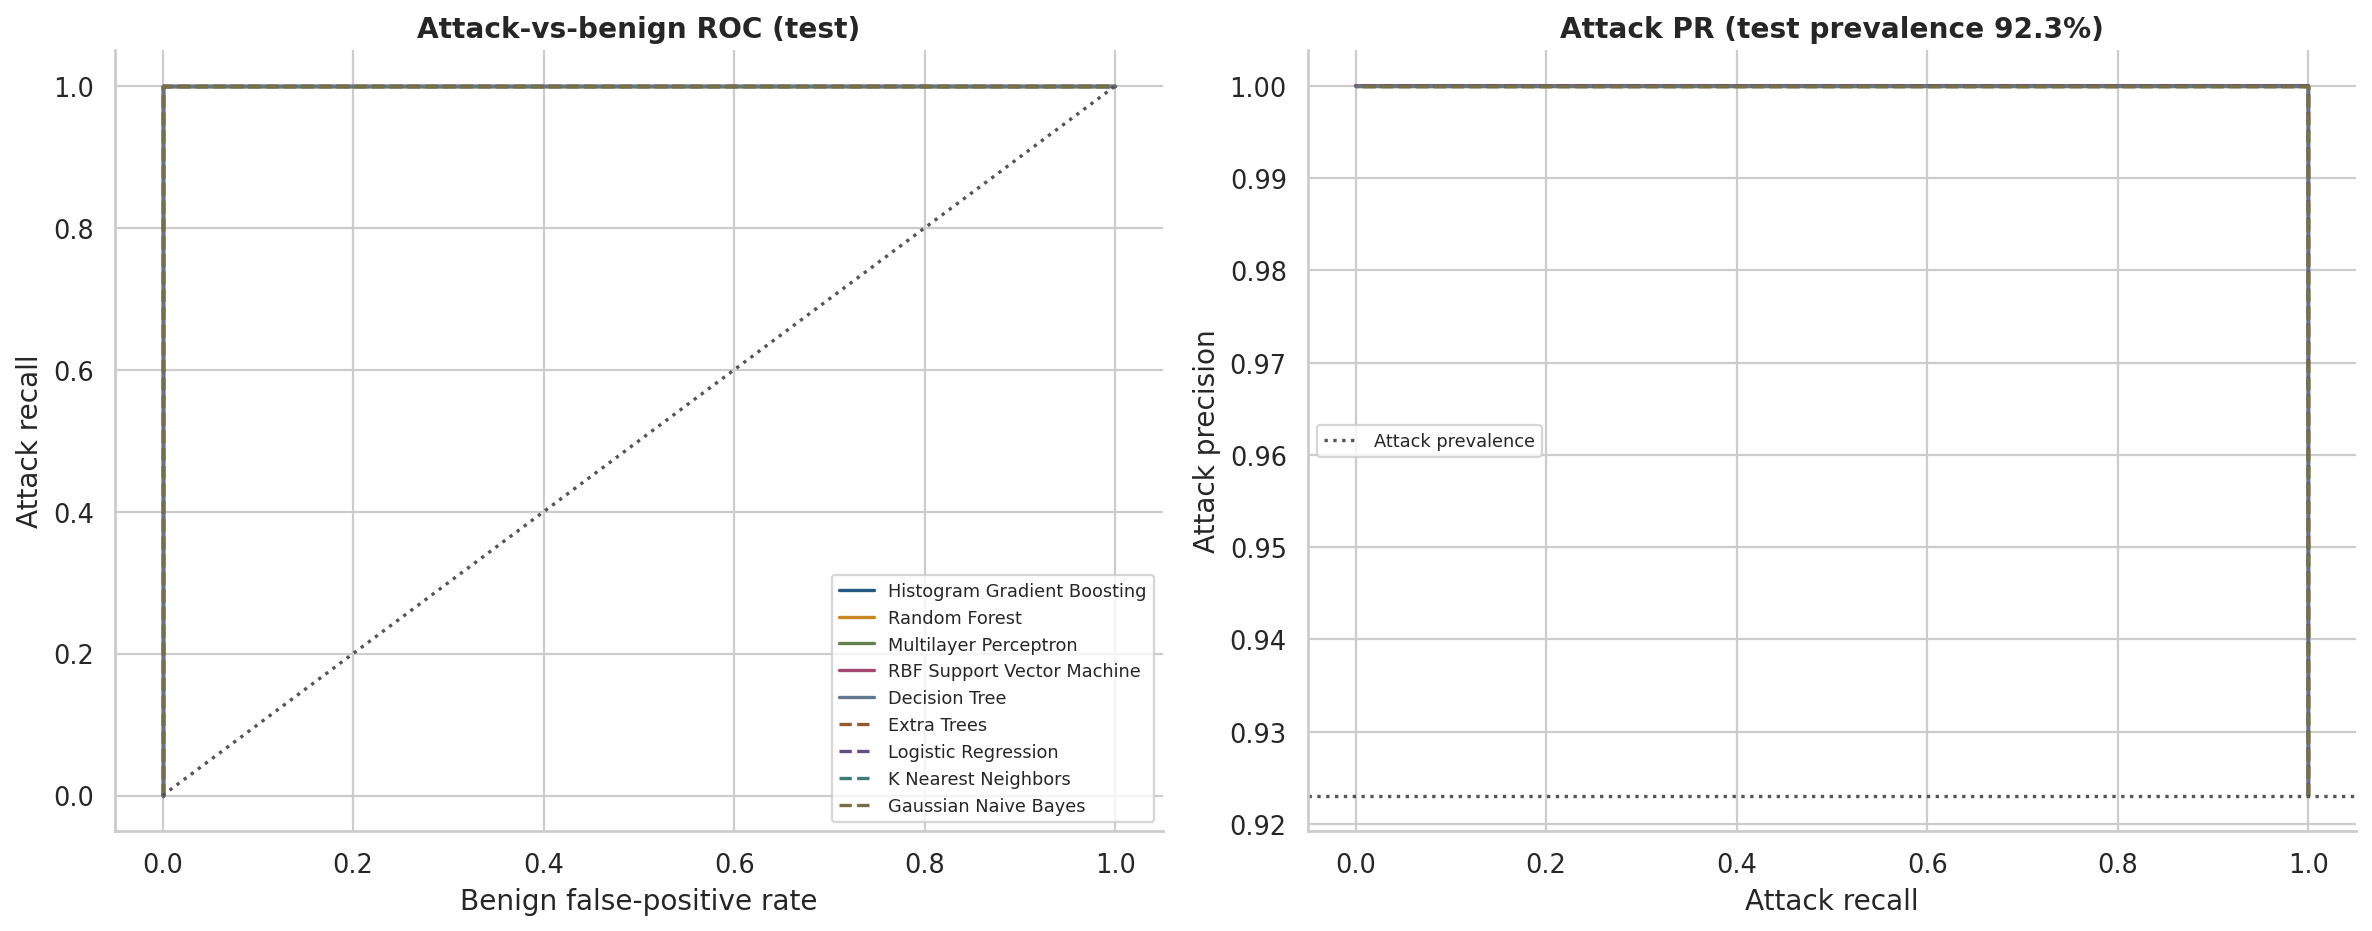

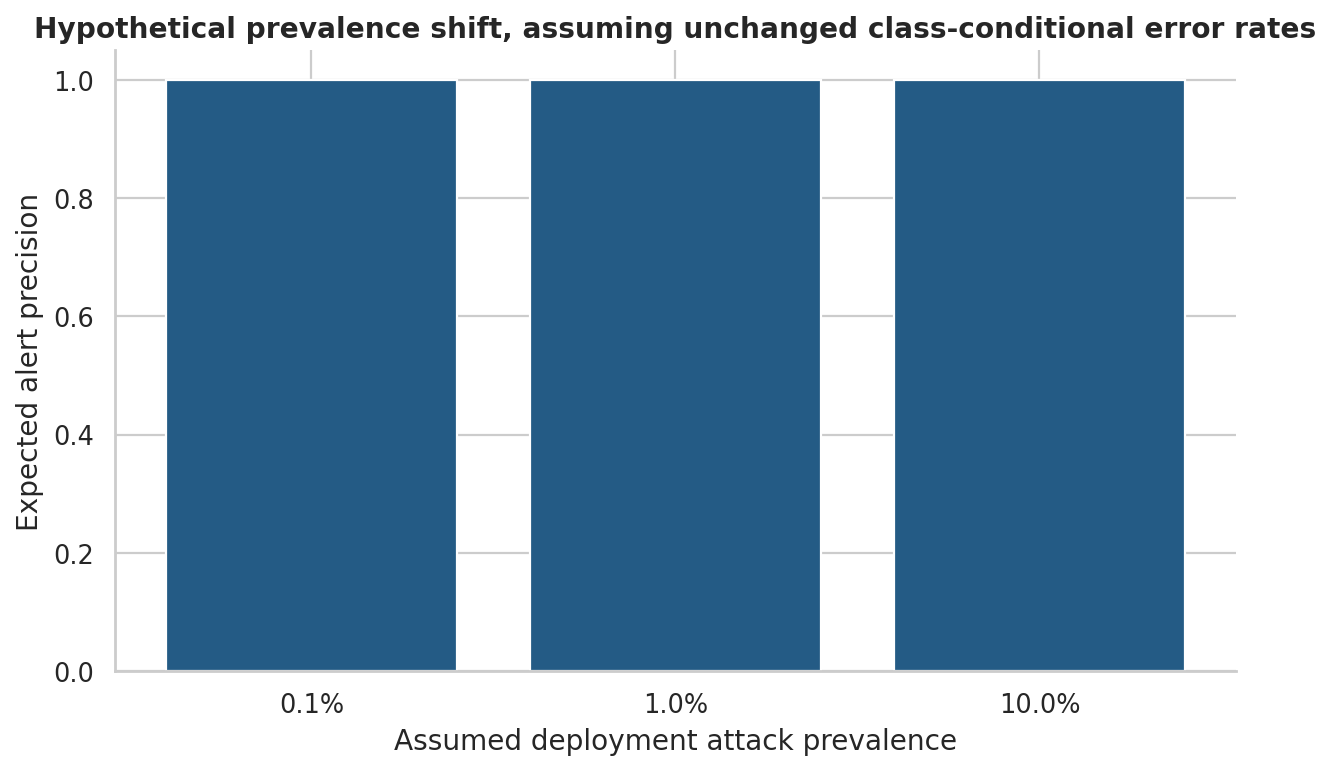

,model,assumed_attack_prevalence,expected_alert_precision,expected_false_alarms_per_10000,expected_missed_attacks_per_10000
24,Histogram Gradient Boosting,0.001,1.0,0.0,0.007407
25,Histogram Gradient Boosting,0.010,1.0,0.0,0.074074
26,Histogram Gradient Boosting,0.100,1.0,0.0,0.740741


In [30]:
operations = json.loads((RUN_DIR/'operating_points.json').read_text())
display(pd.DataFrame(operations).T)
display(pd.read_csv(RUN_DIR/'operating_uncertainty.csv').round(6))
display(metrics[['model','attack_recall_argmax','benign_fpr_argmax','attack_roc_auc','attack_average_precision','tn','fp','fn','tp']].round(5))
show_figure('13_roc_pr')
show_figure('17_prevalence')
display(pd.read_csv(RUN_DIR/'prevalence_scenarios.csv').query('model == @winner'))

**Finite-sample uncertainty:** the table includes 95% Wilson intervals for binary recall
and false-positive rates. Zero false positives among 450 benign test windows does not establish
a zero population FPR; its Wilson upper endpoint is about 0.85%. The prevalence scenarios use
point estimates and assume unchanged class-conditional errors. They are hypothetical, not measured
deployment precision. These intervals concern individual windows under the evaluation distribution,
not independent capture sessions or a shifted real network.

### 10.1 Output contract and policy example

A useful prediction record contains **window ID, model/version, feature-schema version, predicted class,
attack score, score type, validation-selected threshold, timestamp and routing context**. Keep switch/port
identity for routing the alert; it was excluded from learned features. The current example table carries
available offline context and is not a complete live telemetry event implementation.

Suggested flow: aggregate telemetry → validate schema → apply saved preprocessing → run saved model →
produce score and class → request corroborating per-flow telemetry → alert or temporarily rate-limit
specific verified traffic according to policy. Escalate repeated, corroborated high-risk windows with
expiry and rollback. A class label alone cannot identify the offending flow or safely justify blocking
an entire shared ingress port. This notebook sends no controller commands.

The saved examples deliberately include errors where available. A confident wrong subtype is a reason
to inspect evidence, not to invent a more precise enforcement rule.

In [31]:
examples = pd.read_csv(RUN_DIR/'inference_examples.csv')
display(examples)

,window_id,actual,predicted,attack_score,threshold_attack,top_class_probability,switch_id,ingress_port,proposed_action,model,scope
0,v3_00_000003,BENIGN,BENIGN,0.000405,False,0.999595,s4,7,OBSERVE,Histogram Gradient Boosting,offline demonstration; no switch command sent
1,v3_08_000009,DNS_AMPLIFICATION,SSDP_AMPLIFICATION,0.999828,True,0.453674,s3,1,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent
2,v3_06_000027,HTTP_FLOOD,HTTP_FLOOD,0.999998,True,0.999668,s1,7,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent
3,v3_02_000002,ICMP_FLOOD,ICMP_FLOOD,0.999982,True,0.993196,s2,4,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent
4,v3_12_000002,MIXED_DDOS,MIXED_DDOS,0.999997,True,0.999759,s1,1,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent
5,v3_09_000016,NTP_AMPLIFICATION,SSDP_AMPLIFICATION,0.999784,True,0.328384,s6,8,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent
6,v3_07_000003,SLOW_HTTP,SLOW_HTTP,0.999997,True,0.999792,s2,4,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent
7,v3_10_000008,SSDP_AMPLIFICATION,DNS_AMPLIFICATION,0.999813,True,0.451019,s4,4,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent
8,v3_04_000005,TCP_ACK_FLOOD,TCP_ACK_FLOOD,0.999997,True,0.999760,s1,4,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent
9,v3_05_000009,TCP_RST_FLOOD,TCP_RST_FLOOD,0.999997,True,0.999772,s2,5,ALERT_AND_REQUEST_CORROBORATION,Histogram Gradient Boosting,offline demonstration; no switch command sent


### 10.2 Reusing the saved estimator

Spark models are stored as native `.spark` directories; Python models use `.joblib` files.
The fitted Spark preprocessing is saved independently, along with a portable numeric transform.
`feature_contract.json` preserves feature order and the numeric-index-to-label mapping.
Always run the saved preprocessing; fitting a new scaler at inference changes the model input space.
The selected estimator was reloaded and checked against all held-out predictions.

For an unseen batch containing the required feature columns:
```python
from bda.serving import Predictor
predictor = Predictor(RUN_DIR)  # starts Spark only for a Spark-selected estimator
output = predictor.predict(new_windows)
predictor.close()
```
Pass `model_name='Random Forest'` (or any other recorded algorithm name) to inspect
that estimator instead of the validation-selected default.
Missing required columns fail with a clear schema error; present null cells use saved training medians.
Scores are estimates within the training distribution. New capture feature definitions must match the
contract or trigger retraining rather than silently reuse an incompatible estimator.

In [32]:
from bda.serving import Predictor
predictor = Predictor(RUN_DIR)
try:
    inference = predictor.predict(df.sample(5, random_state=42))
    display(inference)
finally:
    predictor.close()

,predicted_class,attack_score,score_type,threshold,attack_alert,model,training_commit,scope,top_class_probability,window_id,timestamp_utc,switch_id,ingress_port
0,TCP_SYN_FLOOD,0.999997,uncalibrated probability estimate,0.999364,True,Histogram Gradient Boosting,a31923aeb632848718453d9f3156220e96746957,offline model evidence; corroborate before enf...,0.999787,v3_03_001873,2026-01-02T06:12:10+00:00,s2,2
1,NTP_AMPLIFICATION,0.999840,uncalibrated probability estimate,0.999364,True,Histogram Gradient Boosting,a31923aeb632848718453d9f3156220e96746957,offline model evidence; corroborate before enf...,0.512853,v3_09_000504,2026-01-04T04:24:00+00:00,s4,2
2,MIXED_DDOS,0.999997,uncalibrated probability estimate,0.999364,True,Histogram Gradient Boosting,a31923aeb632848718453d9f3156220e96746957,offline model evidence; corroborate before enf...,0.999765,v3_12_001607,2026-01-05T08:27:50+00:00,s4,8
3,SSDP_AMPLIFICATION,0.999838,uncalibrated probability estimate,0.999364,True,Histogram Gradient Boosting,a31923aeb632848718453d9f3156220e96746957,offline model evidence; corroborate before enf...,0.466815,v3_10_001725,2026-01-04T16:07:30+00:00,s3,8
4,UDP_FLOOD,0.999926,uncalibrated probability estimate,0.999364,True,Histogram Gradient Boosting,a31923aeb632848718453d9f3156220e96746957,offline model evidence; corroborate before enf...,0.785065,v3_01_002140,2026-01-01T14:16:40+00:00,s3,3


## 11. Three-person presentation split

| Member | Algorithms | Shared responsibility |
|---|---|---|
| Satya | Logistic Regression, Decision Tree, Random Forest | dataset validity, Spark pipeline, validation selection |
| Prithvi | Gaussian Naive Bayes, MLP, RBF SVM | assumptions, scaling, probabilities versus margins |
| Roydon | KNN, Extra Trees, Histogram Gradient Boosting | runtime, error analysis, inference and alert policy |

For each algorithm explain: input vector → training mechanism → prediction mechanism → validation
choice → test result → weakest class → runtime cost → appropriate output use. Everyone should be able
to explain the shared split and why this synthetic experiment cannot establish real deployment quality.

## 12. Final findings and next experiment

The following text is computed from executed artifacts rather than filled in before training.

In [33]:
selected = metrics[metrics.model == winner].iloc[0]
worst = per_class[per_class.model == winner].nsmallest(3,'recall')
bench = timings.groupby('engine').seconds.median()
display(Markdown(f"The validation-selected model is **{winner}** (validation macro F1 **{selected.validation_macro_f1:.4f}**). "
                 f"Its fixed test macro F1 is **{selected.f1_macro:.4f}**, accuracy **{selected.accuracy:.2%}**. "
                 f"The lowest-recall test classes are **{', '.join(worst['class'])}**. "
                 f"Median completed aggregation time: Pandas **{bench['Pandas']:.3f}s**, Spark **{bench['Spark']:.3f}s**, "
                 "excluding Spark startup. These measurements apply to this machine and this synthetic dataset."))

The validation-selected model is **Histogram Gradient Boosting** (validation macro F1 **0.8167**). Its fixed test macro F1 is **0.8116**, accuracy **81.76%**. The lowest-recall test classes are **UDP_AMPLIFICATION, SSDP_AMPLIFICATION, DNS_AMPLIFICATION**. Median completed aggregation time: Pandas **0.075s**, Spark **1.434s**, excluding Spark startup. These measurements apply to this machine and this synthetic dataset.

**What remains:** independent packet/flow-derived measured telemetry with repeated capture sessions,
diverse benign services, no hardcoded-zero controller observations masquerading as measurements,
verified counter/feature units, session-separated testing, drift and calibration evaluation, realistic
attack prevalence, and full telemetry-to-controller latency/false-alarm measurement. The newer
`sdn_ddos` capture project remains separate; phase 2 supplies the improved dataset before retraining.

**Authoritative references and what to read:**
- [Spark classification guide](https://spark.apache.org/docs/3.5.6/ml-classification-regression.html):
  algorithm assumptions, multiclass support and prediction outputs. Map these to the five Spark estimators.
- [Spark feature guide](https://spark.apache.org/docs/3.5.6/ml-features.html): `Imputer`, `VectorAssembler`,
  `StandardScaler`; understand fitted statistics and transformer reuse.
- [scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html): split before fitting
  transformations; identify leakage in an apparently successful notebook.
- [scikit-learn ensemble guide](https://scikit-learn.org/stable/modules/ensemble.html): Extra Trees and
  histogram boosting; distinguish randomized independent trees from sequential corrections.
- [SVC API](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html): margins,
  multiclass strategy, `C`, `gamma`, and the extra cost/meaning of probability estimation.

All saved tables, figures and prediction files belong to the run ID and dataset hash shown above.
The read-only artifact-review mode reuses those results explicitly; a new training run creates a new run ID.